CIRCUITS (arm A uses wires A,E1 ; arm B uses wires B,E2 ; pA* / pB* = parameters of arm A / B)

--- PCCM: 1 parameter(s) per arm, same block on both arms ---
  source |Phi+>_AB : A,B entangled;  Eve ancillas E1,E2 start in |0>
  A  ───RX(π/2)────────●─────────RY(-π)─────RX(-π/2)──────────────
  E1 ───────────────RY(pA0)────────●────────────────────RX(-π/2)──
  B  ───RX(π/2)────────●─────────RY(-π)─────RX(-π/2)──────────────
  E2 ───────────────RY(pB0)────────●────────────────────RX(-π/2)──
  then: Alice/Bob measure Z or X; Eve: identity readout, H for X basis, Bayes decision on (e1,e2)

--- QCL: 12 parameter(s) per arm, same block on both arms ---
  source |Phi+>_AB : A,B entangled;  Eve ancillas E1,E2 start in |0>
  A  ───RX(pA0)─────RY(pA1)─────RZ(pA2)────────────────────────────────────────────●────────RX(pA6)─────RY(pA7)─────RZ(pA8)────────────────────────────────────────────●──────
  E1 ───────────────────────────────────────RX(pA3)─────RY(pA4)─────RZ(pA5)────────⊕────────────────

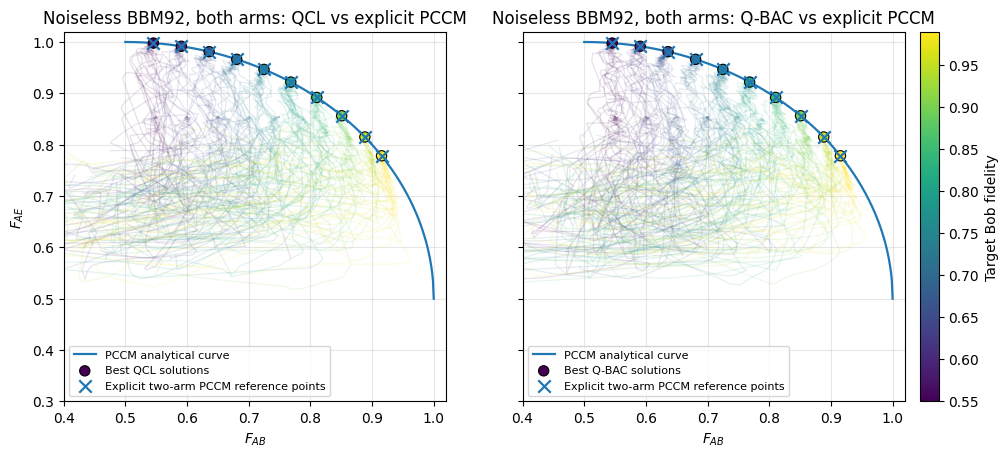


Total time 366s;  figure saved to bbm92_two_arm_validation.png


In [ ]:
# =====================================================================================================
# BBM92 (entanglement based, trusted |Phi+> source, Z/X bases, NO noise)
# Eve attacks BOTH arms with three circuits: PCCM (textbook), QCL, Q-BAC  - 10 target fidelities.
# Colab ready: only needs jax, numpy, scipy, pandas, matplotlib (all pre-installed on Colab).
#
#   source  : |Phi+>_AB = (|00>+|11>)/sqrt2   -> Alice's flying qubit A, Bob's flying qubit B
#   Eve     : one 2-qubit block on (A,E1) and one 2-qubit block on (B,E2); ancillas E1,E2 start in |0>
#             (same block type on both arms; QCL/Q-BAC blocks keep their notebook gate layout)
#   measure : Alice and Bob measure Z or X; Eve reads each ancilla (trained rotation V, H for X)
#             and guesses Alice's bit with the Bayes-optimal joint decision on (e1,e2)
#   loss    : 10 (F_AB - f)^2 - F_AE  (+ 1000 x marginal bias, because Alice/Bob would see a biased bit)
# =====================================================================================================
import time, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128

TARGETS   = [0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]   # 10 target F_AB values
RESTARTS  = 16            # random L-BFGS restarts per (model, target)
MARG_W    = 1000.0        # penalty on Alice/Bob marginal bias
GAIN_TOL  = 1e-3          # a model "matches PCCM" if its loss is within this of PCCM's
SEED      = 0

# ------------------------------------------------------------------ gates
I2 = jnp.eye(2, dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):          # controlled-U1 on 2 wires, control c, target t (wire 0 is the left factor)
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
XG = jnp.array([[0, 1], [1, 0]], dtype=CD)

# ------------------------------------------------------------------ circuit descriptions (ONE source of truth:
# the same op list is simulated and printed).  op = (gate, wires, angle) ; angle = ('p', idx) | ('c', value) | None
# local wire 0 = flying qubit (Alice's or Bob's), local wire 1 = Eve's ancilla.  Same layout as the notebook.
PI = float(np.pi)
def ops_pccm():                                   # 1 parameter (index 0)
    return [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)),
            ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))]
def ops_qcl():                                    # 12 parameters, 2 layers of (RZ RY RX on both wires) + CNOT
    ops = []
    for L in range(2):
        for q in range(2):
            for k, g in enumerate(["RX", "RY", "RZ"]): ops.append((g, (q,), ('p', L*6 + q*3 + k)))
        ops.append(("CNOT", (0, 1), None))
    return ops
def ops_qbac():                                   # 12 parameters, controlled-rotation (CRY/CRZ) ansatz
    return [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)),
            ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)), ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None),
            ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
            ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]
MODELS = {"PCCM": (ops_pccm(), 1), "QCL": (ops_qcl(), 12), "Q-BAC": (ops_qbac(), 12)}

def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ:  G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY":  G = ctrl(RY(th), *w)
        elif g == "CRZ":  G = ctrl(RZ(th), *w)
        U = G @ U
    return U

for _n, (_o, _k) in MODELS.items():      # sanity: every block must be unitary
    _U = block_unitary(_o, jnp.linspace(0.3, 2.1, max(_k, 1))); assert float(jnp.abs(_U.conj().T @ _U - jnp.eye(4)).max()) < 1e-12, _n

# ------------------------------------------------------------------ BBM92 state and statistics
# state order for the 4 qubits: (A, B, E1, E2)
PHI  = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD))
def attack_state(UA, UB):
    """Apply block UA on (A,E1) and UB on (B,E2) to |Phi+>_AB|00>_E1E2."""
    t = PSI0.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)          # -> (A,E1,B,E2)
    t = kr(UA, UB) @ t
    return t.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)          # -> (A,B,E1,E2)
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])                          # Eve's trained readout rotation
def basis_stats(psi, Hb, V1, V2):
    amp = (kr(Hb, Hb, Hb @ V1, Hb @ V2) @ psi).reshape(2, 2, 4); P = jnp.abs(amp) ** 2    # P[a,b,e1e2]
    q = P[0, 1].sum() + P[1, 0].sum()                       # P(a != b)
    succ = jnp.max(P.sum(1), axis=0).sum()                  # Eve: Bayes-optimal guess of Alice's bit
    return q, succ, P[1].sum(), P[:, 1].sum()               # + P(a=1), P(b=1)
def evaluate(psi, Vz1, Vz2, Vx1, Vx2, f):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(psi, I2, Vz1, Vz2), basis_stats(psi, H2, Vx1, Vx2)
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-.5)**2 + (bz-.5)**2 + (ax-.5)**2 + (bx-.5)**2
    return 10 * (fab - f) ** 2 - fae + MARG_W * bias, jnp.stack([fab, fae, qz, qx, bias])

def make_engine(name):
    ops, n = MODELS[name]
    if name == "PCCM":                                       # 2 parameters (theta_A, theta_B), identity readout
        def f_(x, f):
            return evaluate(attack_state(block_unitary(ops, x[0:1]), block_unitary(ops, x[1:2])), I2, I2, I2, I2, f)
        return 2, jax.jit(jax.value_and_grad(f_, has_aux=True)), jax.jit(f_)
    def f_(x, f):                                            # [arm A block | arm B block | 4 readout rotations]
        UA, UB = block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]); r = x[2*n:]
        return evaluate(attack_state(UA, UB), vblock(r[0:3]), vblock(r[3:6]), vblock(r[6:9]), vblock(r[9:12]), f)
    return 2*n + 12, jax.jit(jax.value_and_grad(f_, has_aux=True)), jax.jit(f_)

# ------------------------------------------------------------------ print the three circuits
def draw(name):
    ops, n = MODELS[name]
    rows = {"A ": "", "E1": "", "B ": "", "E2": ""}; keys = list(rows)
    def lab(g, a, arm):
        if a is None: return g
        return f"{g}({'%.2g' % a[1] if a[0]=='c' else 'p'+arm+str(a[1])})".replace("3.1", "π").replace("1.6", "π/2")
    W = 11
    for g, w, a in ops:
        for arm, off in (("A", 0), ("B", 2)):
            cells = ["─" * W, "─" * W]
            if g in ONEQ:
                cells[w[0]] = lab(g, a, arm).center(W, "─")
            else:
                c, t = w if len(w) == 2 else (0, 1)
                cells[c] = "●".center(W, "─")
                cells[t] = ("⊕" if g == "CNOT" else lab(g[1:], a, arm)).center(W, "─")
            rows[keys[off]] += "─" + cells[0]; rows[keys[off+1]] += "─" + cells[1]
    print(f"\n--- {name}: {n if name!='PCCM' else 1} parameter(s) per arm, same block on both arms ---")
    print("  source |Phi+>_AB : A,B entangled;  Eve ancillas E1,E2 start in |0>")
    for k in keys: print(f"  {k} {rows[k]}─")
    tail = "identity readout" if name == "PCCM" else "trained readout V (RZ·RY·RX) on E1,E2 per basis"
    print(f"  then: Alice/Bob measure Z or X; Eve: {tail}, H for X basis, Bayes decision on (e1,e2)")
print("=" * 100); print("CIRCUITS (arm A uses wires A,E1 ; arm B uses wires B,E2 ; pA* / pB* = parameters of arm A / B)")
for m in MODELS: draw(m)

# ------------------------------------------------------------------ textbook reference
def fuchs_bound(fab): D = 1 - fab; return 0.5 + np.sqrt(np.clip(D * (1 - D), 0, None))     # (2F_B-1)^2+(2F_E-1)^2 = 1
def theory_loss(f):
    return minimize_scalar(lambda D: 10*(1-D-f)**2 - fuchs_bound(1-D), bounds=(0, .5), method='bounded',
                           options=dict(xatol=1e-12)).fun

# ------------------------------------------------------------------ PCCM on both arms: grid + polish
print("\n" + "=" * 100); print("TRAINING (noiseless BBM92)  -  targets:", TARGETS)
t_start = time.time()
nP, vgP, evP = make_engine("PCCM")
G = jnp.linspace(0, jnp.pi, 181)
gridP = jax.jit(jax.vmap(jax.vmap(lambda a, b, f: evP(jnp.array([a, b]), f)[0], (None, 0, None)), (0, None, None)))
ref = {}
for f in TARGETS:
    Lg = np.array(gridP(G, G, f)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    r = minimize(lambda x: tuple(np.asarray(v, float) for v in (lambda o: (o[0][0], o[1]))(vgP(jnp.asarray(x), f))),
                 [float(G[i]), float(G[j])], jac=True, method='L-BFGS-B', bounds=[(0, np.pi)]*2,
                 options=dict(ftol=1e-15, gtol=1e-12))
    l, aux = evP(jnp.asarray(r.x), f); ref[f] = dict(loss=float(l), fab=float(aux[0]), fae=float(aux[1]), th=r.x, bias=float(aux[4]))

# ------------------------------------------------------------------ QCL and Q-BAC on both arms (with trajectories)
rng = np.random.default_rng(SEED); res = {m: {} for m in ("QCL", "Q-BAC")}
for m in ("QCL", "Q-BAC"):
    n, vg, ev = make_engine(m)
    for f in TARGETS:
        runs = []
        for r in range(RESTARTS):
            traj = []
            def fun(x):
                (l, _), g = vg(jnp.asarray(x), f); return float(l), np.asarray(g, float)
            def cb(xk):
                _, aux = ev(jnp.asarray(xk), f); traj.append((float(aux[0]), float(aux[1])))
            x0 = rng.uniform(-np.pi, np.pi, n); cb(x0)
            o = minimize(fun, x0, jac=True, method='L-BFGS-B', callback=cb,
                         options=dict(maxiter=500, ftol=1e-14, gtol=1e-9, maxls=40))
            l, aux = ev(jnp.asarray(o.x), f)
            runs.append(dict(loss=float(l), fab=float(aux[0]), fae=float(aux[1]), bias=float(aux[4]), traj=np.array(traj), x=o.x))
        res[m][f] = dict(best=min(runs, key=lambda d: d["loss"]), runs=runs)
    print(f"  {m:6s} done   [{time.time()-t_start:.0f}s]", flush=True)

# ------------------------------------------------------------------ results table
rows = []
for f in TARGETS:
    q, b, p = res["QCL"][f]["best"], res["Q-BAC"][f]["best"], ref[f]
    rows.append({"target": f,
                 "PCCM_loss": p["loss"], "theory_loss": theory_loss(f), "QCL_loss": q["loss"], "QBAC_loss": b["loss"],
                 "QCL-PCCM": q["loss"]-p["loss"], "QBAC-PCCM": b["loss"]-p["loss"],
                 "PCCM_FAB": p["fab"], "PCCM_FAE": p["fae"], "QCL_FAB": q["fab"], "QCL_FAE": q["fae"],
                 "QBAC_FAB": b["fab"], "QBAC_FAE": b["fae"],
                 "QCL_gap_to_curve": fuchs_bound(q["fab"]) - q["fae"], "QBAC_gap_to_curve": fuchs_bound(b["fab"]) - b["fae"],
                 "PCCM_thetaA_deg": np.degrees(p["th"][0]), "PCCM_thetaB_deg": np.degrees(p["th"][1]),
                 "max_marginal_bias": max(p["bias"], q["bias"], b["bias"]),
                 "QCL_match": abs(q["loss"]-p["loss"]) < GAIN_TOL, "QBAC_match": abs(b["loss"]-p["loss"]) < GAIN_TOL})
df = pd.DataFrame(rows)
print("\n" + "=" * 100); print("RESULTS  (loss = 10(F_AB-f)^2 - F_AE ; lower = stronger attack ; negative gap = model beats PCCM)")
with pd.option_context('display.width', 250, 'display.max_columns', 40, 'display.float_format', '{:.6f}'.format):
    print(df[["target", "PCCM_loss", "theory_loss", "QCL_loss", "QBAC_loss", "QCL-PCCM", "QBAC-PCCM", "QCL_match", "QBAC_match"]].to_string(index=False))
    print(); print(df[["target", "PCCM_FAB", "PCCM_FAE", "QCL_FAB", "QCL_FAE", "QBAC_FAB", "QBAC_FAE", "PCCM_thetaA_deg", "PCCM_thetaB_deg"]].to_string(index=False))
print(f"\nPCCM (both arms) vs textbook optimum  : max |loss difference| = {np.abs(df.PCCM_loss-df.theory_loss).max():.2e}")
print(f"QCL   matches PCCM in {int(df.QCL_match.sum())}/10 targets (tol {GAIN_TOL}); worst deficit {df['QCL-PCCM'].max():.2e}; best gain {-df['QCL-PCCM'].min():.2e}")
print(f"Q-BAC matches PCCM in {int(df.QBAC_match.sum())}/10 targets (tol {GAIN_TOL}); worst deficit {df['QBAC-PCCM'].max():.2e}; best gain {-df['QBAC-PCCM'].min():.2e}")
print(f"largest marginal bias in any reported solution: {df.max_marginal_bias.max():.2e}  (0 = Alice/Bob see an unbiased bit)")

# ------------------------------------------------------------------ figure (same style as the single-model validation plot)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
cmap = plt.cm.viridis; norm = plt.Normalize(min(TARGETS), max(TARGETS)); xs = np.linspace(0.5, 1, 400)
for ax, m, lab in zip(axs, ("QCL", "Q-BAC"), ("Best QCL solutions", "Best Q-BAC solutions")):
    for f in TARGETS:
        for run in res[m][f]["runs"]:
            ax.plot(run["traj"][:, 0], run["traj"][:, 1], color=cmap(norm(f)), alpha=0.12, lw=0.9)
    ax.plot(xs, fuchs_bound(xs), color="tab:blue", lw=1.6, label="PCCM analytical curve", zorder=3)
    ax.scatter([res[m][f]["best"]["fab"] for f in TARGETS], [res[m][f]["best"]["fae"] for f in TARGETS],
               c=TARGETS, cmap=cmap, norm=norm, s=55, edgecolor="k", lw=0.8, zorder=5, label=lab)
    ax.scatter([ref[f]["fab"] for f in TARGETS], [ref[f]["fae"] for f in TARGETS], marker="x", s=80, c="tab:blue",
               lw=1.6, zorder=6, label="Explicit two-arm PCCM reference points")
    ax.set_xlim(0.4, 1.02); ax.set_ylim(0.3, 1.02); ax.grid(alpha=0.3)
    ax.set_xlabel(r"$F_{AB}$"); ax.set_title(f"Noiseless BBM92, both arms: {m} vs explicit PCCM")
    ax.legend(loc="lower left", fontsize=8)
axs[0].set_ylabel(r"$F_{AE}$")
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axs, pad=0.015); cb.set_label("Target Bob fidelity")
plt.savefig("bbm92_two_arm_validation.png", dpi=200, bbox_inches="tight"); plt.show()
RESULTS_BBM92_TWO_ARM = df
print(f"\nTotal time {time.time()-t_start:.0f}s;  figure saved to bbm92_two_arm_validation.png")

  AB1 Bob bit-flip, before Eve           done  [629s]
  AB2 Bob bit-flip, after Eve            done  [1125s]
  AB3 Bob amp-damping, before Eve        done  [1759s]
  AB4 Alice bit-flip, before Eve         done  [2296s]
  AB5 Both arms dephasing, after Eve     done  [2839s]
  AB6 Werner source (depolarizing)       done  [3331s]
  EV1 Ancilla bit-flip, before           done  [3841s]
  EV2 Ancilla bit-flip, after            done  [4497s]
  EV3 Ancilla amp-damping, after         done  [5151s]
  EV4 Ancilla dephasing, after           done  [5731s]

TABLE 1  Gain of QCL / Q-BAC over PCCM   (max over targets, and number of targets with gain > 0.001, of 5)
    group scen                          label      p  QCL_maxGain  QCL_nGain  QBAC_maxGain  QBAC_nGain
Alice-Bob  AB1       Bob bit-flip, before Eve 0.1000       0.0498          5        0.0498           5
Alice-Bob  AB1       Bob bit-flip, before Eve 0.2000       0.0996          5        0.0996           5
Alice-Bob  AB1       Bob bit-flip,

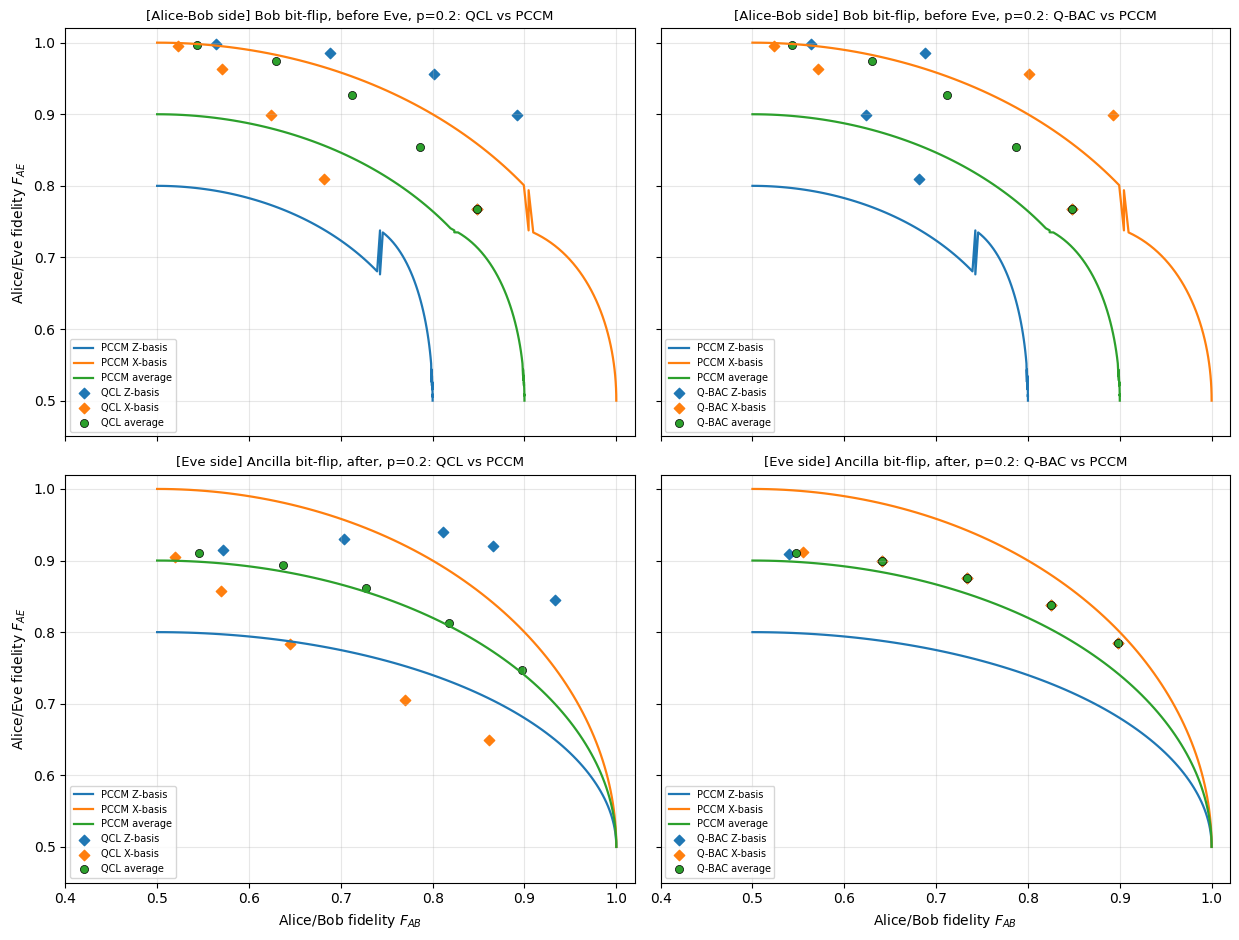

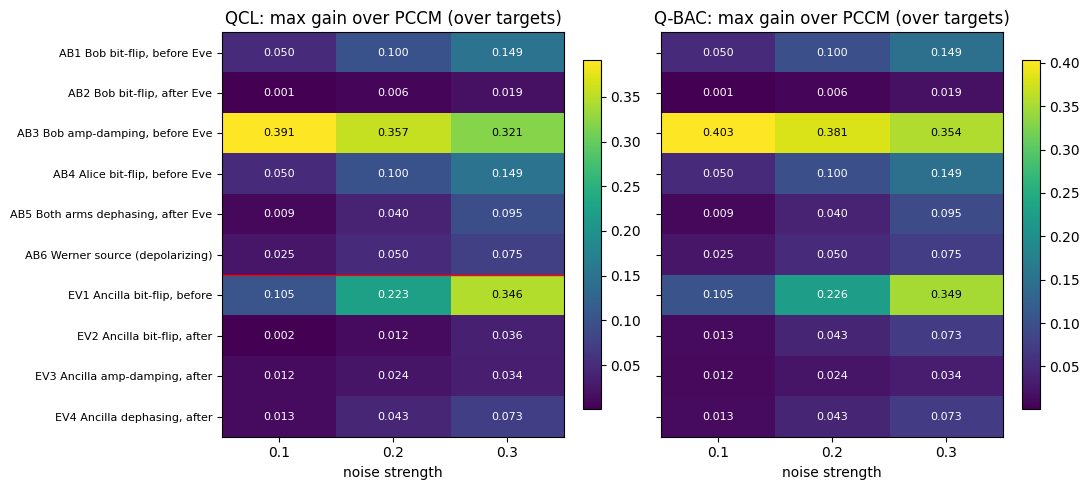

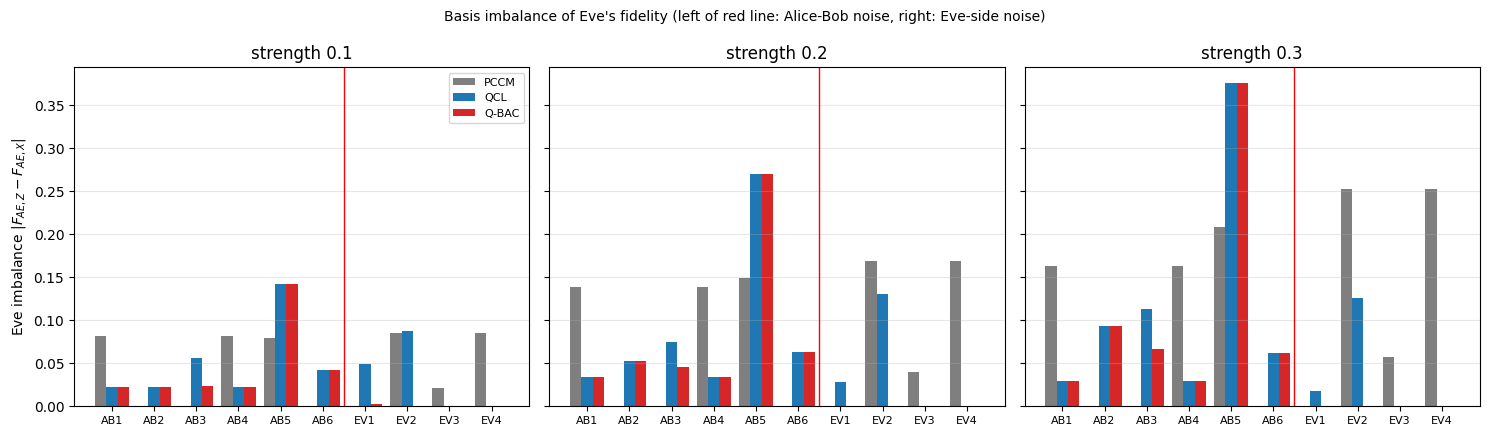


Total time 5735s. Saved: bbm92_noise_all_rows.csv, table1-4 CSVs, three PNG figures.


In [ ]:
# =====================================================================================================
# BBM92, Eve attacks BOTH arms (PCCM / QCL / Q-BAC), with NOISE.   Colab ready, one cell.
#   10 noise scenarios (6 Alice-Bob side + 4 Eve side) x strengths 0.1, 0.2, 0.3 x target fidelities
#   -> gain of QCL and Q-BAC over PCCM (total and basis-wise), basis imbalance, tables and figures.
# Needs only jax, numpy, scipy, pandas, matplotlib (pre-installed on Colab).
#
# Geometry (same as the noiseless cell): |Phi+>_AB source; Eve has one 2-qubit block on (A,E1) and one on (B,E2).
#   "pre"  = channel acts on that qubit BEFORE Eve's block (between source and Eve)
#   "post" = channel acts AFTER Eve's block (between Eve and Alice / Bob)
#   Eve-side noise acts on her ancillas E1 and E2 (pre = noisy ancilla preparation, post = decoherence before readout)
# Loss: 10 (F_AB - f)^2 - F_AE + 1000 * sum (marginal - marginal_without_attack)^2   (marginals of Alice's/Bob's bits)
#   F_AB = 1 - (Q_Z+Q_X)/2 ; F_AE = mean over bases of Eve's Bayes success on Alice's bit
# Gain  : G = L_PCCM - L_model, counted only if > 1e-3.   Basis gain: G_b = L_b(PCCM) - L_b(model),
#         L_b = 10 (F_AB,b - f)^2 - F_AE,b  (b = Z or X).   Imbalance: Imb_AB = |F_AB,Z - F_AB,X|, Imb_AE = |F_AE,Z - F_AE,X|
# PCCM = textbook gate-level cloner, 1 angle per arm, identity readout (as in the notebook); QCL/Q-BAC = notebook layouts,
#        12 parameters per arm + trained readout rotations on E1,E2 per basis (36 parameters).
# =====================================================================================================
import time, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.linalg import logm
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128

STRENGTHS = [0.1, 0.2, 0.3]
TARGETS   = [0.55, 0.65, 0.75, 0.85, 0.95]       # target F_AB values
RESTARTS  = 32                                   # random L-BFGS restarts per (model, scenario, strength, target)
MAXITER   = 400
GRID_N    = 91                                   # PCCM 2-D angle grid (per axis) before polishing
MARG_W    = 1000.0
GAIN_TOL  = 1e-3
SEED      = 0
FIG_AB, FIG_EVE, FIG_P = "AB1", "EV2", 0.2       # scenarios + strength shown in the per-basis fidelity figure
GENERAL        = True                           # ceilings: GENL = any 2-qubit block per arm (same class as QCL/Q-BAC, 42 params), run on ALL rows;
                                                #           GENJ = any joint 4-qubit unitary on (A,B,E1,E2) + joint readout (285 params), run on GEN_ rows only
GEN_STRENGTHS  = [0.2]; GEN_TARGETS = [0.75]    # rows on which the ceiling is computed (enlarge if you have time)
GEN_RESTARTS   = 3; GEN_MAXITER = 1500          # random restarts (2 warm starts from the best QCL / Q-BAC solution are always added)

# ------------------------------------------------------------------ noise scenarios
# each: (id, group, label, pre=[(slot,kind)], post=[(slot,kind)], source_depolarizing?)
# slots: A, B (Alice's / Bob's flying qubit), E (both ancillas E1,E2).   kinds: bf bit-flip, ad amplitude damping, dp dephasing
SCEN = [
 ("AB1", "Alice-Bob", "Bob bit-flip, before Eve",         [("B", "bf")], [], False),
 ("AB2", "Alice-Bob", "Bob bit-flip, after Eve",          [], [("B", "bf")], False),
 ("AB3", "Alice-Bob", "Bob amp-damping, before Eve",      [("B", "ad")], [], False),
 ("AB4", "Alice-Bob", "Alice bit-flip, before Eve",       [("A", "bf")], [], False),
 ("AB5", "Alice-Bob", "Both arms dephasing, after Eve",   [], [("A", "dp"), ("B", "dp")], False),
 ("AB6", "Alice-Bob", "Werner source (depolarizing)",     [], [], True),
 ("EV1", "Eve",       "Ancilla bit-flip, before",         [("E", "bf")], [], False),
 ("EV2", "Eve",       "Ancilla bit-flip, after",          [], [("E", "bf")], False),
 ("EV3", "Eve",       "Ancilla amp-damping, after",       [], [("E", "ad")], False),
 ("EV4", "Eve",       "Ancilla dephasing, after",         [], [("E", "dp")], False),
]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}        # state order (A, E1, B, E2)

# ------------------------------------------------------------------ gates and circuits (same as the noiseless cell)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
def ops_pccm(): return [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)),
                        ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))]
def ops_qcl():
    ops = []
    for L in range(2):
        for q in range(2):
            for k, g in enumerate(["RX", "RY", "RZ"]): ops.append((g, (q,), ('p', L*6 + q*3 + k)))
        ops.append(("CNOT", (0, 1), None))
    return ops
def ops_qbac(): return [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)),
                        ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)), ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None),
                        ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
                        ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]
MODELS = {"PCCM": (ops_pccm(), 1), "QCL": (ops_qcl(), 12), "Q-BAC": (ops_qbac(), 12)}
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ------------------------------------------------------------------ noisy BBM92 simulation (density matrix, order A,E1,B,E2)
PHI  = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)
RHO_PURE = jnp.outer(PSI0, PSI0.conj())
P00 = jnp.diag(jnp.array([1, 0], dtype=CD))
RHO_MIX = kr(I2/2, P00, I2/2, P00)               # maximally mixed A,B ; |0><0| on E1,E2
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]   # amp damp
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB) if UB is not None else UA; rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def stats_from(Wm, rho):
    d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)        # P[a,b,e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def basis_stats(rho, Hb, V1, V2): return stats_from(kr(Hb, Hb @ V1, Hb, Hb @ V2), rho)
def score(rho, V, f, base):
    return score_from(basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3]), f, base)
def score_from(sz_, sx_, f, base):
    (qz, sz, az, bz), (qx, sx, ax, bx) = sz_, sx_
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2
    return 10 * (fab - f) ** 2 - fae + MARG_W * bias, jnp.stack([1-qz, sz, 1-qx, sx, bias])     # Fab_Z,Fae_Z,Fab_X,Fae_X,bias

P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]])]
PAU4_np = np.stack([np.kron(np.kron(np.kron(a, b), c), d) for a, b, c, d in itertools.product(P1, repeat=4)][1:])   # 255, order (A,E1,B,E2)
PAU2_np = np.stack([np.kron(a, b) for a, b in itertools.product(P1, repeat=2)][1:])                                 # 15
PAU4, PAU2 = jnp.asarray(PAU4_np, dtype=CD), jnp.asarray(PAU2_np, dtype=CD)
jexpm = jax.scipy.linalg.expm
def embed_readout(R):                                  # 4x4 rotation on (E1,E2) -> 16x16 on (A,E1,B,E2)
    return jnp.einsum('ag,bh,cdef->acbdgehf', jnp.eye(2, dtype=CD), jnp.eye(2, dtype=CD), R.reshape(2, 2, 2, 2)).reshape(16, 16)
def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):                                  # marginals of Alice's/Bob's bits with NO attack, same noise
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2):
            _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    Iv = [I2] * 4
    def pccm(x, f, p, base):
        U = [block_unitary(MODELS["PCCM"][0], x[i:i+1]) for i in (0, 1)]
        return score(sim(U[0], U[1], p), Iv, f, base)
    def gen(name):
        ops, n = MODELS[name]
        def fn(x, f, p, base):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            return score(sim(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), p), V, f, base)
        return fn
    eng = {"base": jax.jit(base_marg),
           "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, f, p, base: pccm(jnp.array([a, b]), f, p, base),
                                                  (None, 0, None, None, None)), (0, None, None, None, None)))}
    for m in ("QCL", "Q-BAC"): eng[m] = jax.jit(jax.value_and_grad(gen(m), has_aux=True))
    def pccmv(x, f, p, base):                          # PCCM angles + the same trained readout that QCL / Q-BAC have
        U = [block_unitary(MODELS["PCCM"][0], x[i:i+1]) for i in (0, 1)]; V = [vblock(x[2+3*i:5+3*i]) for i in range(4)]
        return score(sim(U[0], U[1], p), V, f, base)
    eng["PCCMV"] = jax.jit(jax.value_and_grad(pccmv, has_aux=True))
    def general(x, f, p, base):                        # ceiling: ANY unitary on (A,E1,B,E2) + ANY joint readout per basis
        U = jexpm(-1j * jnp.tensordot(x[:255].astype(CD), PAU4, axes=1))
        Rz = jexpm(-1j * jnp.tensordot(x[255:270].astype(CD), PAU2, axes=1)); Rx = jexpm(-1j * jnp.tensordot(x[270:285].astype(CD), PAU2, axes=1))
        rho = sim(U, None, p)
        return score_from(stats_from(embed_readout(Rz), rho), stats_from(kr(H2, I2, H2, I2) @ embed_readout(Rx), rho), f, base)
    eng["GENJ"] = jax.jit(jax.value_and_grad(general, has_aux=True))
    def general_local(x, f, p, base):                  # ceiling for the arm-local class: ANY 2-qubit unitary per arm + trained readouts
        UA = jexpm(-1j * jnp.tensordot(x[:15].astype(CD), PAU2, axes=1)); UB = jexpm(-1j * jnp.tensordot(x[15:30].astype(CD), PAU2, axes=1))
        V = [vblock(x[30+3*i:33+3*i]) for i in range(4)]
        return score(sim(UA, UB, p), V, f, base)
    eng["GENL"] = jax.jit(jax.value_and_grad(general_local, has_aux=True))
    return eng
def warm_local(name, xb):                              # same warm start for the arm-local ceiling (42 parameters)
    ops, n = MODELS[name]; out = []
    for blk in (xb[:n], xb[n:2*n]):
        Hm = 1j * logm(np.asarray(block_unitary(ops, blk))); Hm = (Hm + Hm.conj().T) / 2; out.append(np.real(np.einsum('kij,ji->k', PAU2_np, Hm)) / 4)
    return np.concatenate(out + [xb[2*n:]])
def warm_general(name, xb):                            # Hermitian generator + readout generators of a trained QCL / Q-BAC attack
    ops, n = MODELS[name]
    U = np.kron(np.asarray(block_unitary(ops, xb[:n])), np.asarray(block_unitary(ops, xb[n:2*n])))
    Hm = 1j * logm(U); Hm = (Hm + Hm.conj().T) / 2; c = np.real(np.einsum('kij,ji->k', PAU4_np, Hm)) / 16
    V = [np.asarray(vblock(xb[2*n+3*i:2*n+3*i+3])) for i in range(4)]; out = [c]
    for R in (np.kron(V[0], V[1]), np.kron(np.asarray(H2) @ V[2], np.asarray(H2) @ V[3])):
        Hr = 1j * logm(R); Hr = (Hr + Hr.conj().T) / 2; out.append(np.real(np.einsum('kij,ji->k', PAU2_np, Hr)) / 4)
    return np.concatenate(out)

# ------------------------------------------------------------------ run everything
def pareto(th_grid, F):                                # non-dominated PCCM points (max F_AE for given F_AB)
    pts = sorted(F, key=lambda r: -r[0]); best = -1; keep = []
    for r in pts:
        if r[1] > best + 1e-12: keep.append(r); best = r[1]
    return np.array(keep)
rng = np.random.default_rng(SEED); G = jnp.linspace(0, jnp.pi, GRID_N)
rows, front, pts, BESTX = [], {}, {}, {}
t0 = time.time()
for sid, group, label, pre, post, src in SCEN:
    eng = make_engines(make_sim(pre, post, src))
    for p in STRENGTHS:
        base = eng["base"](p); pj = jnp.asarray(p)
        # ---- PCCM: full 2-D grid per target; also keep its non-dominated per-basis curve for the figure
        gl_all = None
        for f in TARGETS:
            Lg, Ag = eng["pccm_grid"](G, G, f, pj, base); Lg = np.array(Lg); Ag = np.array(Ag)
            i, j = np.unravel_index(Lg.argmin(), Lg.shape)
            o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), f, pj, base)),
                         [float(G[i]), float(G[j])], jac=True, method='L-BFGS-B', bounds=[(0, np.pi)]*2,
                         options=dict(ftol=1e-15, gtol=1e-12))
            (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), f, pj, base)
            res = {"PCCM": (float(l), np.asarray(aux))}
            if f == TARGETS[0] and gl_all is None:
                flat = Ag.reshape(-1, 5); front[(sid, p)] = pareto(None, [((r[0]+r[2])/2, (r[1]+r[3])/2, r[0], r[1], r[2], r[3]) for r in flat])
                gl_all = True
            for m in ("QCL", "Q-BAC"):
                n = MODELS[m][1]*2 + 12; vg = eng[m]; best = None
                for r_ in range(RESTARTS):
                    o2 = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(vg(jnp.asarray(x), f, pj, base)),
                                  rng.uniform(-np.pi, np.pi, n), jac=True, method='L-BFGS-B',
                                  options=dict(maxiter=MAXITER, ftol=1e-13, gtol=1e-9, maxls=40))
                    if best is None or o2.fun < best.fun: best = o2
                (l2, aux2), _ = vg(jnp.asarray(best.x), f, pj, base); res[m] = (float(l2), np.asarray(aux2)); BESTX[m] = best.x
            # PCCM with trained readout: separates 'better circuit' from 'better readout'
            bv = None
            for r_ in range(RESTARTS + 1):
                x0 = np.concatenate([o.x, np.zeros(12)]) if r_ == 0 else np.concatenate([rng.uniform(0, np.pi, 2), rng.uniform(-np.pi, np.pi, 12)])
                o3 = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["PCCMV"](jnp.asarray(x), f, pj, base)), x0,
                              jac=True, method='L-BFGS-B', options=dict(maxiter=MAXITER, ftol=1e-13, gtol=1e-9, maxls=40))
                if bv is None or o3.fun < bv.fun: bv = o3
            (l3, aux3), _ = eng["PCCMV"](jnp.asarray(bv.x), f, pj, base); res["PCCMV"] = (float(l3), np.asarray(aux3))
            if GENERAL:
                bl = None
                for x0 in [warm_local("Q-BAC", BESTX["Q-BAC"]), warm_local("QCL", BESTX["QCL"])] + [rng.uniform(-np.pi, np.pi, 42) for _ in range(GEN_RESTARTS)]:
                    o5 = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["GENL"](jnp.asarray(x), f, pj, base)), x0,
                                  jac=True, method='L-BFGS-B', options=dict(maxiter=MAXITER, ftol=1e-14, gtol=1e-9, maxls=40))
                    if bl is None or o5.fun < bl.fun: bl = o5
                (l5, aux5), _ = eng["GENL"](jnp.asarray(bl.x), f, pj, base); res["GENL"] = (float(l5), np.asarray(aux5))
            if GENERAL and p in GEN_STRENGTHS and f in GEN_TARGETS:
                bg = None
                starts = [warm_general("Q-BAC", BESTX["Q-BAC"]), warm_general("QCL", BESTX["QCL"])] + [rng.uniform(-np.pi, np.pi, 285) for _ in range(GEN_RESTARTS)]
                for x0 in starts:
                    o4 = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["GENJ"](jnp.asarray(x), f, pj, base)), x0,
                                  jac=True, method='L-BFGS-B', options=dict(maxiter=GEN_MAXITER, ftol=1e-14, gtol=1e-9, maxls=40))
                    if bg is None or o4.fun < bg.fun: bg = o4
                (l4, aux4), _ = eng["GENJ"](jnp.asarray(bg.x), f, pj, base); res["GENJ"] = (float(l4), np.asarray(aux4))
            row = dict(scen=sid, group=group, label=label, p=p, target=f, bias_max=max(r[1][4] for r in res.values()))
            for m, (l, a) in res.items():
                k = m.replace("-", "")
                row.update({f"{k}_loss": l, f"{k}_FABz": a[0], f"{k}_FAEz": a[1], f"{k}_FABx": a[2], f"{k}_FAEx": a[3]})
            rows.append(row)
    print(f"  {sid} {label:34s} done  [{time.time()-t0:.0f}s]", flush=True)

# ------------------------------------------------------------------ derived quantities
df = pd.DataFrame(rows)
for k in ("PCCM", "PCCMV", "QCL", "QBAC", "GENL", "GENJ"):
    if f"{k}_FABz" not in df: continue
    df[f"{k}_FAB"] = (df[f"{k}_FABz"] + df[f"{k}_FABx"]) / 2; df[f"{k}_FAE"] = (df[f"{k}_FAEz"] + df[f"{k}_FAEx"]) / 2
    df[f"{k}_ImbAB"] = (df[f"{k}_FABz"] - df[f"{k}_FABx"]).abs(); df[f"{k}_ImbAE"] = (df[f"{k}_FAEz"] - df[f"{k}_FAEx"]).abs()
    for b in ("z", "x"): df[f"{k}_L{b}"] = 10 * (df[f"{k}_FAB{b}"] - df.target) ** 2 - df[f"{k}_FAE{b}"]
for m in ("QCL", "QBAC"):
    df[f"G_{m}"] = df.PCCM_loss - df[f"{m}_loss"]
    df[f"G_{m}_Z"] = df.PCCM_Lz - df[f"{m}_Lz"]; df[f"G_{m}_X"] = df.PCCM_Lx - df[f"{m}_Lx"]
    df[f"dFAE_{m}_Z"] = df[f"{m}_FAEz"] - df.PCCM_FAEz; df[f"dFAE_{m}_X"] = df[f"{m}_FAEx"] - df.PCCM_FAEx
    df[f"dImbAE_{m}"] = df[f"{m}_ImbAE"] - df.PCCM_ImbAE
    df[f"counted_{m}"] = df[f"G_{m}"] > GAIN_TOL
    df[f"GV_{m}"] = df.PCCMV_loss - df[f"{m}_loss"]; df[f"countedV_{m}"] = df[f"GV_{m}"] > GAIN_TOL     # gain over PCCM with trained readout
df["G_readout_only"] = df.PCCM_loss - df.PCCMV_loss
if "GENL_loss" in df: df["gapL"] = np.minimum(df.QCL_loss, df.QBAC_loss) - df.GENL_loss    # > 0: a general arm-local attack is stronger than QCL/Q-BAC
if "GENJ_loss" in df: df["gapJ"] = np.minimum(df.QCL_loss, df.QBAC_loss) - df.GENJ_loss    # > 0: a joint (both-qubit) attack is stronger
df.to_csv("bbm92_noise_all_rows.csv", index=False)

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", "{:.4f}".format)
agg = df.groupby(["scen", "label", "p"], sort=False)
print("\n" + "=" * 110); print("TABLE 1  Gain of QCL / Q-BAC over PCCM   (max over targets, and number of targets with gain > %g, of %d)" % (GAIN_TOL, len(TARGETS)))
t1 = agg.agg(QCL_maxGain=("G_QCL", "max"), QCL_nGain=("counted_QCL", "sum"), QBAC_maxGain=("G_QBAC", "max"), QBAC_nGain=("counted_QBAC", "sum")).reset_index()
t1.insert(0, "group", ["Alice-Bob" if s.startswith("AB") else "Eve" for s in t1.scen]); print(t1.to_string(index=False)); t1.to_csv("bbm92_noise_table1_gain.csv", index=False)
print("\n" + "=" * 110); print("TABLE 2  Basis-wise gain   G_b = L_b(PCCM) - L_b(model), mean and max over targets (Z and X basis)")
t2 = agg.agg(QCL_Z_mean=("G_QCL_Z", "mean"), QCL_X_mean=("G_QCL_X", "mean"), QCL_Z_max=("G_QCL_Z", "max"), QCL_X_max=("G_QCL_X", "max"),
             QBAC_Z_mean=("G_QBAC_Z", "mean"), QBAC_X_mean=("G_QBAC_X", "mean"), QBAC_Z_max=("G_QBAC_Z", "max"), QBAC_X_max=("G_QBAC_X", "max")).reset_index()
print(t2.to_string(index=False)); t2.to_csv("bbm92_noise_table2_basis_gain.csv", index=False)
print("\n" + "=" * 110); print("TABLE 3  Eve's fidelity gain per basis  dF_AE,b = F_AE,b(model) - F_AE,b(PCCM)  (mean over targets)")
t3 = agg.agg(QCL_dFAE_Z=("dFAE_QCL_Z", "mean"), QCL_dFAE_X=("dFAE_QCL_X", "mean"), QBAC_dFAE_Z=("dFAE_QBAC_Z", "mean"), QBAC_dFAE_X=("dFAE_QBAC_X", "mean")).reset_index()
print(t3.to_string(index=False)); t3.to_csv("bbm92_noise_table3_dFAE.csv", index=False)
print("\n" + "=" * 110); print("TABLE 4  Basis imbalance (mean over targets):  Imb_AB = |F_AB,Z - F_AB,X| (Bob),  Imb_AE = |F_AE,Z - F_AE,X| (Eve, invisible to Alice/Bob)")
t4 = agg.agg(ImbAB_PCCM=("PCCM_ImbAB", "mean"), ImbAB_QCL=("QCL_ImbAB", "mean"), ImbAB_QBAC=("QBAC_ImbAB", "mean"),
             ImbAE_PCCM=("PCCM_ImbAE", "mean"), ImbAE_QCL=("QCL_ImbAE", "mean"), ImbAE_QBAC=("QBAC_ImbAE", "mean"),
             dImbAE_QCL=("dImbAE_QCL", "mean"), dImbAE_QBAC=("dImbAE_QBAC", "mean")).reset_index()
print(t4.to_string(index=False)); t4.to_csv("bbm92_noise_table4_imbalance.csv", index=False)
print("\n" + "=" * 110); print("TABLE 5  Summary by noise group and strength: cells (scenario x strength) with at least one counted gain")
t5 = t1.assign(QCL_cell=t1.QCL_nGain > 0, QBAC_cell=t1.QBAC_nGain > 0).groupby(["group", "p"]).agg(
    cells=("scen", "size"), QCL_gain_cells=("QCL_cell", "sum"), QBAC_gain_cells=("QBAC_cell", "sum"),
    QCL_maxGain=("QCL_maxGain", "max"), QBAC_maxGain=("QBAC_maxGain", "max")).reset_index(); print(t5.to_string(index=False))
print("\n" + "=" * 110); print("TABLE 6  Is the gain the circuit or just the readout?  PCCM+V = PCCM angles + the trained readout QCL/Q-BAC have.")
print("         readout-only gain = L_PCCM - L_PCCM+V ; gains of QCL / Q-BAC measured against PCCM+V (max over targets, number of targets > %g)" % GAIN_TOL)
t6 = agg.agg(readout_only_max=("G_readout_only", "max"), QCL_vsV_max=("GV_QCL", "max"), QCL_vsV_n=("countedV_QCL", "sum"),
             QBAC_vsV_max=("GV_QBAC", "max"), QBAC_vsV_n=("countedV_QBAC", "sum")).reset_index(); print(t6.to_string(index=False)); t6.to_csv("bbm92_noise_table6_vs_PCCMV.csv", index=False)
if "GENL_loss" in df:
    print("\n" + "=" * 110)
    print("TABLE 7  Ceiling checks.  gapL = best(QCL,Q-BAC) loss - GENL loss (GENL = any 2-qubit block per arm, same class as QCL/Q-BAC);  gapJ = ... - GENJ loss")
    print("         (GENJ = any JOINT unitary on both qubits + ancillas = Eve holds both flying qubits at once, so noise BEFORE her can be bypassed).  Gap > %g: not at that ceiling" % GAIN_TOL)
    t7 = agg.agg(gapL_max=("gapL", "max"), gapL_n=("gapL", lambda v: int((v > GAIN_TOL).sum())), rows=("gapL", "size")).reset_index()
    print(t7.to_string(index=False)); t7.to_csv("bbm92_noise_table7_ceiling_local.csv", index=False)
    if "GENJ_loss" in df:
        t7j = df[df.GENJ_loss.notna()][["scen", "label", "p", "target", "PCCM_loss", "QCL_loss", "QBAC_loss", "GENL_loss", "GENJ_loss", "gapL", "gapJ"]]
        print(); print(t7j.to_string(index=False)); t7j.to_csv("bbm92_noise_table7b_ceiling_joint.csv", index=False)
print(f"\nmax Alice/Bob marginal deviation from the no-attack value in any reported solution: {df.bias_max.max():.2e}")

# ------------------------------------------------------------------ figures
cm = plt.cm.tab10
# Fig 1: per-basis fidelity planes, like the reference figure (one Alice-Bob and one Eve scenario)
fig, axs = plt.subplots(2, 2, figsize=(12.5, 9.5), sharex=True, sharey=True)
for r, sid in enumerate((FIG_AB, FIG_EVE)):
    lab = [s[2] for s in SCEN if s[0] == sid][0]; fr = front[(sid, FIG_P)]; sub = df[(df.scen == sid) & (df.p == FIG_P)]
    for c, (m, k) in enumerate((("QCL", "QCL"), ("Q-BAC", "QBAC"))):
        ax = axs[r, c]
        for cols, nm, colr in (((2, 3), "PCCM Z-basis", "tab:blue"), ((4, 5), "PCCM X-basis", "tab:orange"), ((0, 1), "PCCM average", "tab:green")):
            q = fr[np.argsort(fr[:, 0])]     # ordered by attack strength (average F_AB)
            ax.plot(q[:, cols[0]], q[:, cols[1]], color=colr, lw=1.6, label=nm)
        ax.scatter(sub[f"{k}_FABz"], sub[f"{k}_FAEz"], marker="D", s=28, c="tab:blue", label=f"{m} Z-basis")
        ax.scatter(sub[f"{k}_FABx"], sub[f"{k}_FAEx"], marker="D", s=28, c="tab:orange", label=f"{m} X-basis")
        ax.scatter(sub[f"{k}_FAB"], sub[f"{k}_FAE"], marker="o", s=34, c="tab:green", edgecolor="k", lw=.5, label=f"{m} average")
        ax.set_title(f"[{'Alice-Bob' if sid.startswith('AB') else 'Eve'} side] {lab}, p={FIG_P}: {m} vs PCCM", fontsize=9.5)
        ax.grid(alpha=.3); ax.set_xlim(0.4, 1.02); ax.set_ylim(0.45, 1.02)
        if r == 1: ax.set_xlabel("Alice/Bob fidelity $F_{AB}$")
        if c == 0: ax.set_ylabel("Alice/Eve fidelity $F_{AE}$")
        ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig("bbm92_noise_fig1_basis_fidelity.png", dpi=180); plt.show()
# Fig 2: gain heat maps (max over targets)
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ids = [s[0] for s in SCEN]; names = [f"{s[0]} {s[2]}" for s in SCEN]
for ax, m in zip(axs, ("QCL", "QBAC")):
    M = np.array([[t1[(t1.scen == s) & (t1.p == p)][f"{m}_maxGain"].iloc[0] for p in STRENGTHS] for s in ids])
    im = ax.imshow(M, cmap="viridis", aspect="auto"); ax.set_xticks(range(3)); ax.set_xticklabels(STRENGTHS); ax.set_xlabel("noise strength")
    ax.set_title(f"{m.replace('QBAC','Q-BAC')}: max gain over PCCM (over targets)")
    for i in range(len(ids)):
        for j in range(3): ax.text(j, i, f"{M[i,j]:.3f}", ha="center", va="center", color="w" if M[i, j] < M.max() * .6 else "k", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=.046)
axs[0].set_yticks(range(len(ids))); axs[0].set_yticklabels(names, fontsize=8); axs[0].axhline(5.5, color="r", lw=1)
plt.tight_layout(); plt.savefig("bbm92_noise_fig2_gain_heatmap.png", dpi=180); plt.show()
# Fig 3: Eve-side basis imbalance by scenario
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True); w = 0.27
for ax, p in zip(axs, STRENGTHS):
    for i, (k, colr) in enumerate((("PCCM", "tab:gray"), ("QCL", "tab:blue"), ("QBAC", "tab:red"))):
        v = [t4[(t4.scen == s) & (t4.p == p)][f"ImbAE_{k}"].iloc[0] for s in ids]; ax.bar(np.arange(len(ids)) + (i-1)*w, v, w, color=colr, label=k.replace("QBAC", "Q-BAC"))
    ax.axvline(5.5, color="r", lw=1); ax.set_xticks(range(len(ids))); ax.set_xticklabels(ids, fontsize=8); ax.set_title(f"strength {p}"); ax.grid(alpha=.3, axis="y")
axs[0].set_ylabel("Eve imbalance $|F_{AE,Z}-F_{AE,X}|$"); axs[0].legend(fontsize=8)
fig.suptitle("Basis imbalance of Eve's fidelity (left of red line: Alice-Bob noise, right: Eve-side noise)", fontsize=10)
plt.tight_layout(); plt.savefig("bbm92_noise_fig3_imbalance.png", dpi=180); plt.show()
RESULTS_NOISE = df
print(f"\nTotal time {time.time()-t0:.0f}s. Saved: bbm92_noise_all_rows.csv, table1-4 CSVs, three PNG figures.")

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 3.2e-16)
  [OK] QBAC block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.6e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noiseless PCCM f=0.65: grid -0.979189 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.979189
  [OK] noiseless PCCM f=0.75: grid -0.940265 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.940265
  [OK] noiseless PCCM f=0.85: grid -0.876303 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.876303
  [OK] gradients vs finite differences (max abs err 4.9e-08)
  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):
    PCCM : RX(1.57)@0 CRY(p0)@01 CRY(-3.14)@10 RX(-1.57)@0 RX(-1.57)@1
    QCL  : RX(

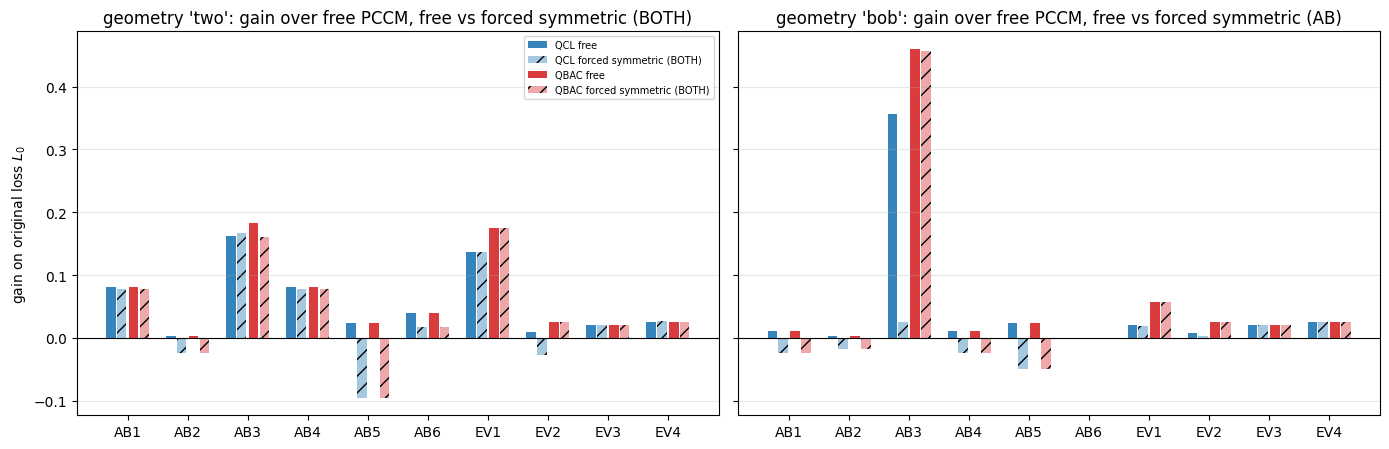

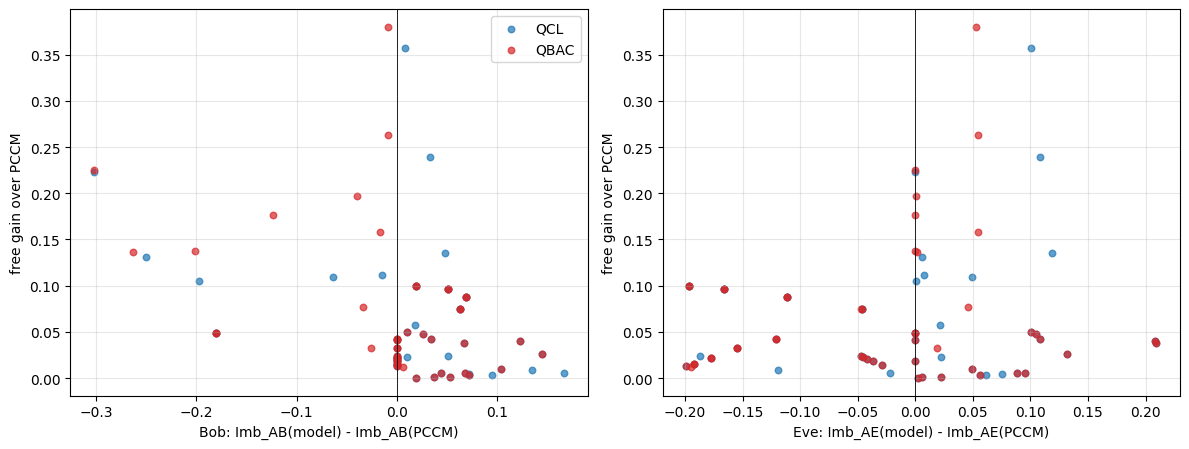

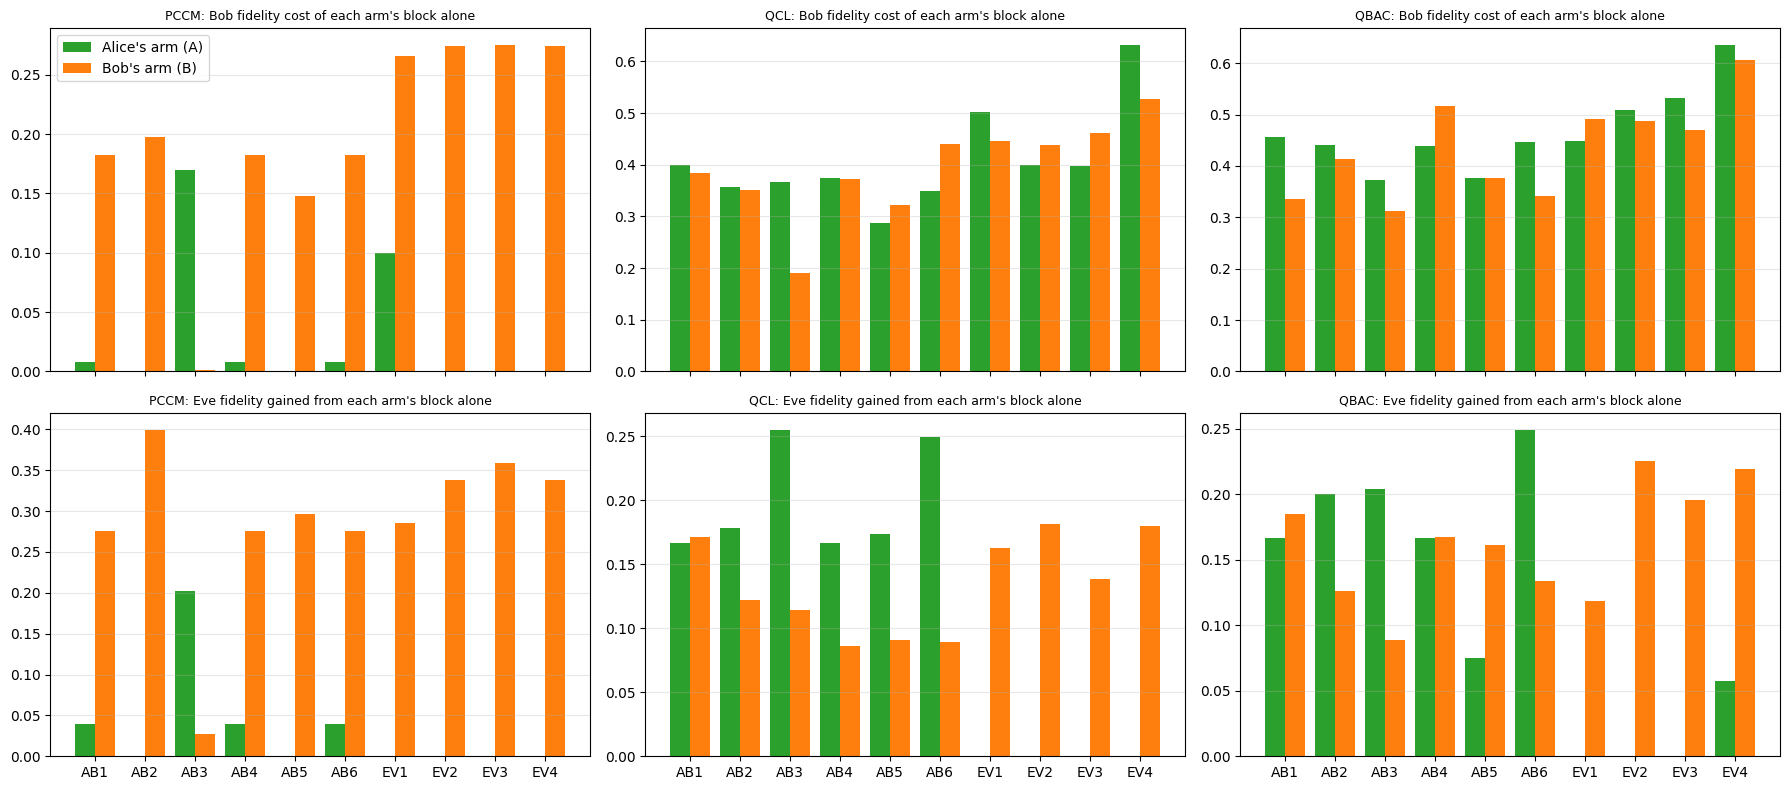

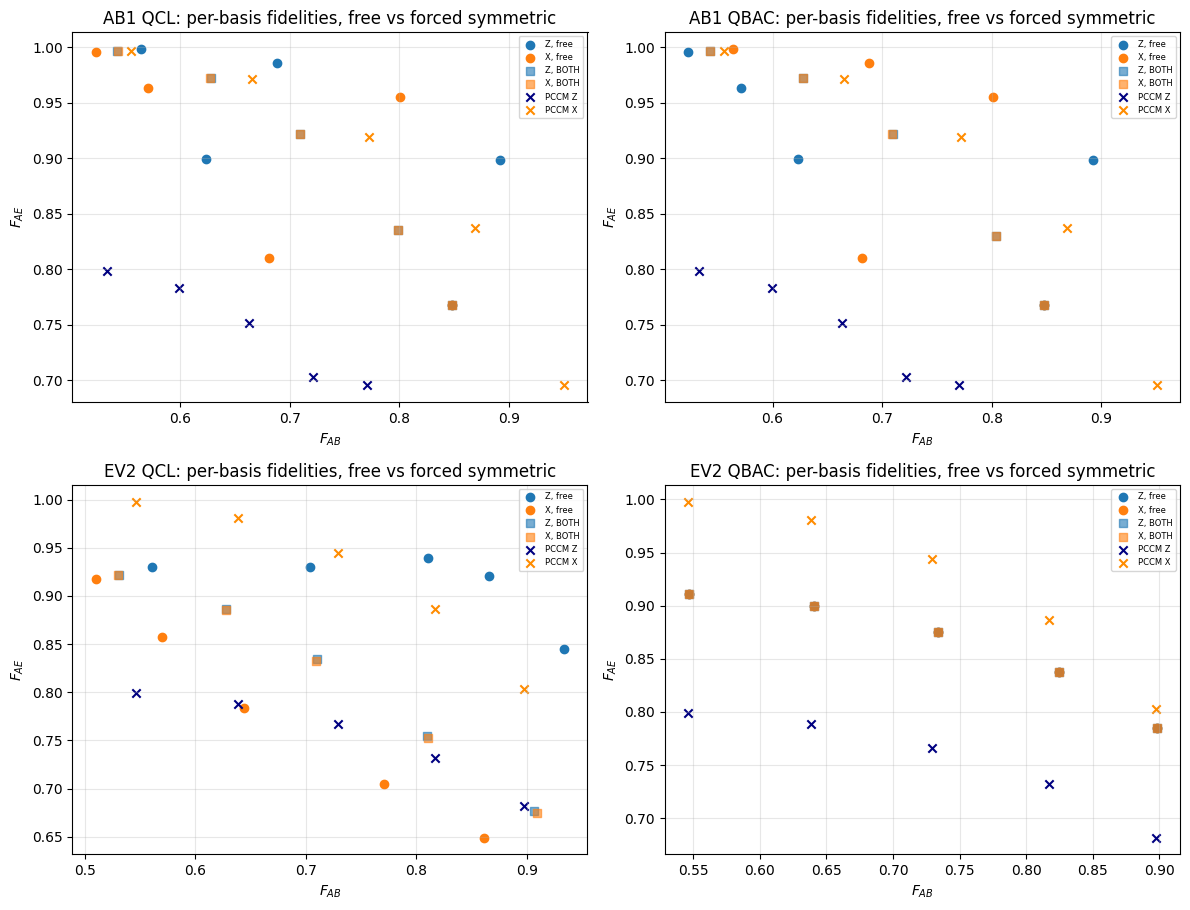


Saved: cell1_rows.csv, cell1_restarts.csv, cell1_gains.csv, cell1_classification.csv, cell1_fig1..4 PNG.


In [ ]:
# =====================================================================================================
# CELL 1 / 4  -  Do QCL and Q-BAC have to be "imbalancer cloners" to gain over PCCM?   (BBM92, Eve on both arms)
#
# Question : if QCL / Q-BAC are FORCED to have equal Z and X fidelities, does their gain over PCCM survive?
# Design   : (i) preflight validation of the simulator (incl. an independent NumPy re-implementation)
#            (ii) free training, and training under a hard-ish symmetry constraint (large penalty lambda):
#                 AB   = force |F_AB,Z - F_AB,X| -> 0   (Bob's fidelity balanced: what Alice/Bob can see)
#                 AE   = force |F_AE,Z - F_AE,X| -> 0   (Eve's fidelity balanced)
#                 BOTH = both
#            (iii) geometries: "two" = Eve attacks both arms ; "bob" = Eve attacks Bob's arm only (BB84-equivalent control)
#            (iv) references: PCCM free, and PCCM trained under the SAME constraint ("balanced PCCM")
#            (v) arm usage: how much Eve loses when one arm's block is switched off
# Gain     : always measured on the ORIGINAL loss  L0 = 10 (F_AB - f)^2 - F_AE   (penalty only used for training)
# Setup    : trusted |Phi+> source, noise strength 0.2, 10 scenarios (6 Alice-Bob + 4 Eve side), 5 targets, paired random starts
# Resume   : results are appended to cell1_rows.csv / cell1_restarts.csv after every scenario; re-running skips finished scenarios.
# Needs only jax, numpy, scipy, pandas, matplotlib (pre-installed on Colab).
# =====================================================================================================
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128

MODE = "FULL"                 # "DEV" = quick smoke test (3 scenarios, 2 targets, 4 restarts)   |   "FULL" = paper run
STRENGTH, LAM, MARG_W = 0.2, 100.0, 1000.0
GAIN_TOL, CONS_TOL, SEED = 1e-3, 5e-3, 0
if MODE == "DEV":  TARGETS, R, GRID_N, MAXITER, SCEN_IDS = [0.65, 0.85], 4, 41, 400, ["AB1", "AB5", "EV2"]
else:              TARGETS, R, GRID_N, MAXITER, SCEN_IDS = [0.55, 0.65, 0.75, 0.85, 0.95], 24, 91, 500, None
ROWS_CSV, RESTARTS_CSV = "cell1_rows.csv", "cell1_restarts.csv"

# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)
VAR = {"free": (0., 0.), "AB": (LAM, 0.), "AE": (0., LAM), "BOTH": (LAM, LAM)}
GEOM = {"two": (1., 1.), "bob": (0., 1.)}                      # (mask arm A, mask arm B)
PLAN = {"two": ["free", "AB", "AE", "BOTH"], "bob": ["free", "AB"]}

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in ("QCL", "QBAC"): eng[m] = jax.jit(jax.value_and_grad(gen(m), has_aux=True)); eng[m + "_ev"] = jax.jit(gen(m))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, 12)))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ("QCL", "QBAC"):
            x = rng.uniform(-3, 3, 36); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# ----------------------------------------------------------------------------------------------- main loop
preflight()
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
n_runs = len(SCEN) * len(TARGETS) * R * 2 * sum(len(v) for v in PLAN.values())
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(TARGETS)} targets x {R} restarts x 2 models x {sum(len(v) for v in PLAN.values())} (geometry,variant) = {n_runs} trainings "
      f"(~{n_runs*0.35/60:.0f} min at 0.35 s each, plus compile)", flush=True)
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
for (sid, group, label, pre, post, src) in SCEN:
    if sid in done: print(f"  {sid} already in {ROWS_CSV}, skipped"); continue
    eng = make_engines(make_sim(pre, post, src)); base = eng["base"](STRENGTH); rows, rst = [], []
    for f in TARGETS:
        for geom, (mA, mB) in GEOM.items():
            starts = rng_for(sid, f, geom).uniform(-np.pi, np.pi, (R, 36))                         # paired: identical start vectors for QCL and Q-BAC (and all variants)
            for var in PLAN[geom]:
                lab, lae = VAR[var]; args = (f, STRENGTH, base, lab, lae, mA, mB)
                xp, lp, ap = fit_pccm(eng, f, base, lab, lae, mA, mB, G)
                us = usage(eng["pccm_ev"], xp, f, base) if geom == "two" else NANU
                rows.append(dict(scen=sid, group=group, label=label, target=f, geom=geom, variant=var, model="PCCM", L0=L0_of(ap, f), loss_pen=lp,
                                 FABz=ap[0], FAEz=ap[1], FABx=ap[2], FAEx=ap[3], bias=ap[4], **us))
                for m in ("QCL", "QBAC"):
                    best = None
                    for r_ in range(R):
                        o = run_min(eng[m], starts[r_], args, MAXITER); (l, aux), _ = eng[m](jnp.asarray(o.x), *args); aux = np.asarray(aux)
                        rst.append(dict(scen=sid, target=f, geom=geom, variant=var, model=m, restart=r_, loss_pen=float(l), L0=L0_of(aux, f),
                                        ImbAB=abs(aux[0]-aux[2]), ImbAE=abs(aux[1]-aux[3])))
                        if best is None or float(l) < best[1]: best = (o.x, float(l), aux)
                    xb, lb, ab = best; us = usage(eng[m + "_ev"], xb, f, base) if geom == "two" else NANU
                    rows.append(dict(scen=sid, group=group, label=label, target=f, geom=geom, variant=var, model=m, L0=L0_of(ab, f), loss_pen=lb,
                                     FABz=ab[0], FAEz=ab[1], FABx=ab[2], FAEx=ab[3], bias=ab[4], **us))
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False)
    pd.DataFrame(rst).to_csv(RESTARTS_CSV, mode="a", header=not os.path.exists(RESTARTS_CSV), index=False)
    print(f"  {sid} {label:34s} done  [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis
D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin([s[0] for s in SCEN])]
D["ImbAB"] = (D.FABz - D.FABx).abs(); D["ImbAE"] = (D.FAEz - D.FAEx).abs()
fp = D[(D.model == "PCCM") & (D.variant == "free")][["scen", "target", "geom", "L0"]].rename(columns={"L0": "PCCMfree_L0"})
pv = D[D.model == "PCCM"][["scen", "target", "geom", "variant", "L0", "ImbAB", "ImbAE"]].rename(columns={"L0": "PCCMvar_L0", "ImbAB": "PCCM_ImbAB", "ImbAE": "PCCM_ImbAE"})
M = D[D.model != "PCCM"].merge(fp, on=["scen", "target", "geom"]).merge(pv, on=["scen", "target", "geom", "variant"])
M["G_vs_free"] = M.PCCMfree_L0 - M.L0; M["G_vs_balPCCM"] = M.PCCMvar_L0 - M.L0
M["cons_ok"] = np.select([M.variant == "AB", M.variant == "AE", M.variant == "BOTH"], [M.ImbAB < CONS_TOL, M.ImbAE < CONS_TOL, (M.ImbAB < CONS_TOL) & (M.ImbAE < CONS_TOL)], default=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 300); pd.set_option("display.float_format", "{:.4f}".format)
M.to_csv("cell1_gains.csv", index=False)
print("\n" + "=" * 110); print("TABLE 1  Free gain over PCCM (original loss L0), mean / max over targets.  geom: two = Eve on both arms, bob = Eve on Bob's arm only")
t1 = M[M.variant == "free"].groupby(["scen", "label", "geom", "model"], sort=False).G_vs_free.agg(["mean", "max"]).unstack("model"); print(t1.to_string())
print("\n" + "=" * 110); print("TABLE 2  Gain vs FREE PCCM when the model is forced symmetric (mean over targets where the constraint was met; n = how many of the targets)")
for geom in ("two", "bob"):
    sub = M[(M.geom == geom)]; g = sub[sub.cons_ok].groupby(["scen", "model", "variant"]).G_vs_free.agg(["mean", "count"]).unstack("variant"); print(f"\n  geometry = {geom}"); print(g.to_string())
print("\n" + "=" * 110); print("TABLE 3  Gain vs the PCCM trained under the SAME constraint (balanced PCCM), mean over targets where the model met the constraint")
for geom in ("two", "bob"):
    sub = M[(M.geom == geom) & (M.variant != "free") & M.cons_ok]; print(f"\n  geometry = {geom}"); print(sub.groupby(["scen", "model", "variant"]).G_vs_balPCCM.mean().unstack("variant").to_string())
print("\n" + "=" * 110); print("TABLE 4  Classification (rule fixed in advance): imbalance-DEPENDENT if free gain > %g and constrained gain (vs free PCCM) <= %g ; imbalance-INDEPENDENT if constrained gain >= 0.5 x free gain" % (GAIN_TOL, GAIN_TOL))
cls = []
for (sid, geom, m), g in M.groupby(["scen", "geom", "model"]):
    free = g[g.variant == "free"].G_vs_free.mean()
    for v in PLAN[geom][1:]:
        gv = g[(g.variant == v) & g.cons_ok]
        if len(gv) == 0: cls.append(dict(scen=sid, geom=geom, model=m, constraint=v, free=free, constrained=np.nan, n_ok=0, verdict="constraint not met")); continue
        c = gv.G_vs_free.mean()
        verdict = "n/a (no free gain)" if free <= GAIN_TOL else ("imbalance-DEPENDENT" if c <= GAIN_TOL else ("imbalance-INDEPENDENT" if c >= 0.5 * free else "partly dependent"))
        cls.append(dict(scen=sid, geom=geom, model=m, constraint=v, free=free, constrained=c, n_ok=len(gv), verdict=verdict))
cls = pd.DataFrame(cls); print(cls.to_string(index=False)); cls.to_csv("cell1_classification.csv", index=False)
print("\n" + "=" * 110); print("TABLE 5  Was the constraint actually met?  share of (target) trainings with the constrained imbalance < %g" % CONS_TOL)
print(M[M.variant != "free"].groupby(["geom", "variant", "model"]).cons_ok.mean().unstack("model").to_string())
print("\n" + "=" * 110); print("TABLE 6  Arm usage (two-arm geometry, free training), mean over targets. Each arm's block ALONE: d = Bob fidelity it costs, e = fidelity it gives Eve. A = Alice's arm, B = Bob's arm")
print(D[(D.geom == "two") & (D.variant == "free")].groupby(["scen", "model"], sort=False)[["dA", "dB", "eA", "eB"]].mean().to_string())
print("\n" + "=" * 110); print("TABLE 7  Does the extra arm matter?  free gain in two-arm minus free gain in Bob-only geometry (mean over targets)")
w = M[M.variant == "free"].groupby(["scen", "model", "geom"]).G_vs_free.mean().unstack("geom"); w["two - bob"] = w["two"] - w["bob"]; print(w.to_string())

# ----------------------------------------------------------------------------------------------- figures
ids = [s[0] for s in SCEN]; col = {"QCL": "tab:blue", "QBAC": "tab:red"}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (geom, cv) in zip(axs, (("two", "BOTH"), ("bob", "AB"))):
    for k, m in enumerate(("QCL", "QBAC")):
        fr = [M[(M.scen == s) & (M.geom == geom) & (M.model == m) & (M.variant == "free")].G_vs_free.mean() for s in ids]
        cn = [M[(M.scen == s) & (M.geom == geom) & (M.model == m) & (M.variant == cv) & M.cons_ok].G_vs_free.mean() for s in ids]
        x = np.arange(len(ids)) + (k - .5) * .38
        ax.bar(x - .09, fr, .16, color=col[m], alpha=.9, label=f"{m} free"); ax.bar(x + .09, cn, .16, color=col[m], alpha=.4, hatch="//", label=f"{m} forced symmetric ({cv})")
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(ids))); ax.set_xticklabels(ids); ax.set_title(f"geometry '{geom}': gain over free PCCM, free vs forced symmetric ({cv})"); ax.grid(alpha=.3, axis="y")
axs[0].set_ylabel("gain on original loss $L_0$"); axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("cell1_fig1_gain_free_vs_forced.png", dpi=170); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for m in ("QCL", "QBAC"):
    g = M[(M.variant == "free") & (M.model == m) & (M.geom == "two")]
    axs[0].scatter(g.ImbAB - g.PCCM_ImbAB, g.G_vs_free, s=22, c=col[m], alpha=.7, label=m); axs[1].scatter(g.ImbAE - g.PCCM_ImbAE, g.G_vs_free, s=22, c=col[m], alpha=.7, label=m)
for ax, t in zip(axs, ("Bob: Imb_AB(model) - Imb_AB(PCCM)", "Eve: Imb_AE(model) - Imb_AE(PCCM)")): ax.axvline(0, color="k", lw=.6); ax.set_xlabel(t); ax.set_ylabel("free gain over PCCM"); ax.grid(alpha=.3)
axs[0].legend(); plt.tight_layout(); plt.savefig("cell1_fig2_gain_vs_imbalance.png", dpi=170); plt.show()
fig, axs = plt.subplots(2, 3, figsize=(18, 8), sharex=True); u = D[(D.geom == "two") & (D.variant == "free")].groupby(["scen", "model"])[["dA", "dB", "eA", "eB"]].mean()
for c_, m in enumerate(("PCCM", "QCL", "QBAC")):
    for r_, (a_, b_, tt) in enumerate((("dA", "dB", "Bob fidelity cost of each arm's block alone"), ("eA", "eB", "Eve fidelity gained from each arm's block alone"))):
        ax = axs[r_, c_]; ax.bar(np.arange(len(ids)) - .2, [u.loc[(s, m), a_] for s in ids], .4, label="Alice's arm (A)", color="tab:green")
        ax.bar(np.arange(len(ids)) + .2, [u.loc[(s, m), b_] for s in ids], .4, label="Bob's arm (B)", color="tab:orange"); ax.set_xticks(range(len(ids))); ax.set_xticklabels(ids)
        ax.set_title(f"{m}: {tt}", fontsize=9); ax.grid(alpha=.3, axis="y")
axs[0, 0].legend(); plt.tight_layout(); plt.savefig("cell1_fig3_arm_usage.png", dpi=170); plt.show()
sel = [s for s in ("AB1", "EV2") if s in ids] or ids[:2]; fig, axs = plt.subplots(len(sel), 2, figsize=(12, 4.6 * len(sel)), squeeze=False)
for r_, sid in enumerate(sel):
    for c_, m in enumerate(("QCL", "QBAC")):
        ax = axs[r_, c_]
        for var, mk, al in (("free", "o", 1.0), ("BOTH", "s", .6)):
            g = D[(D.scen == sid) & (D.geom == "two") & (D.model == m) & (D.variant == var)]
            ax.scatter(g.FABz, g.FAEz, marker=mk, c="tab:blue", alpha=al, label=f"Z, {var}"); ax.scatter(g.FABx, g.FAEx, marker=mk, c="tab:orange", alpha=al, label=f"X, {var}")
        p_ = D[(D.scen == sid) & (D.geom == "two") & (D.model == "PCCM") & (D.variant == "free")]
        ax.scatter(p_.FABz, p_.FAEz, marker="x", c="navy", label="PCCM Z"); ax.scatter(p_.FABx, p_.FAEx, marker="x", c="darkorange", label="PCCM X")
        ax.set_title(f"{sid} {m}: per-basis fidelities, free vs forced symmetric"); ax.set_xlabel("$F_{AB}$"); ax.set_ylabel("$F_{AE}$"); ax.grid(alpha=.3); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig("cell1_fig4_basis_planes.png", dpi=170); plt.show()
print("\nSaved: cell1_rows.csv, cell1_restarts.csv, cell1_gains.csv, cell1_classification.csv, cell1_fig1..4 PNG.")

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CR block unitary (dev 2.5e-16)
  [OK] QBAC_noCR block unitary (dev 6.7e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 2.3e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noiseless PCCM f=0.65: grid -0.979189 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.979189
  [OK] noiseless PCCM f=0.75: grid -0.940265 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.940265
  [OK] noiseless PCCM f=0.85: grid -0.876303 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.876303
  [OK] gradients vs finite differences (max abs err 4.7e-08)
  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on bot

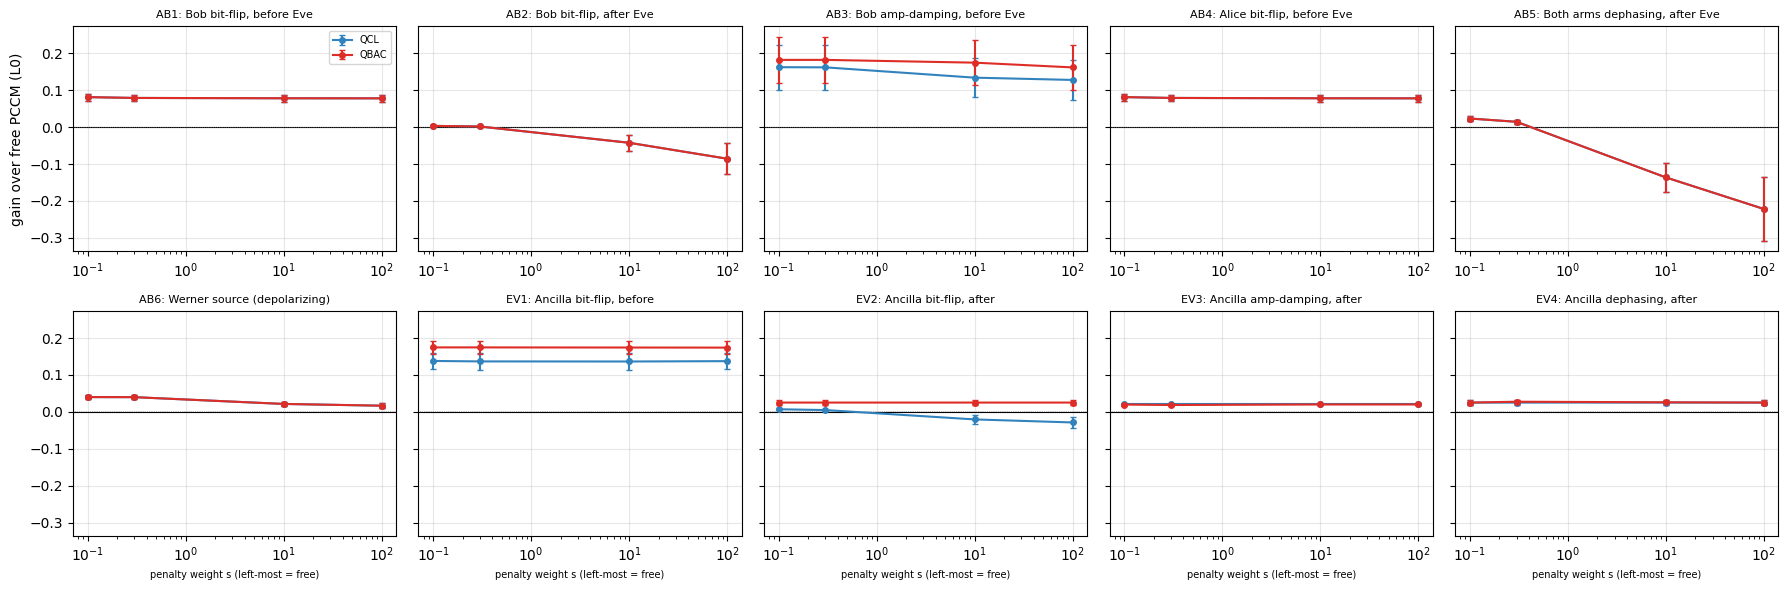

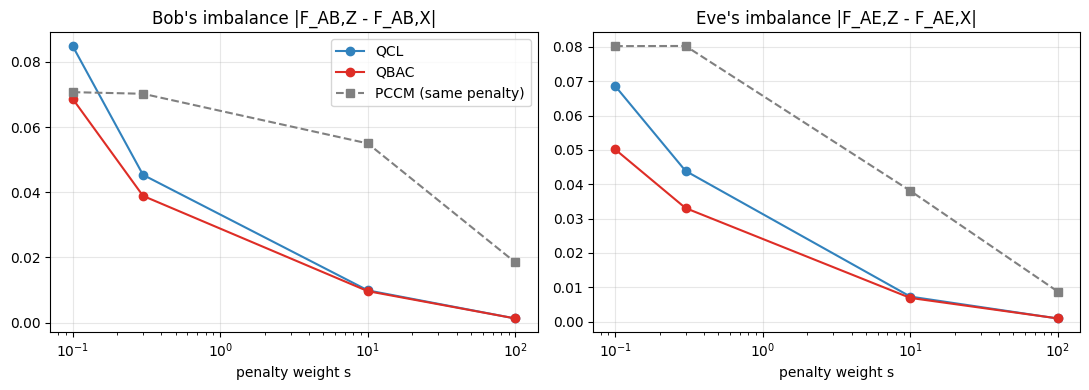

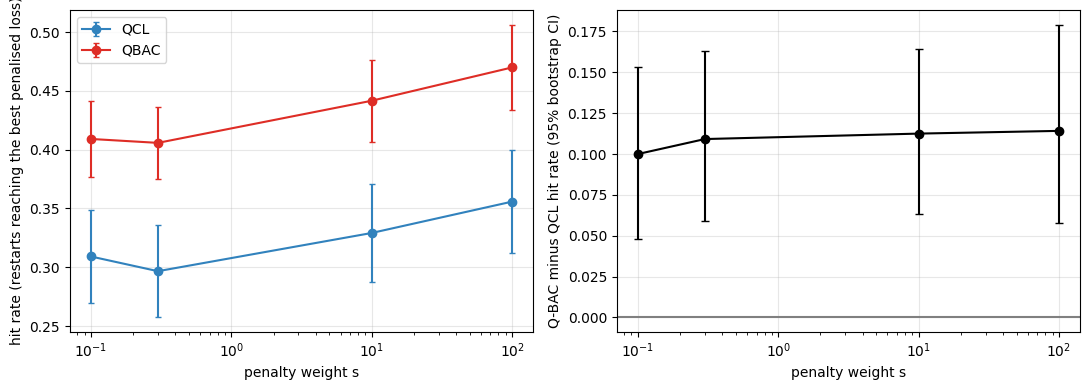

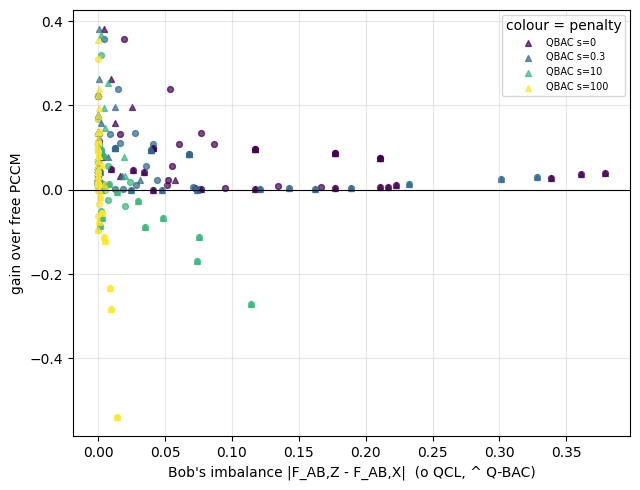


Saved: cell2_pilot.csv, cell2_lambdas.json, cell2_rows.csv, cell2_restarts.csv, cell2_gains.csv, cell2_fig1..4 PNG.


In [ ]:
# =====================================================================================================
# CELL 2 / 4  -  What happens when a symmetry penalty is added?   (BBM92, Eve on both arms, noise strength 0.2)
#
# Question : as the penalty weight lambda grows (QCL / Q-BAC pushed towards equal Z and X fidelities), how fast does their gain over PCCM shrink,
#            and is Q-BAC more reliable than QCL while it shrinks?
# Penalty  : training loss = L0 + MARG_W*(marginal bias) + lam_ab*(Bob's Z-X error imbalance)^2 + lam_ae*(Eve's Z-X success imbalance)^2,  (lam_ab, lam_ae) = (s, RATIO_AE*s)
# Stage A  : PILOT   - ladder of s on a small budget; picks 3 points where BOTH models still gain in >= KEEP of the (scenario,target) rows.
# Stage B  : MAIN    - lam = 0 (free), the 3 chosen points, and the limit point s = LIMIT; 10 scenarios x 5 targets x R paired restarts; PCCM free and PCCM
#                      trained under the same penalty ("penalised PCCM") are both recorded.
# Gain     : always on the ORIGINAL loss  L0 = 10 (F_AB - f)^2 - F_AE  against FREE PCCM (primary) and against penalised PCCM (secondary).
# Reliability under penalty : hit rate = share of restarts within HIT_TOL of the best penalised loss found by either model for that (scenario,target,lam).
# Resume   : pilot and main results are appended per scenario; re-running skips finished scenarios.
# Output   : ONE main table (cell2_main_table.csv/.tex) and ONE main figure (cell2_main_figure.png) for the paper; every raw number is in cell2_*.csv for supplementary use.
#            Re-running after a finished run skips all training and only redraws the table and figure (about 1 minute incl. preflight).
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W = 0.2, 1000.0
GAIN_TOL, HIT_TOL, SEED = 1e-3, 1e-3, 0
LADDER, LIMIT, RATIO_AE, KEEP, MANUAL = [0.3, 1., 3., 10., 30., 100.], 100., 1.0, 0.5, None      # MANUAL = e.g. [1., 10., 50.] overrides the pilot selection
if MODE == "DEV": TARGETS, R, GRID_N, MAXITER, SCEN_IDS, PTARGETS, PR, LADDER = [0.65, 0.85], 4, 41, 400, ["AB1", "AB5", "EV2"], [0.75], 3, [1., 10., 100.]
else:             TARGETS, R, GRID_N, MAXITER, SCEN_IDS, PTARGETS, PR = [0.55, 0.65, 0.75, 0.85, 0.95], 24, 91, 500, None, [0.65, 0.85], 8
PILOT_CSV, LAM_JSON, ROWS_CSV, RST_CSV = "cell2_pilot.csv", "cell2_lambdas.json", "cell2_rows.csv", "cell2_restarts.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if sc is SCEN[0] else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# ----------------------------------------------------------------------------------------------- stage A: pilot
import json
from scipy import stats
def lam_pair(s): return s, s * RATIO_AE
def best_restart(eng, m, starts, args):
    best = None
    for x0 in starts:
        o = run_min(eng[m], x0, args, MAXITER); (l, aux), _ = eng[m](jnp.asarray(o.x), *args)
        if best is None or float(l) < best[0]: best = (float(l), np.asarray(aux), o.x)
    return best
preflight()
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
if MANUAL is None and not os.path.exists(LAM_JSON):
    done = set(pd.read_csv(PILOT_CSV).scen.unique()) if os.path.exists(PILOT_CSV) else set()
    print(f"STAGE A  pilot: {len(SCEN)} scen x {len(PTARGETS)} targets x {len(LADDER)+1} lambdas x {PR} restarts x 2 models = {len(SCEN)*len(PTARGETS)*(len(LADDER)+1)*PR*2} trainings", flush=True)
    for (sid, group, label, pre, post, src) in SCEN:
        if sid in done: continue
        eng = make_engines(make_sim(pre, post, src)); base = eng["base"](STRENGTH); rows = []
        for f in PTARGETS:
            P0 = L0_of(fit_pccm(eng, f, base, 0., 0., 1., 1., G)[2], f); starts = rng_for("pilot", sid, f).uniform(-np.pi, np.pi, (PR, 36))
            for s in [0.] + LADDER:
                lab, lae = lam_pair(s); args = (f, STRENGTH, base, lab, lae, 1., 1.)
                rows.append(dict(scen=sid, target=f, lam=s, **{"G_" + m: P0 - L0_of(best_restart(eng, m, starts, args)[1], f) for m in ("QCL", "QBAC")}))
        pd.DataFrame(rows).to_csv(PILOT_CSV, mode="a", header=not os.path.exists(PILOT_CSV), index=False); print(f"  pilot {sid} done [{time.time()-t0:.0f}s]", flush=True)
    P = pd.read_csv(PILOT_CSV); P = P[P.scen.isin([s[0] for s in SCEN])]; P["both"] = (P.G_QCL > GAIN_TOL) & (P.G_QBAC > GAIN_TOL)
    P["qcl"], P["qbac"] = P.G_QCL > GAIN_TOL, P.G_QBAC > GAIN_TOL
    ret = P.groupby("lam").agg(both=("both", "mean"), QCL=("qcl", "mean"), QBAC=("qbac", "mean"), meanG_QCL=("G_QCL", "mean"), meanG_QBAC=("G_QBAC", "mean"))
    pd.set_option("display.width", 220); pd.set_option("display.float_format", "{:.4f}".format)
    print("\nPILOT  share of (scenario,target) rows with gain > tol over free PCCM, by penalty weight s"); print(ret.to_string())
    surv = [s for s in LADDER if ret.loc[s, "both"] >= KEEP]
    pick = surv if len(surv) <= 3 else [surv[0], surv[len(surv) // 2], surv[-1]]
    if not pick: pick = [LADDER[0]]; print("  WARNING: no ladder point keeps both models gaining in >= KEEP of the rows; using the smallest ladder point")
    if len(pick) < 3: print(f"  NOTE: only {len(pick)} ladder points satisfy the 'both still gain' criterion (KEEP={KEEP})")
    json.dump(dict(lambdas=[float(x) for x in pick]), open(LAM_JSON, "w")); print("  selected penalty weights s =", pick, " ->  (lam_ab, lam_ae) =", [lam_pair(s) for s in pick])
LAMS = sorted(set([0.] + ([float(x) for x in MANUAL] if MANUAL else json.load(open(LAM_JSON))["lambdas"]) + [float(LIMIT)]))
print("STAGE B  penalty weights used:", [(s, lam_pair(s)) for s in LAMS], flush=True)

# ----------------------------------------------------------------------------------------------- stage B: main run
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
print(f"  {len(SCEN)} scen x {len(TARGETS)} targets x {len(LAMS)} lambdas x {R} restarts x 2 models = {len(SCEN)*len(TARGETS)*len(LAMS)*R*2} trainings", flush=True)
for (sid, group, label, pre, post, src) in SCEN:
    if sid in done: print(f"  {sid} already done, skipped"); continue
    eng = make_engines(make_sim(pre, post, src)); base = eng["base"](STRENGTH); rows, rst = [], []
    for f in TARGETS:
        starts = rng_for("main", sid, f).uniform(-np.pi, np.pi, (R, 36))                      # paired: same start vectors for QCL, Q-BAC and every lambda
        for s in LAMS:
            lab, lae = lam_pair(s); args = (f, STRENGTH, base, lab, lae, 1., 1.)
            xp, lp, ap = fit_pccm(eng, f, base, lab, lae, 1., 1., G)
            rows.append(dict(scen=sid, group=group, label=label, target=f, lam=s, model="PCCM", L0=L0_of(ap, f), loss_pen=lp, FABz=ap[0], FAEz=ap[1], FABx=ap[2], FAEx=ap[3], bias=ap[4]))
            for m in ("QCL", "QBAC"):
                best = None
                for r_ in range(R):
                    o = run_min(eng[m], starts[r_], args, MAXITER); (l, aux), _ = eng[m](jnp.asarray(o.x), *args); aux = np.asarray(aux)
                    rst.append(dict(scen=sid, target=f, lam=s, model=m, restart=r_, loss_pen=float(l), L0=L0_of(aux, f), ImbAB=abs(aux[0]-aux[2]), ImbAE=abs(aux[1]-aux[3])))
                    if best is None or float(l) < best[1]: best = (o.x, float(l), aux)
                ab = best[2]
                rows.append(dict(scen=sid, group=group, label=label, target=f, lam=s, model=m, L0=L0_of(ab, f), loss_pen=best[1], FABz=ab[0], FAEz=ab[1], FABx=ab[2], FAEx=ab[3], bias=ab[4]))
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False)
    pd.DataFrame(rst).to_csv(RST_CSV, mode="a", header=not os.path.exists(RST_CSV), index=False); print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis: ONE table, ONE figure
ids = [s[0] for s in SCEN]; D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin(ids)]; RS = pd.read_csv(RST_CSV); RS = RS[RS.scen.isin(ids)]
D["ImbAB"] = (D.FABz - D.FABx).abs(); D["ImbAE"] = (D.FAEz - D.FAEx).abs()
pf = D[(D.model == "PCCM") & (D.lam == 0)][["scen", "target", "L0"]].rename(columns={"L0": "PCCMfree"})
M = D[D.model != "PCCM"].merge(pf, on=["scen", "target"]); M["G_free"] = M.PCCMfree - M.L0; M.to_csv("cell2_gains.csv", index=False)
lamcols = sorted(M.lam.unique()); lam_hi = max(lamcols); T = len(TARGETS); rngb = np.random.default_rng(1)
RS["best"] = RS.groupby(["scen", "target", "lam"]).loss_pen.transform("min"); RS["hit"] = RS.loss_pen <= RS.best + HIT_TOL
H = RS.groupby(["scen", "target", "lam", "model"]).hit.mean().reset_index()
HW = H.pivot_table(index=["scen", "target", "lam"], columns="model", values="hit").reset_index(); HW["d"] = HW.QBAC - HW.QCL
def boot(d, n=4000): return np.percentile([rngb.choice(d, len(d)).mean() for _ in range(n)], [2.5, 97.5])
by_lam = {l: (g.d.mean(), *boot(g.d.values)) for l, g in HW.groupby("lam")}
cellmean = HW.groupby(["scen", "target"]).d.mean()                                       # one number per (scenario,target): mean over penalty weights (lambdas share start vectors)
pooled = (cellmean.mean(), *boot(cellmean.values))
try: pw = stats.wilcoxon(cellmean.values[cellmean.values != 0]).pvalue
except Exception: pw = np.nan
def verdict(g):
    s = (g > GAIN_TOL).mean(); return "kept" if s >= 0.8 else "lost" if s <= 0.2 else "partly"
rows = []; names = {"QCL": "QCL", "QBAC": "Q-BAC"}
for sid in ids:
    g = M[M.scen == sid]; r = {"Scenario": f"{sid}  {g.label.iloc[0]}"}
    for m in ("QCL", "QBAC"):
        g0 = g[(g.model == m) & (g.lam == 0)].G_free; g1 = g[(g.model == m) & (g.lam == lam_hi)].G_free
        r[f"free {names[m]}"] = g0.mean(); r[f"sym {names[m]}"] = g1.mean(); r[f"kept {names[m]}"] = verdict(g1)
    for m in ("QCL", "QBAC"): r[f"hit {names[m]}"] = H[(H.scen == sid) & (H.model == m)].hit.mean()
    rows.append(r)
TB = pd.DataFrame(rows); n_ = len(TB)
foot = {"Scenario": "ALL (mean over scenarios)"}
for m in ("QCL", "QBAC"):
    foot[f"free {names[m]}"] = TB[f"free {names[m]}"].mean(); foot[f"sym {names[m]}"] = TB[f"sym {names[m]}"].mean(); foot[f"kept {names[m]}"] = f"{int((TB[f'kept {names[m]}'] == 'kept').sum())}/{n_} kept"; foot[f"hit {names[m]}"] = TB[f"hit {names[m]}"].mean()
TBp = pd.concat([TB, pd.DataFrame([foot])], ignore_index=True)
TBp.to_csv("cell2_main_table.csv", index=False)
try: TBp.rename(columns={"free QCL": "QCL free", "free Q-BAC": "Q-BAC free", "sym QCL": "QCL sym.", "sym Q-BAC": "Q-BAC sym.", "kept QCL": "QCL kept?", "kept Q-BAC": "Q-BAC kept?", "hit QCL": "QCL hit", "hit Q-BAC": "Q-BAC hit"}).to_latex("cell2_main_table.tex", index=False, float_format="%.3f")
except Exception as e: print("  (LaTeX export skipped:", e, ")")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:+.3f}".format)
print("\n" + "=" * 125)
print(f"MAIN TABLE  Gain over free PCCM (L0, mean of {T} targets), noise strength {STRENGTH}, Eve on both arms.   free = no penalty ; sym = forced symmetric (s = {lam_hi:g}) ; kept = gain > {GAIN_TOL} in >= 80% of targets (lost: <= 20%)")
print("            hit = share of restarts reaching the best penalised loss found by either model (mean over all penalty weights and targets)")
Tshow = TBp.copy()
for c in ("hit QCL", "hit Q-BAC"): Tshow[c] = Tshow[c].map("{:.2f}".format)
print(Tshow.to_string(index=False))
imb = M[(M.lam == lam_hi)][["ImbAB", "ImbAE"]].agg(["mean", "max"])
print(f"\nConstraint check at s = {lam_hi:g}: Bob's imbalance mean {imb.ImbAB['mean']:.4f} (max over rows {imb.ImbAB['max']:.4f}) ; Eve's imbalance mean {imb.ImbAE['mean']:.4f} (max {imb.ImbAE['max']:.4f})")
print("Q-BAC minus QCL hit rate, by penalty weight: " + " | ".join(f"s={l:g}: {v[0]:+.3f} [{v[1]:+.3f},{v[2]:+.3f}]" for l, v in by_lam.items()))
print(f"  pooled over penalty weights (cluster bootstrap over {len(cellmean)} (scenario,target) cells): {pooled[0]:+.3f} [{pooled[1]:+.3f}, {pooled[2]:+.3f}],  Wilcoxon p = {pw:.2g};  Q-BAC higher in {(cellmean > .02).sum()} cells, QCL higher in {(cellmean < -.02).sum()}")

# ----------------------------------------------------------------------------------------------- the main figure
col = {"QCL": "#2b6cb0", "QBAC": "#d62728"}
S = M.groupby(["scen", "model", "lam"]).G_free.mean().unstack("lam"); order = list(S.xs("QBAC", level="model")[lam_hi].sort_values().index)
lab_of = {s[0]: s[2] for s in SCEN}; fig = plt.figure(figsize=(16, 6.0)); gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.36); axA, axB = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
for i, sid in enumerate(order):
    if i % 2 == 0: axA.axhspan(i - .5, i + .5, color="0.95", zorder=0)
    for m, off in (("QCL", +.16), ("QBAC", -.16)):
        a, b = S.loc[(sid, m), 0.0], S.loc[(sid, m), lam_hi]
        axA.plot([a, b], [i + off] * 2, color=col[m], lw=2.2, alpha=.55, zorder=2)
        axA.scatter([a], [i + off], s=60, facecolors="white", edgecolors=col[m], linewidths=1.9, zorder=3); axA.scatter([b], [i + off], s=60, color=col[m], zorder=4)
axA.axvline(0, color="k", lw=1); axA.set_yticks(range(len(order))); axA.set_yticklabels([f"{s}  {lab_of[s]}" for s in order], fontsize=9); axA.set_ylim(-.6, len(order) - .4)
axA.set_xlabel(f"gain over free PCCM  (original loss L0, mean of {T} target fidelities)"); axA.grid(alpha=.3, axis="x")
kq, kb = int((TB["kept QCL"] == "kept").sum()), int((TB["kept Q-BAC"] == "kept").sum())
axA.set_title(f"(a) Forcing symmetric fidelities: gain kept in {kq}/{n_} scenarios (QCL), {kb}/{n_} (Q-BAC)", fontsize=11, loc="left")
from matplotlib.lines import Line2D
axA.legend(handles=[Line2D([], [], color=col["QCL"], lw=3, label="QCL"), Line2D([], [], color=col["QBAC"], lw=3, label="Q-BAC"),
                    Line2D([], [], marker="o", ls="", mfc="white", mec="0.2", mew=1.8, ms=8, label="free training"), Line2D([], [], marker="o", ls="", color="0.2", ms=8, label=f"forced symmetric (s = {lam_hi:g})")],
           loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4, fontsize=9, frameon=False)
xs_ = np.arange(len(lamcols)); lo_ = [by_lam[l][1] for l in lamcols]; hi_ = [by_lam[l][2] for l in lamcols]; mu_ = [by_lam[l][0] for l in lamcols]
axB.fill_between(xs_, lo_, hi_, color=col["QBAC"], alpha=.18, zorder=2); axB.plot(xs_, mu_, "o-", color=col["QBAC"], lw=2.6, ms=8, zorder=3); axB.axhline(0, color="k", lw=1)
axB.set_xticks(xs_); axB.set_xticklabels(["free" if l == 0 else f"{l:g}" for l in lamcols]); axB.set_xlabel("penalty weight s on the fidelity imbalance"); axB.set_ylabel("hit rate:  Q-BAC minus QCL")
axB.set_title("(b) Q-BAC reaches the best solution more often", fontsize=11, loc="left"); axB.grid(alpha=.3, axis="y")
axB.text(.03, .97, f"pooled over s: {pooled[0]:+.2f}  [{pooled[1]:+.2f}, {pooled[2]:+.2f}] (95% CI)\nWilcoxon p = {pw:.1g} over {len(cellmean)} cells", transform=axB.transAxes, fontsize=9, va="top", bbox=dict(fc="white", ec="0.8"))
fig.suptitle(f"BBM92, Eve on both arms, noise strength {STRENGTH}: what a symmetry penalty does to learned cloning attacks", fontsize=12.5, y=1.0)
plt.savefig("cell2_main_figure.png", dpi=170, bbox_inches="tight"); plt.show()
print("\nSaved: cell2_main_table.csv/.tex, cell2_main_figure.png (+ raw: cell2_gains.csv, cell2_rows.csv, cell2_restarts.csv, cell2_pilot.csv, cell2_lambdas.json)")

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CRY block unitary (dev 2.2e-16)
  [OK] QCL_CRZ block unitary (dev 4.4e-16)
  [OK] QCL_CR01 block unitary (dev 4.4e-16)
  [OK] QCL_CR10 block unitary (dev 1.6e-16)
  [OK] QCL_CR block unitary (dev 4.4e-16)
  [OK] QBAC_noCRZ block unitary (dev 4.4e-16)
  [OK] QBAC_noCRY block unitary (dev 4.4e-16)
  [OK] QBAC_noCR01 block unitary (dev 2.5e-16)
  [OK] QBAC_noCR10 block unitary (dev 4.4e-16)
  [OK] QBAC_noCR block unitary (dev 2.2e-16)
  [OK] QBAC_x2 block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 3.1e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noi

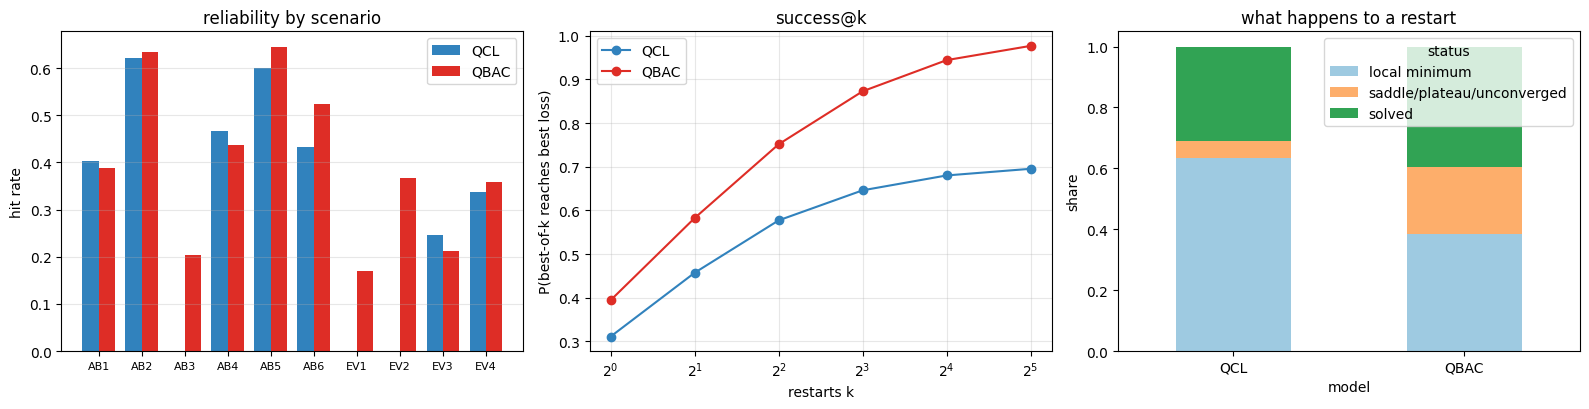


TABLE 6  FULL ABLATION  (hit = restart within 0.001 of the best loss found by ANY of the 15 variants; success = pooled over all restarts, Wilson 95% CI; paired diff = per-(scenario,target) hit-rate difference vs Q-BAC with bootstrap CI)
             block_params_per_arm  total_trainable  success  ci_lo  ci_hi  cells  cells_never_reach_best  paired_diff_vs_QBAC  diff_ci_lo  diff_ci_hi  max_abs_c3_random  can_make_c3  mean_c3_of_best_solutions
variant                                                                                                                                                                                                         
QCL                            12               36   0.3063 0.2881 0.3250     50                      16              -0.0837     -0.1342     -0.0400             0.0000        False                     0.0000
QBAC                           12               36   0.3900 0.3707 0.4097     50                       1               0.0000      0.00

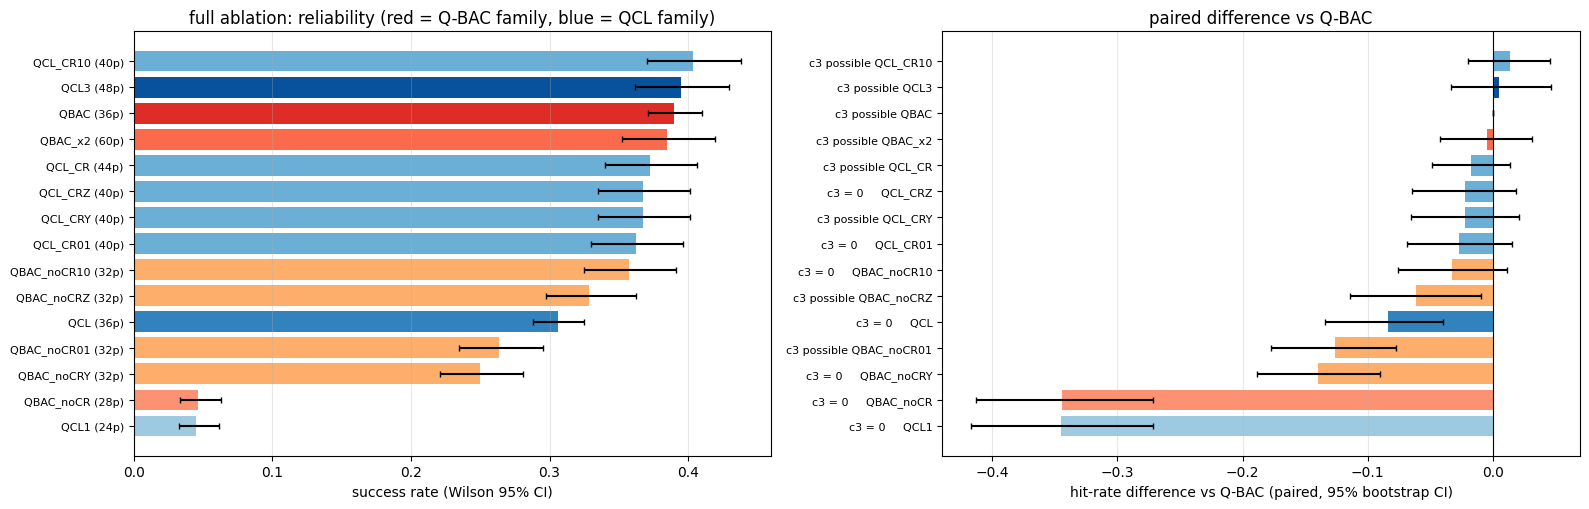

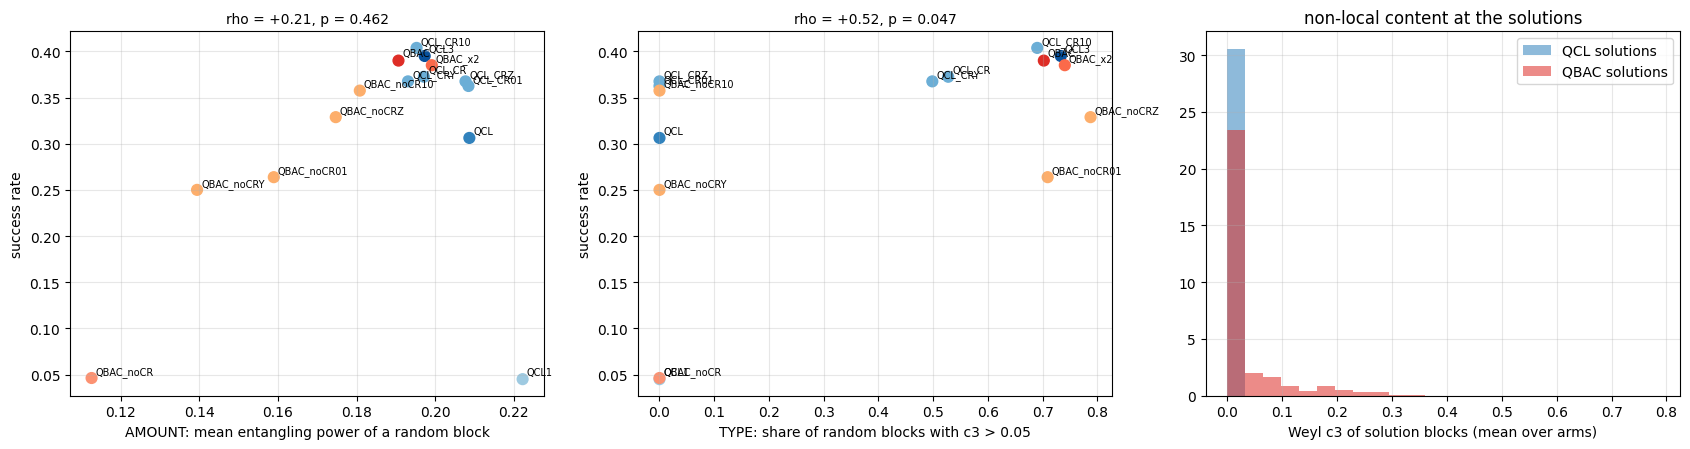

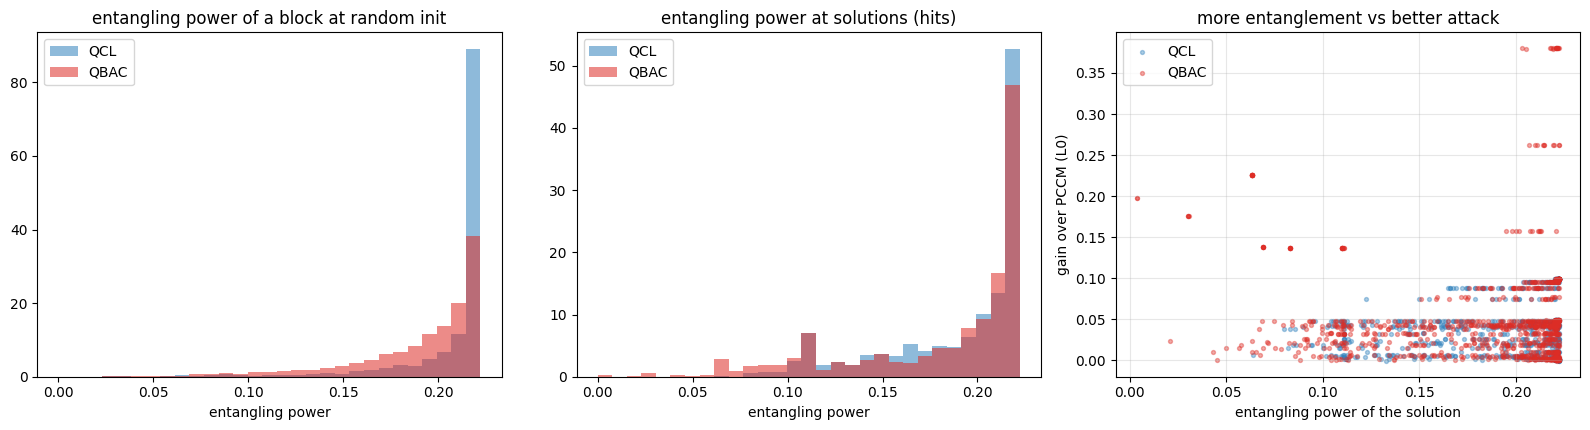

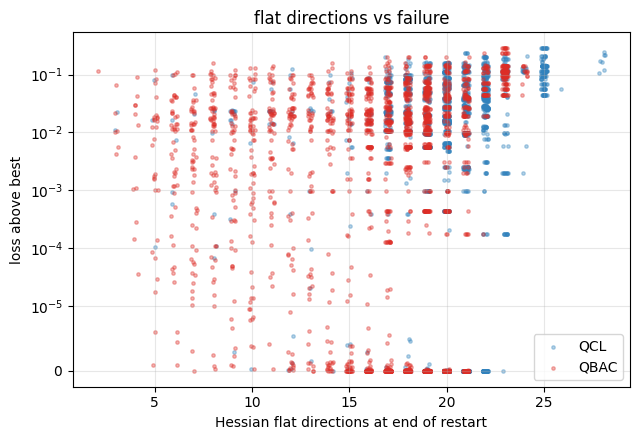


Saved: cell3_restarts.csv, cell3_xfit.csv, cell3_repr.csv, cell3_init.csv, cell3_params_<scen>.npz, cell3_fig1..5 PNG.


In [ ]:
# =====================================================================================================
# CELL 3 / 4  -  Is Q-BAC more RELIABLE than QCL, and where does it come from?   (BBM92, Eve on both arms, free training, strength 0.2)
#
# Part A  reliability : many paired restarts per (scenario, target); hit rate (restart reaches the best loss found by ANY model), spread, restarts needed
#                       for 95% success, success@k, seed-batch variance of best-of-k, failure anatomy (local minimum vs saddle/plateau, via the Hessian).
# Part B  mechanism   : (1) amount of entanglement: entangling power of each arm's block, at random initialisation and at the solutions
#                       (2) type of entanglement: Weyl-chamber coordinates (c1,c2,c3) and Makhlin invariants -> gate class (identity / CNOT / iSWAP / SWAP / generic)
#                           -> across the 15 variants: does the AMOUNT (entangling power) or the TYPE (c3, controlled-rotation direction) track reliability?
#                       (3) expressivity: can QCL represent Q-BAC's best block (and vice versa)?  warm-start transfer: if not representable, does training from the fitted point recover the loss?
#                       (4) landscape: gradient statistics at random initialisation, Hessian flat directions, block-Jacobian rank (parameter redundancy)
#                       (5) FULL ablation of both ansatzes (15 variants): QCL depth (1/3 layers), QCL + controlled rotations added back (CRY, CRZ, Bob->ancilla CR01, ancilla->Bob CR10, all),
#                           Q-BAC with controlled rotations removed (noCRZ, noCRY, noCR01, noCR10, none) and Q-BAC repeated twice.  Each variant: Wilson CI, paired difference vs Q-BAC,
#                           can it make non-local content (Weyl c3 != 0), and can it even REPRESENT Q-BAC's best blocks?
# Preflight checks the simulator (independent NumPy re-implementation) AND the entanglement measures against known gates and a Monte-Carlo estimate.
# Resume   : each scenario is saved (cell3_restarts.csv, cell3_params_<scen>.npz, cell3_xfit.csv); re-running skips finished scenarios.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W = 0.2, 1000.0
GAIN_TOL, HIT_TOL, SEED = 1e-3, 1e-3, 0
MODELS_A = ["QCL", "QBAC"]
MODELS_B = ["QCL1", "QCL3", "QCL_CRY", "QCL_CRZ", "QCL_CR01", "QCL_CR10", "QCL_CR", "QBAC_noCRZ", "QBAC_noCRY", "QBAC_noCR01", "QBAC_noCR10", "QBAC_noCR", "QBAC_x2"]
if MODE == "DEV": TARGETS, RA, NB, RB, GRID_N, MAXITER, SCEN_IDS, N_INIT, N_XSTART, N_REPR = [0.65, 0.85], 8, 2, 3, 41, 400, ["AB1", "AB5", "EV2"], 300, 6, 3
else:             TARGETS, RA, NB, RB, GRID_N, MAXITER, SCEN_IDS, N_INIT, N_XSTART, N_REPR = [0.55, 0.65, 0.75, 0.85, 0.95], 48, 3, 16, 91, 500, None, 2000, 24, 8
RST_CSV, XF_CSV, INIT_CSV, REPR_CSV = "cell3_restarts.csv", "cell3_xfit.csv", "cell3_init.csv", "cell3_repr.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if sc is SCEN[0] else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# ----------------------------------------------------------------------------------------------- entanglement measures (NumPy)
SWAP4 = SWAP
def op_schmidt(U):                         # normalised operator-Schmidt spectrum of a 2-qubit gate
    s = np.linalg.svd(U.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4), compute_uv=False); return s ** 2 / 4
def E_op(U): return 1 - np.sum(op_schmidt(U) ** 2)
def ent_power(U): return 4 / 9 * (E_op(U) + E_op(U @ SWAP4) - 3 / 4)           # Zanardi; qubits; max 2/9
QM = np.array([[1, 0, 0, 1j], [0, 1j, 1, 0], [0, 1j, -1, 0], [1, 0, 0, -1j]]) / np.sqrt(2)
def makhlin(U):
    UB = QM.conj().T @ U @ QM; m = UB.T @ UB; d = np.linalg.det(U); t = np.trace(m)
    return t ** 2 / (16 * d), (t ** 2 - np.trace(m @ m)) / (4 * d)           # G1 (complex), G2 (real)
REF = {"identity": (1, 3), "CNOT": (0, 1), "iSWAP": (0, -1), "SWAP": (-1, -3)}
def gate_class(U, tol=0.25):
    g1, g2 = makhlin(U); d = {k: np.sqrt(abs(g1 - a) ** 2 + (g2.real - b) ** 2) for k, (a, b) in REF.items()}; k = min(d, key=d.get); return k if d[k] < tol else "generic"
def weyl(U):                               # reduced Weyl coordinates (c1>=c2>=c3>=0, each folded into [0, pi/4]; mirror images identified)
    U = U / np.linalg.det(U) ** 0.25; UB = QM.conj().T @ U @ QM; ph = np.sort(np.angle(np.linalg.eigvals(UB.T @ UB)) / 2)[::-1]; s = int(np.round(ph.sum() / np.pi))
    if s > 0: ph[:s] -= np.pi
    elif s < 0: ph[s:] += np.pi
    x = [(ph[0] + ph[1]) / 2, (ph[0] + ph[2]) / 2, (ph[0] + ph[3]) / 2]
    return np.array(sorted([min(abs(t) % (np.pi / 2), np.pi / 2 - abs(t) % (np.pi / 2)) for t in x], reverse=True))
def canon(c):
    from scipy.linalg import expm
    X, Y, Z = np.array([[0, 1], [1, 0]], complex), np.array([[0, -1j], [1j, 0]]), np.diag([1., -1]).astype(complex)
    return expm(1j * (c[0] * np.kron(X, X) + c[1] * np.kron(Y, Y) + c[2] * np.kron(Z, Z)))
def mc_ent_power(U, n=40000, rng=np.random.default_rng(5)):
    def haar(n): v = rng.normal(size=(n, 2)) + 1j * rng.normal(size=(n, 2)); return v / np.linalg.norm(v, axis=1, keepdims=True)
    psi = np.einsum("ni,nj->nij", haar(n), haar(n)).reshape(n, 4) @ U.T; psi = psi.reshape(n, 2, 2); rho = np.einsum("nia,nja->nij", psi, psi.conj())
    return float(np.mean(1 - np.real(np.einsum("nij,nji->n", rho, rho))))
def check_entanglement():
    CN = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], complex); ISW = np.array([[1, 0, 0, 0], [0, 0, 1j, 0], [0, 1j, 0, 0], [0, 0, 0, 1]], complex); ok = True
    for nm, U, ep in (("identity", np.eye(4, dtype=complex), 0.), ("SWAP", SWAP4, 0.), ("CNOT", CN, 2/9), ("iSWAP", ISW, 2/9)):
        e = ent_power(U); mc = mc_ent_power(U); g = makhlin(U); cl = gate_class(U); good = abs(e - ep) < 1e-9 and abs(e - mc) < 0.01 and cl == (nm if nm in REF else cl)
        print(f"  [{'OK' if good else 'FAIL'}] {nm:8s} entangling power {e:.4f} (exact {ep:.4f}, Monte-Carlo {mc:.4f})  Makhlin G=({g[0]:.2f},{g[1].real:.2f}) class={cl}"); ok &= good
    rng = np.random.default_rng(9); a = np.asarray(block_unitary(OPS["QBAC"], jnp.asarray(rng.uniform(-3, 3, 12)))); e, mc = ent_power(a), mc_ent_power(a)
    print(f"  [{'OK' if abs(e-mc) < 0.01 else 'FAIL'}] random Q-BAC block: entangling power {e:.4f} vs Monte-Carlo {mc:.4f}"); ok &= abs(e - mc) < 0.01
    B = np.kron(np.asarray(RY(0.3)), np.asarray(RX(0.7))) @ CN @ np.kron(np.asarray(RZ(1.1)), np.asarray(RY(0.2)))                  # local equivalence: invariants unchanged by local gates
    d = abs(makhlin(B)[0] - makhlin(CN)[0]) + abs(makhlin(B)[1] - makhlin(CN)[1]); print(f"  [{'OK' if d < 1e-9 else 'FAIL'}] Makhlin invariants invariant under local gates (dev {d:.1e})"); ok &= d < 1e-9
    for nm, U, c in (("identity", np.eye(4, dtype=complex), (0, 0, 0)), ("CNOT", CN, (np.pi/4, 0, 0)), ("iSWAP", ISW, (np.pi/4, np.pi/4, 0)), ("SWAP", SWAP4, (np.pi/4, np.pi/4, np.pi/4))):
        w = weyl(U); good = np.abs(w - np.array(c)).max() < 1e-7; print(f"  [{'OK' if good else 'FAIL'}] Weyl coordinates of {nm}: {np.round(w / np.pi * 4, 4)} x pi/4 (expected {np.round(np.array(c) / np.pi * 4, 4)})"); ok &= good
    rng = np.random.default_rng(11); worst = 0.
    for _ in range(300):                                                                       # random canonical gates dressed with random local gates must come back reduced
        c = rng.uniform(-np.pi, np.pi, 3); L1 = np.kron(np.asarray(RZ(rng.uniform(0, 6))) @ np.asarray(RY(rng.uniform(0, 6))), np.asarray(RX(rng.uniform(0, 6))) @ np.asarray(RZ(rng.uniform(0, 6))))
        L2 = np.kron(np.asarray(RX(rng.uniform(0, 6))) @ np.asarray(RY(rng.uniform(0, 6))), np.asarray(RZ(rng.uniform(0, 6))) @ np.asarray(RX(rng.uniform(0, 6))))
        exp_ = np.sort(np.array([min(abs(t) % (np.pi/2), np.pi/2 - abs(t) % (np.pi/2)) for t in c]))[::-1]; worst = max(worst, np.abs(weyl(L1 @ canon(c) @ L2) - exp_).max())
    print(f"  [{'OK' if worst < 1e-6 else 'FAIL'}] Weyl coordinates recovered from 300 random locally-dressed canonical gates (max dev {worst:.1e})"); ok &= worst < 1e-6
    assert ok, "ENTANGLEMENT-MEASURE CHECK FAILED"

# ----------------------------------------------------------------------------------------------- helpers for diagnostics
import json
from scipy import stats
ALL_M = MODELS_A + MODELS_B
bu = {m: jax.jit(jax.vmap(lambda p, m=m: block_unitary(OPS[m], p))) for m in OPS if m != "PCCM"}                              # batch of parameter vectors -> blocks
def _vec(p, m): U = block_unitary(OPS[m], p).ravel(); return jnp.concatenate([U.real, U.imag])
bj = {m: jax.jit(jax.vmap(jax.jacfwd(lambda p, m=m: _vec(p, m)))) for m in OPS if m != "PCCM"}
def jac_rank(m, P): return np.array([np.sum(np.linalg.svd(J, compute_uv=False) > 1e-7) for J in np.asarray(bj[m](jnp.asarray(P)))])
def make_fit(src_ops, n):
    def d(p, U): V = block_unitary(src_ops, p); return 1 - jnp.abs(jnp.trace(U.conj().T @ V)) ** 2 / 16
    return jax.jit(jax.value_and_grad(d))
FIT = {m: make_fit(OPS[m], NP_[m]) for m in OPS if m != "PCCM"}
def xfit(m, U, rng, n_start):
    best = (9., None)
    for _ in range(n_start):
        o = minimize(lambda p: (lambda r: (float(r[0]), np.asarray(r[1], float)))(FIT[m](jnp.asarray(p), jnp.asarray(U))), rng.uniform(-np.pi, np.pi, NP_[m]), jac=True, method="L-BFGS-B", options=dict(ftol=1e-15, gtol=1e-12, maxiter=400))
        if o.fun < best[0]: best = (float(o.fun), o.x)
        if best[0] < 1e-11: break
    return best

# ----------------------------------------------------------------------------------------------- main loop
preflight(); print("ENTANGLEMENT-MEASURE CHECKS"); check_entanglement(); print("  ALL PASSED\n")
done = set(pd.read_csv(RST_CSV).scen.unique()) if os.path.exists(RST_CSV) else set()
nA, nB = len(SCEN) * len(TARGETS) * len(MODELS_A) * RA, len(SCEN) * len(TARGETS) * len(MODELS_B) * RB
print(f"MODE={MODE}: Part A {nA} trainings + Part B ablations {nB} trainings (~{(nA+nB)*0.35/60:.0f} min) + Hessians / expressivity fits", flush=True)
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
for (sid, group, label, pre, post, src) in SCEN:
    if sid in done: print(f"  {sid} already done, skipped"); continue
    eng = make_engines(make_sim(pre, post, src)); base = eng["base"](STRENGTH); rst, xf, init, store, rep_ = [], [], [], {}, []
    for f in TARGETS:
        _, _, ap = fit_pccm(eng, f, base, 0., 0., 1., 1., G); P0 = L0_of(ap, f); args = (f, STRENGTH, base, 0., 0., 1., 1.)
        startsA = rng_for("A", sid, f).uniform(-np.pi, np.pi, (RA, 36)); best = {}
        for m in ALL_M:
            n = NP_[m]; R_ = RA if m in MODELS_A else RB; S = startsA if m in MODELS_A else rng_for("B", sid, f, m).uniform(-np.pi, np.pi, (R_, 2 * n + 12))
            X, rec = [], []
            for r_ in range(R_):
                o = run_min(eng[m], S[r_], args, MAXITER); (l, aux), _ = eng[m](jnp.asarray(o.x), *args); aux = np.asarray(aux)
                rec.append(dict(scen=sid, target=f, model=m, restart=r_, batch=r_ // max(R_ // NB, 1), loss_pen=float(l), L0=L0_of(aux, f), PCCM_L0=P0, ImbAB=abs(aux[0]-aux[2]), ImbAE=abs(aux[1]-aux[3]),
                                gnorm=float(np.linalg.norm(o.jac)), nit=int(o.nit), conv=bool(o.success))); X.append(o.x)
            X = np.array(X); store[f"{m}|{f}"] = X
            if m in MODELS_A:                                                                                           # Hessian + parameter-redundancy diagnostics
                rk = jac_rank(m, X[:, :n]); rkB = jac_rank(m, X[:, n:2*n])
                for r_, x in enumerate(X):
                    Hs = np.asarray(eng[m + "_h"](jnp.asarray(x), *args)); Hs = (Hs + Hs.T) / 2; ev = np.linalg.eigvalsh(Hs); eps = 1e-7 * max(abs(ev).max(), 1e-3)
                    rec[r_].update(n_neg=int((ev < -eps).sum()), n_flat=int((abs(ev) <= eps).sum()), eig_min=float(ev[0]), eig_max=float(ev[-1]), rankA=int(rk[r_]), rankB=int(rkB[r_]))
            rst += rec; best[m] = X[int(np.argmin([r["loss_pen"] for r in rec]))]
        for src_m, dst_m in (("QBAC", "QCL"), ("QCL", "QBAC")):                                                          # expressivity: can dst_m represent src_m's best blocks?
            xs = best[src_m]; ns, nd = NP_[src_m], NP_[dst_m]; rng = rng_for("xf", sid, f, src_m); fits, ds = [], []
            for arm in (0, 1):
                U = np.asarray(block_unitary(OPS[src_m], jnp.asarray(xs[arm*ns:(arm+1)*ns]))); d, p = xfit(dst_m, U, rng, N_XSTART); ds.append(d); fits.append(p)
            x0 = np.concatenate(fits + [xs[2*ns:]]); (ls, _), _ = eng[src_m](jnp.asarray(xs), *args); (l0, _), _ = eng[dst_m](jnp.asarray(x0), *args)
            o = run_min(eng[dst_m], x0, args, MAXITER); ldst = min(r["loss_pen"] for r in rst if r["scen"] == sid and r["target"] == f and r["model"] == dst_m)
            xf.append(dict(scen=sid, target=f, src=src_m, dst=dst_m, distA=ds[0], distB=ds[1], loss_src=float(ls), loss_at_fit=float(l0), loss_warm=float(o.fun), loss_dst_native_best=ldst))
        xs = best["QBAC"]; ns = NP_["QBAC"]; rng = rng_for("repr", sid, f); Ub = [np.asarray(block_unitary(OPS["QBAC"], jnp.asarray(xs[a * ns:(a + 1) * ns]))) for a in (0, 1)]
        for m in ALL_M:                                                                                                   # can every variant even REPRESENT Q-BAC's best blocks?
            if m != "QBAC": rep_.append(dict(scen=sid, target=f, dst=m, dist=max(xfit(m, U, rng, N_REPR)[0] for U in Ub)))
        if f == 0.75 or f == TARGETS[len(TARGETS) // 2]:                                                              # landscape at random initialisation
            for m in MODELS_A:
                X0 = np.random.default_rng(zlib.crc32(repr((SEED, "init", sid, m)).encode())).uniform(-np.pi, np.pi, (N_INIT, 2 * NP_[m] + 12))
                vm = jax.jit(jax.vmap(eng[m], in_axes=(0,) + (None,) * 7)); (l, aux), g = vm(jnp.asarray(X0), *args); g = np.asarray(g); aux = np.asarray(aux)
                L0i = 10 * ((aux[:, 0] + aux[:, 2]) / 2 - f) ** 2 - (aux[:, 1] + aux[:, 3]) / 2
                init.append(dict(scen=sid, target=f, model=m, gvar=float(np.mean(g.var(0))), gnorm=float(np.mean(np.linalg.norm(g, axis=1))), L0_init_mean=float(L0i.mean()), frac_better_than_pccm=float((L0i < P0).mean())))
    pd.DataFrame(rst).to_csv(RST_CSV, mode="a", header=not os.path.exists(RST_CSV), index=False); pd.DataFrame(xf).to_csv(XF_CSV, mode="a", header=not os.path.exists(XF_CSV), index=False); pd.DataFrame(rep_).to_csv(REPR_CSV, mode="a", header=not os.path.exists(REPR_CSV), index=False)
    pd.DataFrame(init).to_csv(INIT_CSV, mode="a", header=not os.path.exists(INIT_CSV), index=False); np.savez_compressed(f"cell3_params_{sid}.npz", **store)
    print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis
ids = [s[0] for s in SCEN]; RS = pd.read_csv(RST_CSV); RS = RS[RS.scen.isin(ids)]; XF = pd.read_csv(XF_CSV); XF = XF[XF.scen.isin(ids)]; RP = pd.read_csv(REPR_CSV); RP = RP[RP.scen.isin(ids)]; IN = pd.read_csv(INIT_CSV); IN = IN[IN.scen.isin(ids)]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 400); pd.set_option("display.float_format", "{:.4f}".format)
RS["best_all"] = RS.groupby(["scen", "target"]).loss_pen.transform("min"); RS["hit_all"] = RS.loss_pen <= RS.best_all + HIT_TOL                       # vs best of all 15 variants
RS["best"] = RS[RS.model.isin(MODELS_A)].groupby(["scen", "target"]).loss_pen.transform("min").reindex(RS.index); RS["best"] = RS.groupby(["scen", "target"]).best.transform("max"); RS["hit"] = RS.loss_pen <= RS.best + HIT_TOL   # head-to-head: vs best of QCL and Q-BAC only
RS["gain_found"] = (RS.PCCM_L0 - RS.L0) > GAIN_TOL
def colr(m): return "#de2d26" if m == "QBAC" else "#3182bd" if m == "QCL" else ("#fb6a4a" if "x2" in m else "#fc9272" if m.endswith("noCR") else "#fdae6b") if m.startswith("QBAC") else ("#08519c" if m == "QCL3" else "#9ecae1" if m == "QCL1" else "#6baed6")
col = {m: colr(m) for m in ALL_M}; rngb = np.random.default_rng(1)
H = RS.groupby(["scen", "target", "model"]).agg(hit=("hit", "mean"), hit_all=("hit_all", "mean"), spread=("loss_pen", "std"), gain_found=("gain_found", "mean"), bestL0=("L0", "min")).reset_index()
H["need95"] = np.where(H.hit_all >= 1, 1, np.where(H.hit_all > 0, np.ceil(np.log(0.05) / np.log(1 - H.hit_all.clip(upper=1 - 1e-12))), 999.))      # 999 = never reached in any restart
print("\n" + "=" * 110); print(f"TABLE 1  RELIABILITY (free training, Eve on both arms).  hit_all = restart within {HIT_TOL} of the best loss found by ANY of the {len(ALL_M)} ansatzes; cells = (scenario,target); need95 = restarts for 95% success (999 = never hit)")
t1 = H.groupby("model").agg(cells=("hit", "size"), hit_mean=("hit_all", "mean"), hit_median=("hit_all", "median"), cells_never_hit=("hit_all", lambda x: int((x == 0).sum())), need95_median=("need95", "median"), need95_p90=("need95", lambda x: np.percentile(x, 90)),
                            spread=("spread", "mean"), gain_found_rate=("gain_found", "mean")).loc[ALL_M]; t1.insert(0, "n_params", [2 * NP_[m] + 12 for m in t1.index]); print(t1.to_string())
print("\n  head-to-head (hit measured against the best of QCL and Q-BAC only): mean hit  " + ", ".join(f"{m} {H[H.model == m].hit.mean():.3f}" for m in MODELS_A))
print("  paired Q-BAC minus QCL over (scenario,target) cells"); HW = H.pivot_table(index=["scen", "target"], columns="model", values="hit").reset_index(); d = (HW.QBAC - HW.QCL).values; bs = [rngb.choice(d, len(d)).mean() for _ in range(5000)]
try: pw = stats.wilcoxon(d[d != 0]).pvalue
except Exception: pw = np.nan
print(f"    mean hit difference {d.mean():+.4f}  95% CI [{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]   Q-BAC higher in {(d > .05).sum()} cells, QCL higher in {(d < -.05).sum()}, similar in {(abs(d) <= .05).sum()}   Wilcoxon p={pw:.3g}")
print("\n" + "=" * 110); print("TABLE 2  Hit rate by scenario (mean over targets)"); t2 = H[H.model.isin(MODELS_A)].groupby(["scen", "model"]).hit.mean().unstack("model"); t2["QBAC-QCL"] = t2.QBAC - t2.QCL; print(t2.to_string())
print("\n" + "=" * 110); print("TABLE 3  success@k : probability that best-of-k restarts reaches the best loss (from the measured hit rates, mean over cells)")
ks = [1, 2, 4, 8, 16, 32]; print(pd.DataFrame({m: [float(np.mean(1 - (1 - H[H.model == m].hit.values) ** k)) for k in ks] for m in MODELS_A}, index=[f"k={k}" for k in ks]).to_string())
print("\n  seed-batch variance: std over the batches of the best-of-batch L0 (mean over cells)")
bb = RS[RS.model.isin(MODELS_A)].groupby(["scen", "target", "model", "batch"]).L0.min().reset_index().groupby(["scen", "target", "model"]).L0.agg(["std", "max", "min"]).reset_index(); bb["range"] = bb["max"] - bb["min"]
print(bb.groupby("model")[["std", "range"]].mean().to_string())
print("\n" + "=" * 110); print("TABLE 4  FAILURE ANATOMY (Hessian at the end of each restart).  solved = hit ; local minimum = not solved, no negative curvature, small gradient ; saddle/plateau = negative curvature or gradient not small")
A = RS[RS.model.isin(MODELS_A)].copy(); A["status"] = np.where(A.hit, "solved", np.where((A.n_neg == 0) & (A.gnorm < 1e-4), "local minimum", "saddle/plateau/unconverged"))
print(A.groupby("model").status.value_counts(normalize=True).unstack().fillna(0).to_string())
print("\n  Hessian flat directions and block-parametrisation rank (max rank of a 2-qubit unitary mod phase = 15)")
print(A.assign(solved=A.hit).groupby(["model", "solved"]).agg(n=("hit", "size"), n_flat=("n_flat", "mean"), n_neg=("n_neg", "mean"), rankA=("rankA", "mean"), rankB=("rankB", "mean"), gnorm=("gnorm", "median")).to_string())
print("\n" + "=" * 110); print("TABLE 5  LANDSCAPE AT RANDOM INITIALISATION (one mid target per scenario)")
print(IN.groupby("model").agg(grad_variance=("gvar", "mean"), grad_norm=("gnorm", "mean"), mean_L0_at_init=("L0_init_mean", "mean"), share_of_random_starts_already_better_than_PCCM=("frac_better_than_pccm", "mean")).to_string())

# ----------------------------------------------------------------------------------------------- figures
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2)); sc_ids = list(dict.fromkeys(RS.scen)); xx = np.arange(len(sc_ids)); w = .38
for i, m in enumerate(MODELS_A): g = H[H.model == m].groupby("scen").hit.mean().reindex(sc_ids); axs[0].bar(xx + (i - .5) * w, g.values, w, color=col[m], label=m)
axs[0].set_xticks(xx); axs[0].set_xticklabels(sc_ids, fontsize=8); axs[0].set_ylabel("hit rate"); axs[0].set_title("reliability by scenario"); axs[0].legend(); axs[0].grid(alpha=.3, axis="y")
for m in MODELS_A: axs[1].plot(ks, [float(np.mean(1 - (1 - H[H.model == m].hit.values) ** k)) for k in ks], "o-", color=col[m], label=m)
axs[1].set_xscale("log", base=2); axs[1].set_xlabel("restarts k"); axs[1].set_ylabel("P(best-of-k reaches best loss)"); axs[1].set_title("success@k"); axs[1].legend(); axs[1].grid(alpha=.3)
st = A.groupby("model").status.value_counts(normalize=True).unstack().fillna(0).reindex(MODELS_A); st.plot(kind="bar", stacked=True, ax=axs[2], color=["#9ecae1", "#fdae6b", "#31a354"][:st.shape[1]], rot=0); axs[2].set_title("what happens to a restart"); axs[2].set_ylabel("share")
plt.tight_layout(); plt.savefig("cell3_fig1_reliability.png", dpi=150); plt.show()

# ----------------------------------------------------------------------------------------------- entanglement of every trained block (AMOUNT = entangling power, TYPE = Weyl coordinates / gate class)
P = []
for sid in ids:
    Z = np.load(f"cell3_params_{sid}.npz")
    for key in Z.files:
        m, f = key.split("|"); X = Z[key]; n = NP_[m]; sub = RS[(RS.scen == sid) & (RS.target == float(f)) & (RS.model == m)].sort_values("restart")
        UA, UB = np.asarray(bu[m](jnp.asarray(X[:, :n]))), np.asarray(bu[m](jnp.asarray(X[:, n:2 * n])))
        for r_ in range(len(X)):
            wA, wB = weyl(UA[r_]), weyl(UB[r_])
            P.append(dict(scen=sid, target=float(f), model=m, restart=r_, hit=bool(sub.hit_all.iloc[r_]), L0=sub.L0.iloc[r_], PCCM_L0=sub.PCCM_L0.iloc[r_], epA=ent_power(UA[r_]), epB=ent_power(UB[r_]),
                          clsA=gate_class(UA[r_]), clsB=gate_class(UB[r_]), c1=(wA[0] + wB[0]) / 2, c2=(wA[1] + wB[1]) / 2, c3=(wA[2] + wB[2]) / 2, c3max=max(wA[2], wB[2])))
P = pd.DataFrame(P); P["ep"] = (P.epA + P.epB) / 2; P["gain"] = P.PCCM_L0 - P.L0
rngi = np.random.default_rng(3); INI = {}
for m in ALL_M:
    Us = np.asarray(bu[m](jnp.asarray(rngi.uniform(-np.pi, np.pi, (3000, NP_[m]))))); W_ = np.array([weyl(U) for U in Us]); INI[m] = dict(ep=np.array([ent_power(U) for U in Us]), c1=W_[:, 0], c2=W_[:, 1], c3=W_[:, 2])
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - h) / d, (c + h) / d
C3_ON = 0.05                                                                                                                        # |c3| above this counts as "non-local content beyond a CNOT/iSWAP-type gate"
print("\n" + "=" * 140); print(f"TABLE 6  FULL ABLATION  (hit = restart within {HIT_TOL} of the best loss found by ANY of the {len(ALL_M)} variants; success = pooled over all restarts, Wilson 95% CI; paired diff = per-(scenario,target) hit-rate difference vs Q-BAC with bootstrap CI)")
Hq = H[H.model == "QBAC"].set_index(["scen", "target"]).hit_all; rows = []
for m in ALL_M:
    g = RS[RS.model == m]; k, n = int(g.hit_all.sum()), len(g); lo, hi = wilson(k, n); Hm = H[H.model == m].set_index(["scen", "target"]).hit_all; d = (Hm - Hq).values; bs = [rngb.choice(d, len(d)).mean() for _ in range(2000)]
    rows.append(dict(variant=m, block_params_per_arm=NP_[m], total_trainable=2 * NP_[m] + 12, success=k / n, ci_lo=lo, ci_hi=hi, cells=len(Hm), cells_never_reach_best=int((Hm == 0).sum()), paired_diff_vs_QBAC=d.mean(),
                     diff_ci_lo=np.percentile(bs, 2.5), diff_ci_hi=np.percentile(bs, 97.5), max_abs_c3_random=INI[m]["c3"].max(), can_make_c3=bool(INI[m]["c3"].max() > C3_ON), mean_c3_of_best_solutions=P[(P.model == m) & P.hit].c3.mean()))
T6 = pd.DataFrame(rows).set_index("variant"); print(T6.to_string())
print("\n" + "=" * 140); print("TABLE 7  AMOUNT vs TYPE of entanglement, per variant.  amount = entangling power (max 2/9) ; type = Weyl coordinates (CNOT = (pi/4,0,0) ; iSWAP = (pi/4,pi/4,0) ; SWAP = (pi/4,pi/4,pi/4), shown in units of pi/4)")
rows = []
for m in ALL_M:
    s_ = P[(P.model == m) & P.hit]; rows.append(dict(variant=m, success=T6.loc[m, "success"], ep_random_init=INI[m]["ep"].mean(), ep_solutions=s_.ep.mean(), c1_init=INI[m]["c1"].mean() * 4 / np.pi, c2_init=INI[m]["c2"].mean() * 4 / np.pi, c3_init=INI[m]["c3"].mean() * 4 / np.pi,
                                                    share_init_c3_on=float((INI[m]["c3"] > C3_ON).mean()), c1_sol=s_.c1.mean() * 4 / np.pi, c2_sol=s_.c2.mean() * 4 / np.pi, c3_sol=s_.c3.mean() * 4 / np.pi, share_sol_c3_on=float((s_.c3max > C3_ON).mean()) if len(s_) else np.nan))
T7 = pd.DataFrame(rows).set_index("variant"); print(T7.to_string())
print("\n  Spearman across the variants (n = %d): does reliability track the AMOUNT or the TYPE of entanglement?" % len(T7))
for lab_, c_ in (("amount: entangling power at random init", "ep_random_init"), ("amount: entangling power at solutions", "ep_solutions"), ("type: mean c3 at random init", "c3_init"), ("type: share of random blocks with c3 > %.2f" % C3_ON, "share_init_c3_on"), ("type: mean c3 at solutions", "c3_sol")):
    ok_ = T7[c_].notna(); r_, p_ = stats.spearmanr(T7.loc[ok_, c_], T7.loc[ok_, "success"]); print(f"    success vs {lab_:52s} rho = {r_:+.2f}   p = {p_:.3f}   (n={int(ok_.sum())})")
print("\n  solution level: does MORE entanglement buy a BETTER attack?  Spearman(entangling power, gain over PCCM) over all restarts, and over the hits only")
print(pd.DataFrame({m: dict(all_restarts=stats.spearmanr(P[P.model == m].ep, P[P.model == m].gain)[0], hits_only=(stats.spearmanr(P[(P.model == m) & P.hit].ep, P[(P.model == m) & P.hit].gain)[0] if (P[(P.model == m)].hit.sum() > 4) else np.nan)) for m in ALL_M}).T.to_string())
print("\n" + "=" * 140); print("TABLE 8  TYPE of two-qubit gate in the solutions (hits): share of arms by Makhlin class")
Cc = pd.concat([P[P.hit][["model", "clsA"]].rename(columns={"clsA": "cls"}), P[P.hit][["model", "clsB"]].rename(columns={"clsB": "cls"})]); print(Cc.groupby("model").cls.value_counts(normalize=True).unstack().fillna(0).reindex(ALL_M).to_string())
print("\n" + "=" * 140); print("TABLE 9  EXPRESSIVITY  (a) can each variant REPRESENT Q-BAC's best blocks?  dist = 1 - |Tr(U'V)|^2/16, best of multi-start fit, max over the two arms; representable = dist < 1e-6")
RP["representable"] = RP.dist < 1e-6; print(RP.groupby("dst").agg(cells=("scen", "size"), representable=("representable", "mean"), median_dist=("dist", "median")).reindex([m for m in ALL_M if m != "QBAC"]).to_string())
print("  (b) QCL <-> Q-BAC both ways, with warm-start transfer")
XF["dist"] = XF[["distA", "distB"]].max(axis=1); XF["representable"] = XF.dist < 1e-6; XF["warm_gap"] = XF.loss_warm - XF.loss_src; XF["native_gap"] = XF.loss_dst_native_best - XF.loss_src
print(XF.groupby(["src", "dst"]).agg(cells=("scen", "size"), representable=("representable", "mean"), median_dist=("dist", "median"), warm_gap_med=("warm_gap", "median"), native_gap_med=("native_gap", "median"), warm_closes_gap=("warm_gap", lambda x: float((x <= HIT_TOL).mean()))).to_string())
print("\n" + "=" * 140); print("TABLE 10  Median regret (penalised loss above the best over all variants) and share of restarts that found a gain over PCCM")
RS["regret"] = RS.loss_pen - RS.best_all; print(RS.groupby("model").agg(hit=("hit_all", "mean"), median_regret=("regret", "median"), mean_regret=("regret", "mean"), gain_found=("gain_found", "mean")).reindex(ALL_M).to_string())

# ----------------------------------------------------------------------------------------------- figures
order = list(T6.sort_values("success").index); fig, axs = plt.subplots(1, 2, figsize=(16, 5.2)); y_ = np.arange(len(order))
axs[0].barh(y_, T6.loc[order, "success"], color=[col[m] for m in order], xerr=[T6.loc[order, "success"] - T6.loc[order, "ci_lo"], T6.loc[order, "ci_hi"] - T6.loc[order, "success"]], capsize=2)
axs[0].set_yticks(y_); axs[0].set_yticklabels([f"{m} ({2 * NP_[m] + 12}p)" for m in order], fontsize=8); axs[0].set_xlabel("success rate (Wilson 95% CI)"); axs[0].set_title("full ablation: reliability (red = Q-BAC family, blue = QCL family)"); axs[0].grid(alpha=.3, axis="x")
axs[1].barh(y_, T6.loc[order, "paired_diff_vs_QBAC"], color=[col[m] for m in order], xerr=[T6.loc[order, "paired_diff_vs_QBAC"] - T6.loc[order, "diff_ci_lo"], T6.loc[order, "diff_ci_hi"] - T6.loc[order, "paired_diff_vs_QBAC"]], capsize=2)
axs[1].axvline(0, color="k", lw=.8); axs[1].set_yticks(y_); axs[1].set_yticklabels([("c3 possible " if T6.loc[m, "can_make_c3"] else "c3 = 0     ") + m for m in order], fontsize=8); axs[1].set_xlabel("hit-rate difference vs Q-BAC (paired, 95% bootstrap CI)"); axs[1].grid(alpha=.3, axis="x"); axs[1].set_title("paired difference vs Q-BAC")
plt.tight_layout(); plt.savefig("cell3_fig2_full_ablation.png", dpi=150); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (c_, lab_) in zip(axs[:2], (("ep_random_init", "AMOUNT: mean entangling power of a random block"), ("share_init_c3_on", f"TYPE: share of random blocks with c3 > {C3_ON}"))):
    ax.scatter(T7[c_], T7.success, c=[col[m] for m in T7.index], s=60)
    for m in T7.index: ax.annotate(m, (T7.loc[m, c_], T7.loc[m, "success"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    r_, p_ = stats.spearmanr(T7[c_], T7.success); ax.set_title(f"rho = {r_:+.2f}, p = {p_:.3f}", fontsize=10); ax.set_xlabel(lab_); ax.set_ylabel("success rate"); ax.grid(alpha=.3)
bins = np.linspace(0, np.pi / 4, 25)
for m in MODELS_A: axs[2].hist(P[(P.model == m) & P.hit].c3, bins=bins, alpha=.55, color=col[m], label=f"{m} solutions", density=True)
axs[2].set_xlabel("Weyl c3 of solution blocks (mean over arms)"); axs[2].legend(); axs[2].grid(alpha=.3); axs[2].set_title("non-local content at the solutions")
plt.tight_layout(); plt.savefig("cell3_fig3_amount_vs_type.png", dpi=150); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4)); bins = np.linspace(0, 2 / 9, 30)
for m in MODELS_A: axs[0].hist(INI[m]["ep"], bins=bins, alpha=.55, color=col[m], label=m, density=True)
axs[0].set_title("entangling power of a block at random init"); axs[0].set_xlabel("entangling power"); axs[0].legend()
for m in MODELS_A: axs[1].hist(P[(P.model == m) & P.hit].ep, bins=bins, alpha=.55, color=col[m], label=m, density=True)
axs[1].set_title("entangling power at solutions (hits)"); axs[1].set_xlabel("entangling power"); axs[1].legend()
for m in MODELS_A: g = P[(P.model == m) & P.hit]; axs[2].scatter(g.ep, g.gain, s=8, alpha=.4, color=col[m], label=m)
axs[2].set_xlabel("entangling power of the solution"); axs[2].set_ylabel("gain over PCCM (L0)"); axs[2].set_title("more entanglement vs better attack"); axs[2].legend(); axs[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig("cell3_fig4_entanglement_amount.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for m in MODELS_A: g = A[A.model == m]; ax.scatter(g.n_flat + np.random.default_rng(0).uniform(-.15, .15, len(g)), g.loss_pen - g.best, s=6, alpha=.35, color=col[m], label=m)
ax.set_yscale("symlog", linthresh=1e-5); ax.set_xlabel("Hessian flat directions at end of restart"); ax.set_ylabel("loss above best"); ax.set_title("flat directions vs failure"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("cell3_fig5_flat_directions.png", dpi=150); plt.show()
print("\nSaved: cell3_restarts.csv, cell3_xfit.csv, cell3_repr.csv, cell3_init.csv, cell3_params_<scen>.npz, cell3_fig1..5 PNG.")

TABLE A  Hit rate per scenario (mean over targets)
model   QCL  QCL1  QCL3  QCL+CRY  QCL+CRZ  QCL+CR01  QCL+CR10  QCL+CR  QBAC  noCRZ  noCRY  noCR01  noCR10  QBAC-noCR  QBAC-x2
scen                                                                                                                         
AB1   0.404 0.138 0.500    0.425    0.450     0.463     0.525   0.450 0.388  0.425  0.487   0.388   0.463      0.138    0.412
AB2   0.621 0.000 0.662    0.537    0.688     0.637     0.588   0.562 0.633  0.562  0.287   0.600   0.700      0.000    0.613
AB3   0.000 0.000 0.225    0.188    0.000     0.000     0.163   0.175 0.204  0.225  0.000   0.050   0.000      0.000    0.275
AB4   0.467 0.150 0.550    0.400    0.425     0.475     0.525   0.400 0.438  0.475  0.412   0.350   0.475      0.150    0.537
AB5   0.600 0.163 0.675    0.562    0.662     0.588     0.637   0.625 0.646  0.550  0.350   0.637   0.613      0.175    0.650
AB6   0.433 0.000 0.550    0.438    0.525     0.550     0.562   0.4

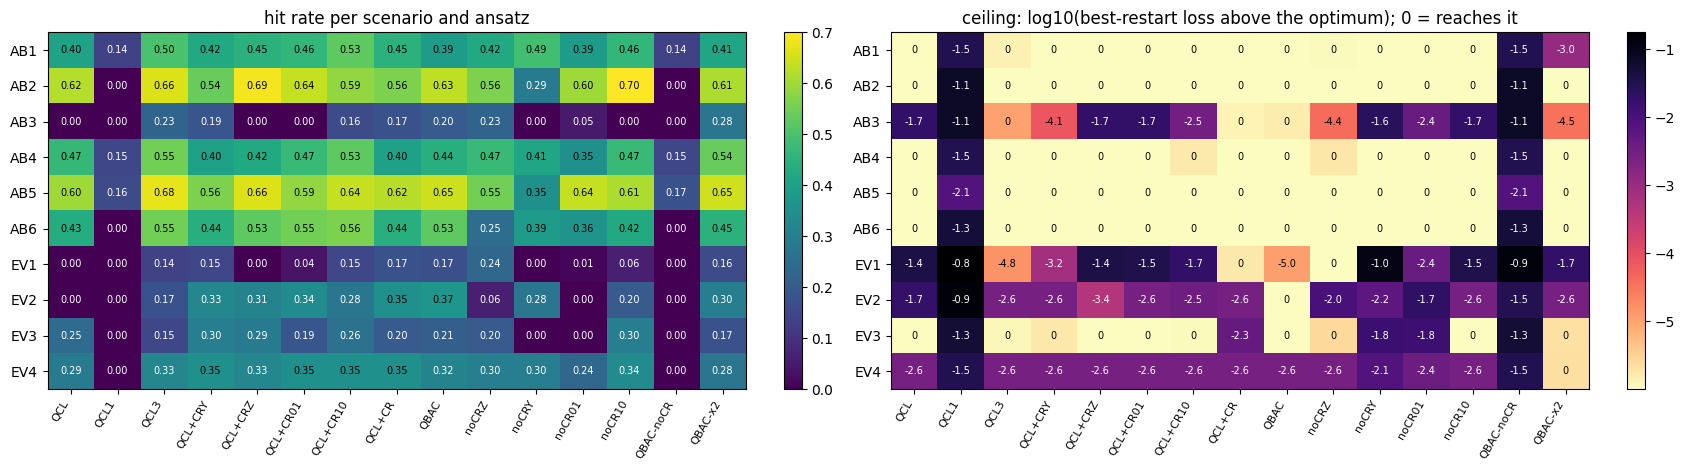


Saved: cell3b_scenario_ablation.png


In [ ]:
# =====================================================================================================
# CELL 3b  -  per-scenario view of the Cell 3 ablation: WHICH ingredient fixes the scenarios where QCL never reaches the optimum?
# Reads cell3_restarts.csv and cell3_params_<scen>.npz written by Cell 3 (no training, runs in about a minute).
#   Table A : hit rate per scenario x ansatz (share of restarts within HIT_TOL of the best loss found by any ansatz)
#   Table B : ceiling per scenario x ansatz = loss of the ansatz's BEST restart minus the best loss over all ansatzes (0 = the ansatz can reach the optimum at all)
#   Table C : what the optimum looks like per scenario: Weyl coordinates (units of pi/4), entangling power and gate class of the Q-BAC best solution vs the 2-layer QCL best solution
#   Table D : in the scenarios where QCL's ceiling is above tolerance, which variants close it
# =====================================================================================================
HIT_TOL = 1e-3
STRENGTH, MARG_W, GAIN_TOL, SEED, SCEN_IDS = 0.2, 1000.0, 1e-3, 0, None
MODELS_A = ["QCL", "QBAC"]
MODELS_B = ["QCL1", "QCL3", "QCL_CRY", "QCL_CRZ", "QCL_CR01", "QCL_CR10", "QCL_CR", "QBAC_noCRZ", "QBAC_noCRY", "QBAC_noCR01", "QBAC_noCR10", "QBAC_noCR", "QBAC_x2"]
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# ----------------------------------------------------------------------------------------------- entanglement measures (same definitions and checks as Cell 3)
SWAP4 = SWAP
def op_schmidt(U): s = np.linalg.svd(U.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4), compute_uv=False); return s ** 2 / 4
def E_op(U): return 1 - np.sum(op_schmidt(U) ** 2)
def ent_power(U): return 4 / 9 * (E_op(U) + E_op(U @ SWAP4) - 3 / 4)
QM = np.array([[1, 0, 0, 1j], [0, 1j, 1, 0], [0, 1j, -1, 0], [1, 0, 0, -1j]]) / np.sqrt(2)
def makhlin(U):
    UB = QM.conj().T @ U @ QM; m = UB.T @ UB; d = np.linalg.det(U); t = np.trace(m); return t ** 2 / (16 * d), (t ** 2 - np.trace(m @ m)) / (4 * d)
REF = {"identity": (1, 3), "CNOT": (0, 1), "iSWAP": (0, -1), "SWAP": (-1, -3)}
def gate_class(U, tol=0.25):
    g1, g2 = makhlin(U); d = {k: np.sqrt(abs(g1 - a) ** 2 + (g2.real - b) ** 2) for k, (a, b) in REF.items()}; k = min(d, key=d.get); return k if d[k] < tol else "generic"
def weyl(U):
    U = U / np.linalg.det(U) ** 0.25; UB = QM.conj().T @ U @ QM; ph = np.sort(np.angle(np.linalg.eigvals(UB.T @ UB)) / 2)[::-1]; s = int(np.round(ph.sum() / np.pi))
    if s > 0: ph[:s] -= np.pi
    elif s < 0: ph[s:] += np.pi
    x = [(ph[0] + ph[1]) / 2, (ph[0] + ph[2]) / 2, (ph[0] + ph[3]) / 2]
    return np.array(sorted([min(abs(t) % (np.pi / 2), np.pi / 2 - abs(t) % (np.pi / 2)) for t in x], reverse=True))

RS = pd.read_csv("cell3_restarts.csv"); ids = list(dict.fromkeys(RS.scen)); ALL = list(dict.fromkeys(RS.model))
RS["best_all"] = RS.groupby(["scen", "target"]).loss_pen.transform("min"); RS["hit"] = RS.loss_pen <= RS.best_all + HIT_TOL; RS["regret"] = RS.loss_pen - RS.best_all
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.3f}".format)
short = {"QBAC_noCRZ": "noCRZ", "QBAC_noCRY": "noCRY", "QBAC_noCR01": "noCR01", "QBAC_noCR10": "noCR10", "QBAC_noCR": "QBAC-noCR", "QBAC_x2": "QBAC-x2", "QCL_CRY": "QCL+CRY", "QCL_CRZ": "QCL+CRZ", "QCL_CR01": "QCL+CR01", "QCL_CR10": "QCL+CR10", "QCL_CR": "QCL+CR"}
cols = [m for m in ["QCL", "QCL1", "QCL3", "QCL_CRY", "QCL_CRZ", "QCL_CR01", "QCL_CR10", "QCL_CR", "QBAC", "QBAC_noCRZ", "QBAC_noCRY", "QBAC_noCR01", "QBAC_noCR10", "QBAC_noCR", "QBAC_x2"] if m in ALL]
print("=" * 150); print("TABLE A  Hit rate per scenario (mean over targets)")
A = RS.groupby(["scen", "model"]).hit.mean().unstack("model")[cols].rename(columns=short); print(A.to_string())
print("\n" + "=" * 150); print(f"TABLE B  Ceiling: loss of the ansatz's best restart minus the best loss over all ansatzes, mean over targets (a value above {HIT_TOL} = this ansatz never reached the optimum in that scenario)")
Bc = RS.groupby(["scen", "target", "model"]).regret.min().groupby(["scen", "model"]).mean().unstack("model")[cols].rename(columns=short); print(Bc.to_string())
print("\n  cells (scenario,target) in which the ansatz never reached the optimum, out of", RS.groupby(["scen", "target"]).ngroups // len(ids), "per scenario:")
Nc = (RS.groupby(["scen", "target", "model"]).regret.min() > HIT_TOL).groupby(["scen", "model"]).sum().unstack("model")[cols].rename(columns=short); print(Nc.to_string())
# ---- Table C : the best solution per (scen, target) for QCL and Q-BAC
rows = []
for sid in ids:
    Z = np.load(f"cell3_params_{sid}.npz")
    for m in ("QCL", "QBAC"):
        for key in [k for k in Z.files if k.startswith(m + "|")]:
            f = float(key.split("|")[1]); X = Z[key]; n = NP_[m]; sub = RS[(RS.scen == sid) & (RS.target == f) & (RS.model == m)].sort_values("restart"); i = int(np.argmin(sub.loss_pen.values))
            for arm, sl in (("A", slice(0, n)), ("B", slice(n, 2 * n))):
                U = np.asarray(block_unitary(OPS[m], jnp.asarray(X[i][sl]))); w = weyl(U) * 4 / np.pi
                rows.append(dict(scen=sid, model=m, target=f, arm=arm, c1=w[0], c2=w[1], c3=w[2], ep=ent_power(U), cls=gate_class(U), regret=sub.regret.values[i]))
C = pd.DataFrame(rows)
print("\n" + "=" * 150); print("TABLE C  The best solution found per (scenario, target): Weyl coordinates in units of pi/4 (CNOT = 1,0,0 ; iSWAP = 1,1,0), entangling power (max 0.222), mean over targets and both arms")
print(C.groupby(["scen", "model"]).agg(c1=("c1", "mean"), c2=("c2", "mean"), c3=("c3", "mean"), ep=("ep", "mean"), share_generic=("cls", lambda x: float((x == "generic").mean())), share_CNOT=("cls", lambda x: float((x == "CNOT").mean())), regret_of_best=("regret", "mean")).to_string())
# ---- Table D
gap = Bc["QCL"] > HIT_TOL; hard = [s for s in ids if gap.get(s, False)]
print("\n" + "=" * 150); print(f"TABLE D  Scenarios where the 2-layer QCL never reaches the optimum (ceiling > {HIT_TOL}): {hard if hard else 'none'}")
if hard:
    print("  hit rate in these scenarios (mean over them) and in the others, per ansatz:")
    D = pd.DataFrame({"hard scenarios": RS[RS.scen.isin(hard)].groupby("model").hit.mean(), "other scenarios": RS[~RS.scen.isin(hard)].groupby("model").hit.mean()}).loc[cols]; D.index = [short.get(m, m) for m in D.index]; print(D.to_string())
    D2 = Nc.loc[hard].sum(); print("\n  cells where the ansatz never reaches the optimum, summed over the hard scenarios (", int(Nc.loc[hard].shape[0]) * (RS.groupby(["scen", "target"]).ngroups // len(ids)), " cells ):"); print(D2.to_string())
# ---- figure: scenario x ansatz hit-rate heatmap
fig, axs = plt.subplots(1, 2, figsize=(17, 4.8)); im = axs[0].imshow(A.values, cmap="viridis", vmin=0, vmax=max(.6, np.nanmax(A.values)), aspect="auto")
axs[0].set_xticks(range(len(A.columns))); axs[0].set_xticklabels(A.columns, rotation=60, ha="right", fontsize=8); axs[0].set_yticks(range(len(A.index))); axs[0].set_yticklabels(A.index)
for i in range(A.shape[0]):
    for j in range(A.shape[1]): axs[0].text(j, i, f"{A.values[i, j]:.2f}", ha="center", va="center", color="w" if A.values[i, j] < .35 else "k", fontsize=7)
axs[0].set_title("hit rate per scenario and ansatz"); plt.colorbar(im, ax=axs[0], fraction=.03)
im2 = axs[1].imshow(np.log10(Bc.values + 1e-6), cmap="magma_r", aspect="auto"); axs[1].set_xticks(range(len(Bc.columns))); axs[1].set_xticklabels(Bc.columns, rotation=60, ha="right", fontsize=8); axs[1].set_yticks(range(len(Bc.index))); axs[1].set_yticklabels(Bc.index)
LG = np.log10(Bc.values + 1e-6); thr = np.nanmin(LG) + 0.5 * (np.nanmax(LG) - np.nanmin(LG))
for i in range(Bc.shape[0]):
    for j in range(Bc.shape[1]):
        v = Bc.values[i, j]; axs[1].text(j, i, "0" if v < 1e-5 else f"{np.log10(v):.1f}", ha="center", va="center", color="w" if LG[i, j] > thr else "k", fontsize=7)
axs[1].set_title("ceiling: log10(best-restart loss above the optimum); 0 = reaches it"); plt.colorbar(im2, ax=axs[1], fraction=.03)
plt.tight_layout(); plt.savefig("cell3b_scenario_ablation.png", dpi=150); plt.show(); print("\nSaved: cell3b_scenario_ablation.png")

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.6e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noiseless PCCM f=0.65: grid -0.979189 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.979189
  [OK] noiseless PCCM f=0.75: grid -0.940265 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.940265
  [OK] noiseless PCCM f=0.85: grid -0.876303 vs textbook (F_E = 1/2+sqrt(D(1-D))) -0.876303
  [OK] gradients vs finite differences (max abs err 4.9e-08)
  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):
    PCCM : RX(1.57)@0 CRY(p0)@01 CRY(-3.14)@10 RX(-1.57)@0 RX(-1.57)@1
    QCL  : RX(

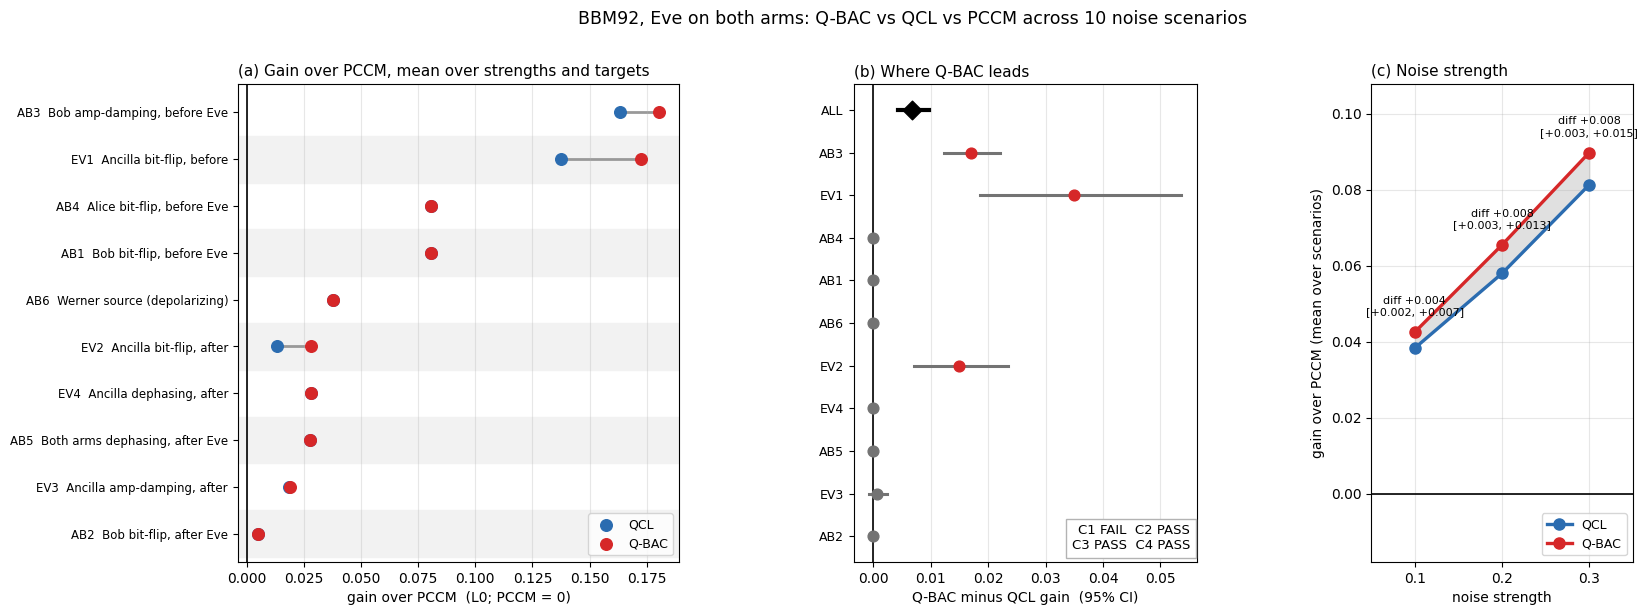


Saved: cell4_main_table.csv/.tex, cell4_main_figure.png (+ raw: cell4_restarts.csv, cell4_reference.csv, cell4_gains_per_cell.csv)


In [ ]:
# =====================================================================================================
# CELL 4 / 4  -  HEADLINE COMPARISON: is Q-BAC the biggest gainer over PCCM, and better than QCL?   (BBM92, Eve on both arms, free training)
#
# Design   : 10 noise scenarios (6 Alice-Bob + 4 Eve side) x 3 noise strengths x 5 target fidelities x 3 independent seeds x R paired restarts, QCL vs Q-BAC (both 36 parameters).
#            Gain = L0(PCCM) - L0(model) on the original loss L0 = 10 (F_AB - f)^2 - F_AE, counted when > GAIN_TOL.  Seed = an independent campaign of R restarts (best-of-R is what a user would run).
# Pre-registered decision rule (fixed BEFORE the run, on cell = (scenario, strength, target), d = gain(Q-BAC) - gain(QCL), seed-averaged):
#            C1  Q-BAC is not worse than QCL by more than GAIN_TOL in more than 2% of cells
#            C2  among cells where they differ by more than GAIN_TOL, Q-BAC is better in at least 75%
#            C3  the 95% bootstrap CI of the mean difference d lies above 0
#            C4  Q-BAC reaches the best solution more often than QCL (hit-rate difference, 95% CI above 0)
#            All four true  ->  "Q-BAC is the strongest and most reliable gainer in this setting".  Anything less is reported as it is.
# Support checks (flags below): PCCM+V (PCCM angles + trained readout) separates readout gain from circuit gain; GENL (any 2-qubit block per arm, 42 params, warm-started from the best
#            QCL / Q-BAC attack) shows how close QCL / Q-BAC are to the best arm-local attack.
# Output   : ONE main table (cell4_main_table.csv/.tex) and ONE main figure (cell4_main_figure.png); raw results in cell4_*.csv.  Resumable per scenario.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH = 0.2                 # used only for the preflight; the study loops over STRENGTHS
INCLUDE_PCCMV, INCLUDE_GENL = True, True
GAIN_TOL, HIT_TOL, MARG_W, SEED = 1e-3, 1e-3, 1000.0, 0
CHECK_ALL_VARIANTS = False
if MODE == "DEV": STRENGTHS, TARGETS, SEEDS, R, GRID_N, MAXITER, SCEN_IDS = [0.2], [0.65, 0.85], 2, 4, 41, 400, ["AB1", "AB3", "EV2"]
else:             STRENGTHS, TARGETS, SEEDS, R, GRID_N, MAXITER, SCEN_IDS = [0.1, 0.2, 0.3], [0.55, 0.65, 0.75, 0.85, 0.95], 3, 16, 91, 500, None
RST_CSV, REF_CSV = "cell4_restarts.csv", "cell4_reference.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in [m for m in OPS if globals().get("CHECK_ALL_VARIANTS", True) or m in ("PCCM", "QCL", "QBAC")]:   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in [m for m in OPS if globals().get("CHECK_ALL_VARIANTS", True) or m in ("PCCM", "QCL", "QBAC")]: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# ----------------------------------------------------------------------------------------------- extra engines: PCCM+V and the arm-local ceiling GENL
from scipy import stats
from scipy.linalg import logm
P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]])]
PAU2_np = np.stack([np.kron(a, b) for a, b in itertools.product(P1, repeat=2)][1:]); PAU2 = jnp.asarray(PAU2_np, dtype=CD); jexpm = jax.scipy.linalg.expm
def make_extra(sim):
    Iv = [I2] * 4
    def pccmv(x, f, p, base):
        UA, UB = block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]); V = [vblock(x[2 + 3 * i:5 + 3 * i]) for i in range(4)]
        return score_core(sim(UA, UB, p), V, f, base, 0., 0.)
    def genl(x, f, p, base):
        UA = jexpm(-1j * jnp.tensordot(x[:15].astype(CD), PAU2, axes=1)); UB = jexpm(-1j * jnp.tensordot(x[15:30].astype(CD), PAU2, axes=1)); V = [vblock(x[30 + 3 * i:33 + 3 * i]) for i in range(4)]
        return score_core(sim(UA, UB, p), V, f, base, 0., 0.)
    return {"PCCMV": jax.jit(jax.value_and_grad(pccmv, has_aux=True)), "GENL": jax.jit(jax.value_and_grad(genl, has_aux=True))}
def warm_local(name, xb):
    n = NP_[name]; out = []
    for blk in (xb[:n], xb[n:2 * n]):
        Hm = 1j * logm(np.asarray(block_unitary(OPS[name], jnp.asarray(blk)))); Hm = (Hm + Hm.conj().T) / 2; out.append(np.real(np.einsum('kij,ji->k', PAU2_np, Hm)) / 4)
    return np.concatenate(out + [xb[2 * n:]])
def check_strength(sc, eng, p_):                                                    # independent NumPy simulator at this noise strength
    rng = np.random.default_rng(zlib.crc32(repr((sc[0], p_)).encode()) & 0x7fffffff); base = np.asarray(eng["base"](p_)); worst = 0.
    for nm in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 36); (l, aux), _ = eng[nm](jnp.asarray(x), 0.7, p_, jnp.asarray(base), 0., 0., 1., 1.); l2, a2 = np_aux(sc, nm, x, p_, 0.7, base); worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - a2).max())
    assert worst < 1e-9, f"independent-simulator check failed for {sc[0]} at strength {p_}: {worst:.1e}"

# ----------------------------------------------------------------------------------------------- main loop
preflight()
done = set(pd.read_csv(RST_CSV).scen.unique()) if os.path.exists(RST_CSV) else set()
nt = len(SCEN) * len(STRENGTHS) * len(TARGETS) * SEEDS * R * 2
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(STRENGTHS)} strengths x {len(TARGETS)} targets x {SEEDS} seeds x {R} restarts x 2 models = {nt} trainings (~{nt*0.35/60:.0f} min), plus PCCM{' / PCCM+V' if INCLUDE_PCCMV else ''}{' / GENL' if INCLUDE_GENL else ''} references", flush=True)
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
for sc in SCEN:
    sid, group, label, pre, post, src = sc
    if sid in done: print(f"  {sid} already done, skipped"); continue
    eng = make_engines(make_sim(pre, post, src)); ext = make_extra(make_sim(pre, post, src)) if (INCLUDE_PCCMV or INCLUDE_GENL) else {}; rst, ref = [], []
    for p_ in STRENGTHS:
        check_strength(sc, eng, p_); base = eng["base"](p_)
        for f in TARGETS:
            args = (f, p_, base, 0., 0., 1., 1.); xp, lp, ap = fit_pccm(eng, f, base, 0., 0., 1., 1., G, p=p_); P0 = L0_of(ap, f)
            ref.append(dict(scen=sid, group=group, label=label, strength=p_, target=f, kind="PCCM", L0=P0, loss_pen=lp))
            best = {}
            for sd in range(SEEDS):
                starts = rng_for("c4", sid, p_, f, sd).uniform(-np.pi, np.pi, (R, 36))                       # paired: the same start vectors for QCL and Q-BAC
                for m in ("QCL", "QBAC"):
                    for r_ in range(R):
                        o = run_min(eng[m], starts[r_], args, MAXITER); (l, aux), _ = eng[m](jnp.asarray(o.x), *args); aux = np.asarray(aux)
                        rst.append(dict(scen=sid, strength=p_, target=f, seed=sd, model=m, restart=r_, loss_pen=float(l), L0=L0_of(aux, f), bias=aux[4]))
                        if m not in best or float(l) < best[m][0]: best[m] = (float(l), o.x)
            if INCLUDE_PCCMV:
                rr = rng_for("pccmv", sid, p_, f); bv = None
                for k_ in range(6):
                    x0 = np.concatenate([xp, np.zeros(12) if k_ == 0 else rr.uniform(-np.pi, np.pi, 12)]); o = run_min(ext["PCCMV"], x0, (f, p_, base), 600)
                    if bv is None or o.fun < bv.fun: bv = o
                (l, aux), _ = ext["PCCMV"](jnp.asarray(bv.x), f, p_, base); ref.append(dict(scen=sid, group=group, label=label, strength=p_, target=f, kind="PCCMV", L0=L0_of(np.asarray(aux), f), loss_pen=float(l)))
            if INCLUDE_GENL:
                nb = min(best, key=lambda k: best[k][0]); x0 = warm_local(nb, best[nb][1]); rr = rng_for("genl", sid, p_, f); bg = None
                for k_ in range(4):
                    o = run_min(ext["GENL"], x0 + (0 if k_ == 0 else rr.normal(0, 0.05, x0.size)), (f, p_, base), 800)
                    if bg is None or o.fun < bg.fun: bg = o
                (l, aux), _ = ext["GENL"](jnp.asarray(bg.x), f, p_, base); ref.append(dict(scen=sid, group=group, label=label, strength=p_, target=f, kind="GENL", L0=L0_of(np.asarray(aux), f), loss_pen=float(l)))
    pd.DataFrame(ref).to_csv(REF_CSV, mode="a", header=not os.path.exists(REF_CSV), index=False); pd.DataFrame(rst).to_csv(RST_CSV, mode="a", header=not os.path.exists(RST_CSV), index=False)
    print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis: ONE table, ONE figure
ids = [s[0] for s in SCEN]; lab_of = {s[0]: s[2] for s in SCEN}; Rr = pd.read_csv(RST_CSV); Rr = Rr[Rr.scen.isin(ids)]; Rf = pd.read_csv(REF_CSV); Rf = Rf[Rf.scen.isin(ids)]
rngb = np.random.default_rng(1); K = ["scen", "strength", "target"]; TOL = GAIN_TOL; NAMES = {"QCL": "QCL", "QBAC": "Q-BAC"}
def boot(d, n=5000): d = np.asarray(d); return np.percentile([rngb.choice(d, len(d)).mean() for _ in range(n)], [2.5, 97.5])
P0 = Rf[Rf.kind == "PCCM"][K + ["L0"]].rename(columns={"L0": "PCCM_L0"})
B = Rr.loc[Rr.groupby(K + ["seed", "model"]).loss_pen.idxmin()].merge(P0, on=K); B["G"] = B.PCCM_L0 - B.L0                                   # best-of-R per seed
Gs = B.pivot_table(index=K, columns="model", values="G"); Gs["d"] = Gs.QBAC - Gs.QCL                                                       # seed-averaged gains per cell
B48 = Rr.loc[Rr.groupby(K + ["model"]).loss_pen.idxmin()].merge(P0, on=K); B48["G"] = B48.PCCM_L0 - B48.L0; G48 = B48.pivot_table(index=K, columns="model", values="G"); G48["d"] = G48.QBAC - G48.QCL
sd_ = B.pivot_table(index=K + ["seed"], columns="model", values="G").assign(d=lambda t: t.QBAC - t.QCL).groupby(K).d.std()
Rr["best"] = Rr.groupby(K).loss_pen.transform("min"); Rr["hit"] = Rr.loss_pen <= Rr.best + HIT_TOL; Hc = Rr.groupby(K + ["model"]).hit.mean().unstack("model"); Hc["d"] = Hc.QBAC - Hc.QCL
Gs.reset_index().to_csv("cell4_gains_per_cell.csv", index=False)
n = len(Gs); worse, better = int((Gs.d < -TOL).sum()), int((Gs.d > TOL).sum()); lo3, hi3 = boot(Gs.d.values); lo4, hi4 = boot(Hc.d.values)
c1, c2, c3, c4 = worse / n <= 0.02, (better / (better + worse) >= 0.75) if better + worse else False, lo3 > 0, lo4 > 0
ok_ = lambda b: "PASS" if b else "FAIL"
# ---- the table
rows = []
for sid in ids:
    g = Gs.loc[sid]; r = {"Scenario": f"{sid}  {lab_of[sid]}"}
    for m in ("QCL", "QBAC"):
        for p_ in STRENGTHS: r[f"{NAMES[m]} p={p_:g}"] = g.xs(p_, level="strength")[m].mean()
    d = g.d.values; lo, hi = boot(d, 3000); r["Q-BAC minus QCL"] = d.mean(); r["95% CI"] = f"[{lo:+.3f}, {hi:+.3f}]"
    r["verdict"] = "Q-BAC > QCL" if (lo > 0 and d.mean() > TOL) else ("QCL > Q-BAC" if (hi < 0 and d.mean() < -TOL) else "tie")
    r["hit QCL"], r["hit Q-BAC"] = Hc.loc[sid].QCL.mean(), Hc.loc[sid].QBAC.mean(); rows.append(r)
TB = pd.DataFrame(rows); foot = {"Scenario": "ALL (mean over scenarios)"}
for c in TB.columns[1:]:
    if pd.api.types.is_numeric_dtype(TB[c]): foot[c] = TB[c].mean()
foot["95% CI"] = f"[{lo3:+.3f}, {hi3:+.3f}]"; foot["verdict"] = f"{int((TB.verdict == 'Q-BAC > QCL').sum())} Q-BAC / {int((TB.verdict == 'tie').sum())} tie / {int((TB.verdict == 'QCL > Q-BAC').sum())} QCL"
TBp = pd.concat([TB, pd.DataFrame([foot])], ignore_index=True); TBp.to_csv("cell4_main_table.csv", index=False)
try: TBp.to_latex("cell4_main_table.tex", index=False, float_format="%.3f")
except Exception as e: print("  (LaTeX export skipped:", e, ")")
pd.set_option("display.width", 280); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:+.3f}".format)
print("\n" + "=" * 140); print(f"MAIN TABLE  Gain over PCCM on L0 (mean of {len(TARGETS)} targets x {SEEDS} seeds, best-of-{R} per seed).  Q-BAC minus QCL pooled over strengths; CI = bootstrap over (strength, target) cells; hit = share of restarts reaching the best loss")
Ts = TBp.copy()
for c in ("hit QCL", "hit Q-BAC"): Ts[c] = Ts[c].map("{:.2f}".format)
print(Ts.to_string(index=False))
print("\n" + "=" * 140); print(f"PRE-REGISTERED DECISION RULE  ({n} cells = {len(ids)} scenarios x {len(STRENGTHS)} strengths x {len(TARGETS)} targets; d = Q-BAC gain minus QCL gain, seed-averaged)")
print(f"  C1  Q-BAC worse than QCL by > {TOL} in {worse}/{n} cells = {worse/n:.1%}  (needs <= 2%)                                   {ok_(c1)}")
print(f"  C2  cells that differ by > {TOL}: Q-BAC better in {better}, worse in {worse}  -> {better/max(better+worse,1):.0%} Q-BAC (needs >= 75%)            {ok_(c2)}")
print(f"  C3  mean d = {Gs.d.mean():+.4f}, 95% bootstrap CI [{lo3:+.4f}, {hi3:+.4f}]  (needs lower bound > 0)                      {ok_(c3)}")
print(f"  C4  hit-rate difference Q-BAC - QCL = {Hc.d.mean():+.3f}, 95% CI [{lo4:+.3f}, {hi4:+.3f}]  (needs lower bound > 0)                  {ok_(c4)}")
print(f"  ==> {'ALL FOUR PASS: Q-BAC is the strongest and most reliable gainer in this setting.' if c1 and c2 and c3 and c4 else 'NOT all four pass: do not claim a general win; report the criteria that hold (see the table).'}")
print(f"  robustness: with all {SEEDS*R} restarts pooled (best-of-{SEEDS*R}) mean d = {G48.d.mean():+.4f} [{boot(G48.d.values)[0]:+.4f}, {boot(G48.d.values)[1]:+.4f}] ; Q-BAC worse in {(G48.d < -TOL).sum()}/{n}, better in {(G48.d > TOL).sum()}/{n} cells")
print(f"  seed spread of d (std over seeds, mean over cells) = {sd_.mean():.4f} ; gain over PCCM > {TOL}: QCL in {(Gs.QCL > TOL).sum()}/{n} cells, Q-BAC in {(Gs.QBAC > TOL).sum()}/{n}")
print("  by noise strength: " + " | ".join(f"p={p_:g}: QCL {Gs.xs(p_, level='strength').QCL.mean():+.3f}, Q-BAC {Gs.xs(p_, level='strength').QBAC.mean():+.3f}, diff {Gs.xs(p_, level='strength').d.mean():+.3f}" for p_ in STRENGTHS))
Gl = lambda kind: Rf[Rf.kind == kind][K + ["L0", "loss_pen"]].rename(columns={"L0": kind + "_L0", "loss_pen": kind + "_loss"})
if INCLUDE_PCCMV and (Rf.kind == "PCCMV").any():
    X = Gs.reset_index().merge(P0, on=K).merge(Gl("PCCMV"), on=K); ro = X.PCCM_L0 - X.PCCMV_L0
    print(f"  PCCM+V: readout alone gives mean {ro.mean():+.4f} (max {ro.max():+.4f}); gain of QCL / Q-BAC over PCCM+V: mean {(X.PCCMV_L0 - (X.PCCM_L0 - X.QCL)).mean():+.4f} / {(X.PCCMV_L0 - (X.PCCM_L0 - X.QBAC)).mean():+.4f}; Q-BAC beats PCCM+V by > {TOL} in {((X.PCCMV_L0 - (X.PCCM_L0 - X.QBAC)) > TOL).sum()}/{n} cells")
if INCLUDE_GENL and (Rf.kind == "GENL").any():
    pool = Rr.groupby(K).loss_pen.min().rename("best_loss").reset_index().merge(Gl("GENL"), on=K); gap = pool.best_loss - pool.GENL_loss
    print(f"  GENL (any 2-qubit block per arm): best QCL/Q-BAC loss minus GENL loss: mean {gap.mean():+.4f}, max {gap.max():+.4f}; GENL stronger than QCL/Q-BAC by > {TOL} in {(gap > TOL).sum()}/{n} cells (0 = both are at the arm-local ceiling)")
# ---- the figure
col = {"QCL": "#2b6cb0", "QBAC": "#d62728"}; S = Gs.groupby("scen")[["QCL", "QBAC"]].mean(); order = list(S.QBAC.sort_values().index)
fig = plt.figure(figsize=(18, 6.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 1.05, .8], wspace=.5); a1, a2, a3 = (fig.add_subplot(gs[i]) for i in range(3))
for i, sid in enumerate(order):
    if i % 2 == 0: a1.axhspan(i - .5, i + .5, color="0.95", zorder=0)
    a, b = S.loc[sid, "QCL"], S.loc[sid, "QBAC"]; a1.plot([a, b], [i, i], color="0.6", lw=2, zorder=1)
    a1.scatter([a], [i], s=70, color=col["QCL"], zorder=3, label="QCL" if i == 0 else None); a1.scatter([b], [i], s=70, color=col["QBAC"], zorder=4, label="Q-BAC" if i == 0 else None)
a1.axvline(0, color="k", lw=1.2); a1.set_yticks(range(len(order))); a1.set_yticklabels([f"{s}  {lab_of[s]}" for s in order], fontsize=8.5); a1.set_ylim(-.6, len(order) - .4); a1.grid(alpha=.3, axis="x")
a1.set_xlabel("gain over PCCM  (L0; PCCM = 0)"); a1.set_title(f"(a) Gain over PCCM, mean over strengths and targets", loc="left", fontsize=11); a1.legend(loc="lower right", fontsize=9)
y = np.arange(len(order) + 1)
for i, sid in enumerate(order):
    d = Gs.loc[sid].d.values; lo, hi = boot(d, 3000); a2.plot([lo, hi], [i, i], color="0.45", lw=2.2); a2.scatter([d.mean()], [i], s=60, color=col["QBAC"] if (lo > 0 and d.mean() > TOL) else "0.45", zorder=3)
a2.plot([lo3, hi3], [len(order), len(order)], color="k", lw=3); a2.scatter([Gs.d.mean()], [len(order)], marker="D", s=90, color="k", zorder=4)
a2.axvline(0, color="k", lw=1.2); a2.set_yticks(range(len(order) + 1)); a2.set_yticklabels(order + ["ALL"], fontsize=9); a2.set_ylim(-.6, len(order) + .6); a2.grid(alpha=.3, axis="x")
a2.set_xlabel("Q-BAC minus QCL gain  (95% CI)"); a2.set_title("(b) Where Q-BAC leads", loc="left", fontsize=11)
a2.text(.98, .02, f"C1 {ok_(c1)}  C2 {ok_(c2)}\nC3 {ok_(c3)}  C4 {ok_(c4)}", transform=a2.transAxes, ha="right", va="bottom", fontsize=9.5, bbox=dict(fc="white", ec="0.7"))
gm = Gs.groupby("strength")[["QCL", "QBAC"]].mean()
for m in ("QCL", "QBAC"): a3.plot(gm.index, gm[m], "o-", color=col[m], ms=8, lw=2.4, label=NAMES[m])
a3.fill_between(gm.index, gm.QCL, gm.QBAC, color="0.8", alpha=.6, zorder=0)
for p_ in STRENGTHS:
    dd = Gs.xs(p_, level="strength").d.values; l_, h_ = boot(dd, 3000); a3.annotate(f"diff {dd.mean():+.3f}\n[{l_:+.3f}, {h_:+.3f}]", (p_, gm.loc[p_].max()), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)
a3.axhline(0, color="k", lw=1.2); a3.set_xticks(STRENGTHS); a3.margins(x=.25, y=.2); a3.set_xlabel("noise strength"); a3.set_ylabel("gain over PCCM (mean over scenarios)"); a3.set_title("(c) Noise strength", loc="left", fontsize=11); a3.grid(alpha=.3); a3.legend(fontsize=9, loc="lower right")
fig.suptitle("BBM92, Eve on both arms: Q-BAC vs QCL vs PCCM across 10 noise scenarios", fontsize=12.5, y=1.0); plt.savefig("cell4_main_figure.png", dpi=170, bbox_inches="tight"); plt.show()
print("\nSaved: cell4_main_table.csv/.tex, cell4_main_figure.png (+ raw: cell4_restarts.csv, cell4_reference.csv, cell4_gains_per_cell.csv)")

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CRY block unitary (dev 2.2e-16)
  [OK] QCL_CRZ block unitary (dev 4.4e-16)
  [OK] QCL_CR01 block unitary (dev 4.4e-16)
  [OK] QCL_CR10 block unitary (dev 1.6e-16)
  [OK] QCL_CR block unitary (dev 4.4e-16)
  [OK] QBAC_noCRZ block unitary (dev 4.4e-16)
  [OK] QBAC_noCRY block unitary (dev 4.4e-16)
  [OK] QBAC_noCR01 block unitary (dev 2.5e-16)
  [OK] QBAC_noCR10 block unitary (dev 4.4e-16)
  [OK] QBAC_noCR block unitary (dev 2.2e-16)
  [OK] QBAC_x2 block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.5e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noi

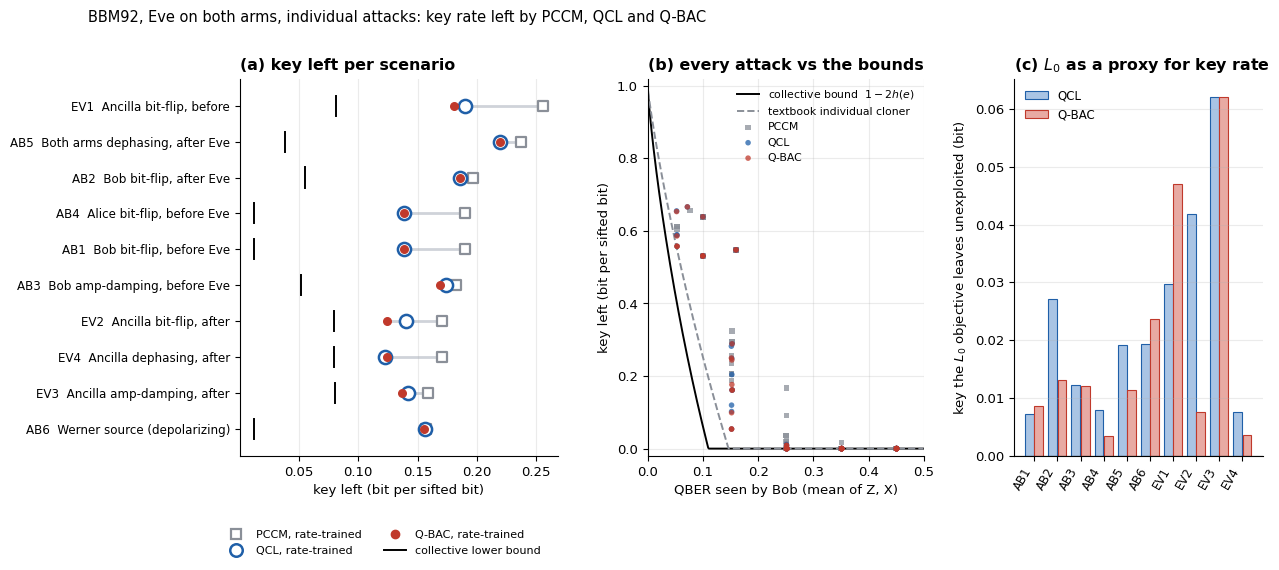


Saved: cell5_main_table.csv/.tex, cell5_main_figure.png/.pdf, cell5_FULL_rows.csv


In [ ]:
# =====================================================================================================
# CELL 5  -  KEY RATE: what do the learned attacks leave of the key?   (BBM92, Eve on both arms, INDIVIDUAL attacks, asymptotic)   STANDALONE: runs on its own in Colab
#
# Model     : same attacks as Cells 1-4 (Eve: one 2-qubit block per arm, one ancilla per arm, each ancilla measured separately in a trained basis, raw 4-valued outcome kept).
# Key rate  : r_basis = I(A:B) - min( I(A:E), I(B:E) )  from the EXACT joint distribution P(a,b,e) (Csiszar-Korner / Maurer, one-way communication, i.i.d. rounds); mean over Z and X; clipped at 0.
#             Eve is scored on her raw outcome, not only her Bayes guess, so she is not understated.  Collective (Holevo) value reported as a robustness column: Eve with quantum memory.
# Attacks   : PCCM_L0 = PCCM, original loss L0, fixed readout (context only: its QBER is whatever L0 picked)
#             PCCM_R = PCCM (2 angles, fixed readout) and PCCMV_R = PCCM + trained readout, both rate-trained at Bob's fidelity = target: the baseline at the SAME QBER
#             QCL_L0 / QBAC_L0 = trained on the ORIGINAL loss L0 (what Cells 1-4 optimised)
#             PCCMV_R / QCL_R / QBAC_R = trained DIRECTLY to minimise the key rate at Bob's fidelity = target (stiff penalty)
#             QCL_Rreal / QBAC_Rreal = rate-optimised at the SAME QBER the L0 attack happened to produce (warm-started) -> "proxy gap" = how much key the L0 objective leaves unexploited
# Pre-registered decision rule (fixed BEFORE the run; unit of analysis = cell = (scenario, target)):
#   V   validity : (i) no attack leaves less key than the collective lower bound 1-h(e_b)-h(e_b') ; (ii) Holevo chi >= measured I ; (iii) raw-outcome info >= Bayes-guess info ; (iv) rate-trained |Fab - target| <= 0.005 in >= 90% of cells
#   K1  Q-BAC leaves no more key than QCL (rate_QBAC <= rate_QCL + 0.001) in >= 98% of cells
#   K2  pooled mean of (rate_QCL_R - rate_QBAC_R): 95% bootstrap CI above 0
#   K3  both rate-trained attacks leave less key than the rate-trained PCCM at the same QBER: CI of (rate_PCCM_R - rate_m_R) above 0 for QCL and for Q-BAC
#   K4  proxy gap (rate of the L0-trained attack minus rate-optimised at the same QBER): CI above 0 for Q-BAC (L0 is not a perfect key-rate proxy)
# Output    : ONE main table (cell5_main_table.csv/.tex) and ONE main figure (cell5_main_figure.png/.pdf); raw rows in cell5_<MODE>_rows.csv.  Resumable per scenario.   MODE = "DEV" is a ~10 min smoke test.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W, GAIN_TOL, SEED = 0.2, 1000.0, 1e-3, 0
W_F = 1000.0                   # stiff penalty that pins Bob's average fidelity to the target in the rate-trained attacks
CHECK_ALL_VARIANTS = False
if MODE == "DEV": TARGETS, R, R_WARM, GRID_N, MAXITER, SCEN_IDS = [0.65, 0.85], 3, 2, 41, 400, ["AB1", "AB3", "EV2"]
else:             TARGETS, R, R_WARM, GRID_N, MAXITER, SCEN_IDS = [0.55, 0.65, 0.75, 0.85, 0.95], 12, 4, 91, 500, None
ROWS_CSV = f"cell5_{MODE}_rows.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# =====================================================================================================  KEY-RATE LAYER  (shared by Cells 5 and 6)
# Individual attack, Eve measures each ancilla separately in a trained basis (per BBM92 basis, after the basis announcement) and keeps the raw 4-valued outcome e = (e1,e2).
# Joint distribution per basis P(a,b,e) is computed EXACTLY from the density matrix.  Secret-key rate (Csiszar-Korner / Maurer, one-way public communication, i.i.d.):
#       r_basis = I(A:B) - min( I(A:E), I(B:E) )         (direct or reverse reconciliation, whichever is better for Alice and Bob)
# Eve's raw outcome is used (not only her Bayes guess), so Eve is NOT understated.  Reported rates are clipped at 0 (a key rate cannot be negative).
SDG = jnp.diag(jnp.array([1, -1j], dtype=CD)); HYA = H2 @ SDG; HYB = XG @ H2 @ SDG          # Y basis; Bob's labels are flipped because Phi+ is ANTI-correlated in Y
BAS = {"Z": (I2, I2, I2), "X": (H2, H2, H2), "Y": (HYA, HYB, I2)}                              # (Alice, Bob, ancilla pre-rotation)
def xlog2(p):
    q = jnp.clip(p, 0.0, 1.0); ok = q > 1e-14; return jnp.where(ok, q * jnp.log2(jnp.where(ok, q, 1.0)), 0.0)
def Hs(p): return -jnp.sum(xlog2(p))
def joint(rho, bname, V1, V2):
    HA, HB, Hn = BAS[bname]; Wm = kr(HA, Hn @ V1, HB, Hn @ V2); d = jnp.clip(jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T)), 0.0)
    return d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)                          # P[a, b, e1e2]
def info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = Hs(Pab.sum(1)), Hs(Pab.sum(0)), Hs(P.sum((0, 1)))
    iab = Ha + Hb_ - Hs(Pab.ravel()); iae = Ha + He - Hs(Pae.ravel()); ibe = Hb_ + He - Hs(Pbe.ravel())
    q = P[0, 1].sum() + P[1, 0].sum(); guess = jnp.max(Pae, axis=0).sum()
    return jnp.stack([q, iab, iae, ibe, iab - jnp.minimum(iae, ibe), guess, Pab.sum(1)[1], Pab.sum(0)[1]])    # q, I_AB, I_AE, I_BE, rate, Bayes-guess, P(a=1), P(b=1)
SN = ["q", "iab", "iae", "ibe", "rate", "guess", "ma", "mb"]
def h2(e): e = np.clip(np.asarray(e, float), 1e-15, 1 - 1e-15); return -e * np.log2(e) - (1 - e) * np.log2(1 - e)

def make_rate_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        if name in ("PCCMV", "PCCM0"): UA, UB = block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]); r = x[2:]
        else: n = NP_[name]; UA, UB = block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]); r = x[2 * n:]
        V = [I2] * (2 * nb) if name == "PCCM0" else [vblock(r[3 * i:3 * i + 3]) for i in range(2 * nb)]
        return UA, UB, V
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])      # (nb, 8)
    def loss(name):
        def fn(x, f, p, base, wf, wsym):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb))
            L = jnp.mean(S[:, 4]) + wf * (fab - f) ** 2 + MARG_W * bias + wsym * jnp.sum((q - jnp.mean(q)) ** 2)
            return L, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC", "PCCMV", "PCCM0"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def unpack(aux, nb): a = np.asarray(aux); return a[:nb * 8].reshape(nb, 8), float(a[-1])
def rate_of(S): return float(np.mean(np.maximum(S[:, 4], 0.0)))                                    # clipped key rate, mean over bases
def sp_bound(S):
    """Collective-attack lower bound valid for ANY attack with these per-basis error rates: r_b >= 1 - h(e_b) - h(e_b') for every other basis b'.  Our individual attack can never go below it."""
    q = S[:, 0]; nb = len(q); return float(np.mean([max(0.0, 1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i)) for i in range(nb)])) if nb > 1 else np.nan
def sp_each(S):
    q = S[:, 0]; nb = len(q); return np.array([1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i) for i in range(nb)])
def row_of(S, bias, bases, tag):
    d = dict(tag)
    for i, b in enumerate(bases):
        for k, nm in enumerate(SN): d[f"{nm}_{b}"] = float(S[i, k])
    d.update(bias=bias, fab=float(1 - np.mean(S[:, 0])), rate=rate_of(S), sp=sp_bound(S), rate_raw=float(np.mean(S[:, 4])), guess_info=float(np.mean([1 - h2(1 - S[i, 5]) for i in range(len(bases))])),
             info_ae=float(np.mean(S[:, 2])), info_ab=float(np.mean(S[:, 1])))
    return d

# ----------------------------------------------------------------------------------------------- independent NumPy cross-check of the information layer + quantum (Holevo) evaluation
def np_rho_tensor(scen, UA, UB, p):
    _, _, _, pre, post, src = scen
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1 / np.sqrt(2); rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())          # axes (A,B,E1,E2 | primes)
    if src:
        mix = np.zeros((2,) * 8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1 - p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    return rho
def np_split(name, x, nb):
    if name in ("PCCMV", "PCCM0"): UA, UB, r = np_block(OPS["PCCM"], x[0:1]), np_block(OPS["PCCM"], x[1:2]), x[2:]
    else: n = NP_[name]; UA, UB, r = np_block(OPS[name], x[:n]), np_block(OPS[name], x[n:2 * n]), x[2 * n:]
    V = [np.eye(2, dtype=complex)] * (2 * nb) if name == "PCCM0" else [np_gate("RZ", r[3 * i + 2]) @ np_gate("RY", r[3 * i + 1]) @ np_gate("RX", r[3 * i]) for i in range(2 * nb)]
    return UA, UB, V
_Hn = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); _Sd = np.diag([1, -1j]); _Xn = np.array([[0, 1], [1, 0]], complex)
NBAS = {"Z": (np.eye(2, dtype=complex),) * 3, "X": (_Hn,) * 3, "Y": (_Hn @ _Sd, _Xn @ _Hn @ _Sd, np.eye(2, dtype=complex))}
def np_ent(p): p = np.asarray(p, float).ravel(); p = p[p > 1e-14]; return float(-(p * np.log2(p)).sum())
def np_info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = np_ent(Pab.sum(1)), np_ent(Pab.sum(0)), np_ent(P.sum((0, 1)))
    iab, iae, ibe = Ha + Hb_ - np_ent(Pab), Ha + He - np_ent(Pae), Hb_ + He - np_ent(Pbe)
    return np.array([P[0, 1].sum() + P[1, 0].sum(), iab, iae, ibe, iab - min(iae, ibe), Pae.max(axis=0).sum(), Pab.sum(1)[1], Pab.sum(0)[1]])
def np_stats(scen, name, x, p, bases):
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for i, b in enumerate(bases):
        HA, HB, Hn = NBAS[b]; rr = rho
        for q, M in enumerate((HA, HB, Hn @ V[2 * i], Hn @ V[2 * i + 1])): rr = ap1(rr, M, q)
        out.append(np_info(np.real(np.einsum('abcdabcd->abcd', rr)).reshape(2, 2, 4)))
    return np.array(out)
def vn_ent(r): w = np.linalg.eigvalsh((r + r.conj().T) / 2); return np_ent(w)
def np_holevo(scen, name, x, p, bases):
    """Quantum (collective-attack) bound: Eve keeps both ancillas in quantum memory.  chi(A:E), chi(B:E) from the exact reduced states; returns per basis (chi_AE, chi_BE)."""
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for b in bases:
        HA, HB, _ = NBAS[b]; res = []
        for qi, Hq in ((0, HA), (1, HB)):
            rr = ap1(rho, Hq, qi); states = []
            for a in (0, 1):
                sl = rr[a, :, :, :, a, :, :, :] if qi == 0 else rr[:, a, :, :, :, a, :, :]; states.append(np.einsum('bcdbfg->cdfg', sl).reshape(4, 4))
            tot = states[0] + states[1]; chi = vn_ent(tot) - sum(np.real(np.trace(s)) * vn_ent(s / max(np.real(np.trace(s)), 1e-300)) for s in states if np.real(np.trace(s)) > 1e-14); res.append(chi)
        out.append(res)
    return np.array(out)
def np_rhoAB(scen, name, x, p, nb=2):
    UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); return np.einsum('abcdefcd->abef', rho).reshape(4, 4)
PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1]).astype(complex)}
def corr_matrix(rAB): return np.array([[np.real(np.trace(rAB @ np.kron(PAULI[i], PAULI[j]))) for j in "XYZ"] for i in "XYZ"])
def chsh_max(T): u = np.sort(np.linalg.eigvalsh(T.T @ T))[::-1]; return float(2 * np.sqrt(u[0] + u[1]))

def preflight56():
    print("=" * 100); print("PREFLIGHT (key-rate layer)"); rng = np.random.default_rng(321); ok = True
    # (a) Y basis alignment: with no attack Alice and Bob agree in Z, X and Y
    rho = make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); e = max(float(info(joint(rho, b, I2, I2))[0]) for b in "ZXY")
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: QBER in Z, X, Y is 0 (max {e:.1e})"); ok &= e < 1e-12
    # (b) JAX information layer == independent NumPy (statistics, three bases, all models, several scenarios)
    worst = 0.
    for sc in SCEN[:3]:
        sim = make_sim(sc[3], sc[4], sc[5]); eng = make_rate_engines(sim, ("Z", "X", "Y"))
        for nm in ("QCL", "QBAC", "PCCMV"):
            n = NP_["PCCM" if nm == "PCCMV" else nm]; x = rng.uniform(-3, 3, 2 * n + 18)
            worst = max(worst, np.abs(np.asarray(eng["st_" + nm](jnp.asarray(x), STRENGTH)) - np_stats(sc, nm, x, STRENGTH, ("Z", "X", "Y"))).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX I(A:B), I(A:E), I(B:E), QBER, rate, marginals == independent NumPy, bases Z/X/Y (max dev {worst:.1e})"); ok &= worst < 1e-9
    # (c) Holevo bound >= classical information of the actual measurement (two independent computations)
    worst = 0.
    for sc in SCEN[:3]:
        for nm in ("QCL", "QBAC"):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); S = np_stats(sc, nm, x, STRENGTH, ("Z", "X")); Hv = np_holevo(sc, nm, x, STRENGTH, ("Z", "X"))
            worst = min(worst, float((Hv[:, 0] - S[:, 2]).min()), float((Hv[:, 1] - S[:, 3]).min()))
    print(f"  [{'OK' if worst > -1e-9 else 'FAIL'}] Holevo chi(A:E), chi(B:E) >= measured I(A:E), I(B:E)  (min slack {worst:.1e})"); ok &= worst > -1e-9
    # (d) Correlation-matrix QBER == joint-distribution QBER (Phi+ : XX=+1, YY=-1, ZZ=+1)
    sc = SCEN[0]; x = rng.uniform(-3, 3, 42); T = corr_matrix(np_rhoAB(sc, "QCL", x, STRENGTH, 3)); S = np_stats(sc, "QCL", x, STRENGTH, ("Z", "X", "Y"))
    e = max(abs((1 - T[2, 2]) / 2 - S[0, 0]), abs((1 - T[0, 0]) / 2 - S[1, 0]), abs((1 + T[1, 1]) / 2 - S[2, 0])); print(f"  [{'OK' if e < 1e-9 else 'FAIL'}] QBER from correlators == QBER from outcome statistics (dev {e:.1e})"); ok &= e < 1e-9
    # (e) gradients of the rate loss vs finite differences
    sc = SCEN[0]; eng = make_rate_engines(make_sim(sc[3], sc[4], sc[5]), ("Z", "X", "Y")); base = eng["base"](STRENGTH); err = 0.
    for nm in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[nm] + 18); args = (0.7, STRENGTH, base, 1000., 5.); (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; fd = (float(eng["ev_" + nm](jnp.asarray(x + d), *args)[0]) - float(eng["ev_" + nm](jnp.asarray(x - d), *args)[0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] rate-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (f) no-attack / noiseless rate is 1 (full key), and fully correlated Eve gives rate <= 0
    print(f"  [OK] information layer sanity: no attack -> I(A:B)={float(info(joint(rho, 'Z', I2, I2))[1]):.3f} bit, I(A:E)={float(info(joint(rho, 'Z', I2, I2))[2]):.3f}")
    assert ok, "PREFLIGHT (key-rate layer) FAILED - do not trust any result below"; print("  PREFLIGHT (key-rate layer) PASSED\n")

# ----------------------------------------------------------------------------------------------- main loop
preflight(); preflight56()
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
BS = ("Z", "X"); nt = len(SCEN) * len(TARGETS) * (2 * R + 2 * R + 6 + 4 + 2 * R_WARM)
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(TARGETS)} targets x (2 models x {R} L0 + 2 x {R} rate + 6 PCCMV + 4 PCCM + 2 x {R_WARM} proxy) = {nt} trainings (~{nt*0.6/60:.0f} min), strength {STRENGTH}", flush=True)
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
def starts36(*key, n=R): return rng_for(*key).uniform(-np.pi, np.pi, (n, 36))
def best_of(vg, x0s, args):
    best = None
    for x0 in x0s:
        o = run_min(vg, x0, args, MAXITER)
        if best is None or o.fun < best.fun: best = o
    return best
for sc in SCEN:
    sid, group, label, pre, post, src = sc
    if sid in done: print(f"  {sid} already done, skipped"); continue
    sim = make_sim(pre, post, src); eng = make_engines(sim); re = make_rate_engines(sim, BS); base_o = eng["base"](STRENGTH); base_n = re["base"](STRENGTH); rows = []
    def add(name, x, kind, model, objective, f, ftarget):
        S = np.asarray(re["st_" + name](jnp.asarray(x), STRENGTH)); bias = float(((S[:, 6:7] - np.asarray(base_n)[0::2][:, None]) ** 2).sum() + ((S[:, 7:8] - np.asarray(base_n)[1::2][:, None]) ** 2).sum())
        d = row_of(S, bias, BS, dict(scen=sid, label=label, target=f, kind=kind, model=model, objective=objective, fab_target=ftarget)); Hv = np_holevo(sc, name, np.asarray(x), STRENGTH, BS)
        for i, b in enumerate(BS): d[f"chiAE_{b}"], d[f"chiBE_{b}"] = Hv[i]
        d["rate_coll"] = float(np.mean([max(0.0, S[i, 1] - min(Hv[i, 0], Hv[i, 1])) for i in range(2)])); rows.append(d); return d
    for f in TARGETS:
        xp, lp, ap = fit_pccm(eng, f, base_o, 0., 0., 1., 1., G); add("PCCM0", xp, "PCCM_L0", "PCCM", "L0", f, f)
        xL, dL = {}, {}
        st = starts36("c5a", sid, f)
        for m in ("QCL", "QBAC"):                                                                              # (2) L0-trained attacks (as in Cells 1-4), paired starts
            o = best_of(eng[m], st, (f, STRENGTH, base_o, 0., 0., 1., 1.)); xL[m] = o.x; dL[m] = add(m, o.x, m + "_L0", m, "L0", f, f)
        st = starts36("c5b", sid, f, n=R - 1)
        for m in ("QCL", "QBAC"):                                                                              # (3) rate-trained at the nominal target, one warm start from the L0 solution
            o = best_of(re[m], [xL[m]] + list(st), (f, STRENGTH, base_n, W_F, 0.)); add(m, o.x, m + "_R", m, "rate", f, f)
        rr = rng_for("c5v", sid, f); x0s = [np.concatenate([xp, np.zeros(12)])] + [np.concatenate([rr.uniform(0, np.pi, 2), rr.uniform(-np.pi, np.pi, 12)]) for _ in range(5)]
        o = best_of(re["PCCMV"], x0s, (f, STRENGTH, base_n, W_F, 0.)); add("PCCMV", o.x, "PCCMV_R", "PCCM", "rate", f, f)
        r0 = rng_for("c5q", sid, f); o = best_of(re["PCCM0"], [xp] + [r0.uniform(0, np.pi, 2) for _ in range(3)], (f, STRENGTH, base_n, W_F, 0.)); add("PCCM0", o.x, "PCCM_R", "PCCM", "rate", f, f)     # the PCCM at the SAME QBER (fixed readout, 2 angles)
        for m in ("QCL", "QBAC"):                                                                              # (4) proxy gap: rate-optimise at the QBER the L0 attack produced
            fr = dL[m]["fab"]; st = starts36("c5p", sid, f, m, n=R_WARM - 1)
            o = best_of(re[m], [xL[m]] + list(st), (fr, STRENGTH, base_n, W_F, 0.)); add(m, o.x, m + "_Rreal", m, "rate@L0-QBER", f, fr)
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False); print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis: validity checks, ONE table, ONE figure
ids = [s[0] for s in SCEN]; lab_of = {s[0]: s[2] for s in SCEN}; D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin(ids)]
rngb = np.random.default_rng(1); K = ["scen", "target"]
def boot(d, n=5000): d = np.asarray(d, float); return np.percentile(rngb.choice(d, (n, len(d))).mean(1), [2.5, 97.5])
W = D.pivot_table(index=K, columns="kind", values="rate"); Wc = D.pivot_table(index=K, columns="kind", values="rate_coll"); Wq = D.pivot_table(index=K, columns="kind", values="fab")
# ---- V : validity invariants
viol_sp = viol_chi = viol_guess = 0; nrows = len(D); worst_sp = 0.
for _, r in D.iterrows():
    qz, qx = r.q_Z, r.q_X; spZ, spX = 1 - h2(qz) - h2(qx), 1 - h2(qx) - h2(qz)
    worst_sp = min(worst_sp, r.rate_Z - spZ, r.rate_X - spX); viol_sp += (r.rate_Z < spZ - 1e-6) or (r.rate_X < spX - 1e-6)
    viol_chi += any(r[f"chiAE_{b}"] < r[f"iae_{b}"] - 1e-9 or r[f"chiBE_{b}"] < r[f"ibe_{b}"] - 1e-9 for b in "ZX")
    viol_guess += any(r[f"iae_{b}"] < 1 - h2(1 - r[f"guess_{b}"]) - 1e-9 for b in "ZX")
Rr_ = D[D.objective.isin(["rate", "rate@L0-QBER"])]; met = float((np.abs(Rr_.fab - Rr_.fab_target) <= 0.005).mean())
V = (viol_sp == 0) and (viol_chi == 0) and (viol_guess == 0) and met >= 0.90
print("\n" + "=" * 140); print("VALIDITY (rule V)")
print(f"  (i)   rows below the collective lower bound 1-h(e_b)-h(e_b'): {viol_sp}/{nrows}   (closest approach {worst_sp:+.2e} bit)")
print(f"  (ii)  rows with Holevo chi < measured information: {viol_chi}/{nrows}   (iii) raw-outcome info < Bayes-guess info: {viol_guess}/{nrows}")
print(f"  (iv)  rate-trained attacks with |Fab - target| <= 0.005: {100*met:.0f}% of {len(Rr_)} attacks      ==> V {'PASS' if V else 'FAIL'}")
# ---- table
def cellstat(a, b): d = (W[a] - W[b]).dropna().values; return d.mean(), *boot(d)
rows = []
for sid in ids:
    ix = W.index.get_level_values(0) == sid; w = W[ix]; wc = Wc[ix]; spv = D[(D.scen == sid) & (D.kind == "QBAC_R")].sp.mean()
    gap = {m: (w[m + "_L0"] - w[m + "_Rreal"]).mean() for m in ("QCL", "QBAC")}
    rows.append({"Scenario": f"{sid}  {lab_of[sid]}", "PCCM (rate)": w["PCCM_R"].mean(), "PCCM+V (rate)": w["PCCMV_R"].mean(), "QCL (rate)": w["QCL_R"].mean(), "Q-BAC (rate)": w["QBAC_R"].mean(), "QCL - Q-BAC": (w["QCL_R"] - w["QBAC_R"]).mean(),
                 "Q-BAC collective": wc["QBAC_R"].mean(), "lower bound": spv, "L0 proxy gap QCL": gap["QCL"], "L0 proxy gap Q-BAC": gap["QBAC"]})
d12 = (W["QCL_R"] - W["QBAC_R"]).values; lo2, hi2 = boot(d12); g = {m: (W[m + "_L0"] - W[m + "_Rreal"]).values for m in ("QCL", "QBAC")}
rows.append({"Scenario": "ALL (mean over cells)", "PCCM (rate)": W["PCCM_R"].mean(), "PCCM+V (rate)": W["PCCMV_R"].mean(), "QCL (rate)": W["QCL_R"].mean(), "Q-BAC (rate)": W["QBAC_R"].mean(), "QCL - Q-BAC": d12.mean(),
             "Q-BAC collective": Wc["QBAC_R"].mean(), "lower bound": D[D.kind == "QBAC_R"].sp.mean(), "L0 proxy gap QCL": g["QCL"].mean(), "L0 proxy gap Q-BAC": g["QBAC"].mean()})
T = pd.DataFrame(rows); T.to_csv("cell5_main_table.csv", index=False)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("\n" + "=" * 140); print("MAIN TABLE  Key rate left by each attack (bit per sifted bit, mean over Z and X, mean over targets); lower = stronger attack.  QCL - Q-BAC > 0: Q-BAC leaves less key.  proxy gap: key the L0 objective leaves unexploited"); print(T.to_string(index=False))
tex = ["\\begin{tabular}{lrrrrrrr}", "\\toprule", "Scenario & PCCM & PCCM+V & QCL & Q-BAC & QCL$-$Q-BAC & Q-BAC (collective) & lower bound \\\\", "\\midrule"] + \
      [" & ".join([r["Scenario"].replace("_", "\\_")] + [f"{r[c]:.3f}" for c in ["PCCM (rate)", "PCCM+V (rate)", "QCL (rate)", "Q-BAC (rate)", "QCL - Q-BAC", "Q-BAC collective", "lower bound"]]) + " \\\\" for _, r in T.iterrows()] + ["\\bottomrule", "\\end{tabular}"]
open("cell5_main_table.tex", "w").write("\n".join(tex))
# ---- pre-registered rules
n = len(W); k1 = float((W["QBAC_R"] > W["QCL_R"] + 1e-3).mean()); K1 = k1 <= 0.02; K2 = lo2 > 0
p3 = {m: (W["PCCM_R"] - W[m + "_R"]).values for m in ("QCL", "QBAC")}; c3 = {m: boot(p3[m]) for m in p3}; K3 = all(c3[m][0] > 0 for m in c3); lo4, hi4 = boot(g["QBAC"]); K4 = lo4 > 0
ok_ = lambda b: "PASS" if b else "FAIL"
print("\n" + "=" * 140); print(f"PRE-REGISTERED DECISION RULE  ({n} cells = {len(ids)} scenarios x {len(TARGETS)} targets)")
print(f"  K1  Q-BAC leaves more key than QCL (by > 0.001) in {100*k1:.1f}% of cells (needs <= 2%)                                             {ok_(K1)}")
print(f"  K2  mean key left by QCL minus Q-BAC = {d12.mean():+.4f} bit, 95% CI [{lo2:+.4f}, {hi2:+.4f}]  (needs lower bound > 0)                       {ok_(K2)}")
print(f"  K3  key removed vs PCCM (same QBER): QCL {p3['QCL'].mean():+.4f} [{c3['QCL'][0]:+.4f}, {c3['QCL'][1]:+.4f}] | Q-BAC {p3['QBAC'].mean():+.4f} [{c3['QBAC'][0]:+.4f}, {c3['QBAC'][1]:+.4f}]          {ok_(K3)}")
print(f"  K4  L0 proxy gap (Q-BAC) = {g['QBAC'].mean():+.4f} bit [{lo4:+.4f}, {hi4:+.4f}]   (QCL {g['QCL'].mean():+.4f})                                                    {ok_(K4)}")
print(f"  collective (Holevo) robustness: key left by the rate-trained Q-BAC attack: individual {W['QBAC_R'].mean():.4f} -> collective {Wc['QBAC_R'].mean():.4f} bit (Eve with quantum memory is stronger by {W['QBAC_R'].mean()-Wc['QBAC_R'].mean():+.4f})")
print("  ==> " + ("all rules pass" if (V and K1 and K2 and K3 and K4) else "NOT all rules pass: report only the rules that hold (see above)"))
# ---- the figure
import matplotlib as mpl
mpl.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
BLUE, RED, GREY = "#1f5fa8", "#c0392b", "#8a8f98"
fig = plt.figure(figsize=(13.2, 4.9)); gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1.0, .9], wspace=.32); a, b, c = (fig.add_subplot(gs[i]) for i in range(3))
Tt = T.iloc[:-1].sort_values("PCCM (rate)", ascending=False).reset_index(drop=True); yy = np.arange(len(Tt))[::-1]
for y, (_, r) in zip(yy, Tt.iterrows()):
    a.plot([r["Q-BAC (rate)"], r["PCCM (rate)"]], [y, y], color="#cfd3d9", lw=2, zorder=1); a.scatter(r["PCCM (rate)"], y, s=60, marker="s", facecolor="white", edgecolor=GREY, lw=1.6, zorder=3)
    a.scatter(r["QCL (rate)"], y, s=90, facecolor="white", edgecolor=BLUE, lw=1.8, zorder=4); a.scatter(r["Q-BAC (rate)"], y, s=30, color=RED, zorder=5); a.plot([r["lower bound"]] * 2, [y - .28, y + .28], color="k", lw=1.4, zorder=2)
a.set_yticks(yy); a.set_yticklabels([s.split("  ")[0] + "  " + s.split("  ", 1)[1] for s in Tt.Scenario], fontsize=8.6); a.set_xlabel("key left (bit per sifted bit)"); a.grid(axis="x", alpha=.25, zorder=0); a.set_title("(a) key left per scenario", loc="left", fontweight="bold")
from matplotlib.lines import Line2D
a.legend(handles=[Line2D([], [], marker="s", mfc="white", mec=GREY, mew=1.6, ls="", ms=7, label="PCCM, rate-trained"), Line2D([], [], marker="o", mfc="white", mec=BLUE, mew=1.8, ls="", ms=9, label="QCL, rate-trained"), Line2D([], [], marker="o", color=RED, ls="", ms=6, label="Q-BAC, rate-trained"), Line2D([], [], color="k", lw=1.4, label="collective lower bound")], frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=2)
e = np.linspace(0.001, 0.499, 400); b.plot(e, np.maximum(0, 1 - 2 * h2(e)), color="k", lw=1.4, label="collective bound  $1-2h(e)$"); b.plot(e, np.maximum(0, h2(0.5 - np.sqrt(e * (1 - e))) - h2(e)), color=GREY, lw=1.4, ls="--", label="textbook individual cloner")
for kind, col, mk, lbl in (("PCCM_R", GREY, "s", "PCCM"), ("QCL_R", BLUE, "o", "QCL"), ("QBAC_R", RED, "o", "Q-BAC")):
    s_ = D[D.kind == kind]; b.scatter(1 - s_.fab, s_.rate, s=16, color=col, marker=mk, alpha=.75, edgecolor="none", label=lbl, zorder=3 if kind != "PCCM_R" else 2)
b.set_xlabel("QBER seen by Bob (mean of Z, X)"); b.set_ylabel("key left (bit per sifted bit)"); b.set_xlim(0, .5); b.set_ylim(-.02, 1.02); b.grid(alpha=.25); b.legend(frameon=False, fontsize=7.8, loc="upper right"); b.set_title("(b) every attack vs the bounds", loc="left", fontweight="bold")
Tg = T.iloc[:-1].reset_index(drop=True); xg = np.arange(len(Tg)); c.bar(xg - .2, Tg["L0 proxy gap QCL"], .38, color="#a9c4e4", edgecolor=BLUE, lw=.8, label="QCL"); c.bar(xg + .2, Tg["L0 proxy gap Q-BAC"], .38, color="#e8aaa3", edgecolor=RED, lw=.8, label="Q-BAC")
c.axhline(0, color="k", lw=.8); c.set_xticks(xg); c.set_xticklabels([s.split("  ")[0] for s in Tg.Scenario], rotation=60, ha="right", fontsize=8.5); c.set_ylabel("key the $L_0$ objective leaves unexploited (bit)"); c.legend(frameon=False, fontsize=8.5); c.grid(axis="y", alpha=.25); c.set_title("(c) $L_0$ as a proxy for key rate", loc="left", fontweight="bold")
fig.suptitle("BBM92, Eve on both arms, individual attacks: key rate left by PCCM, QCL and Q-BAC", x=.01, ha="left", fontsize=10.5, y=1.02)
plt.savefig("cell5_main_figure.png", dpi=300, bbox_inches="tight"); plt.savefig("cell5_main_figure.pdf", bbox_inches="tight"); plt.show()
print("\nSaved: cell5_main_table.csv/.tex, cell5_main_figure.png/.pdf, " + ROWS_CSV)

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CRY block unitary (dev 2.2e-16)
  [OK] QCL_CRZ block unitary (dev 4.4e-16)
  [OK] QCL_CR01 block unitary (dev 4.4e-16)
  [OK] QCL_CR10 block unitary (dev 1.6e-16)
  [OK] QCL_CR block unitary (dev 4.4e-16)
  [OK] QBAC_noCRZ block unitary (dev 4.4e-16)
  [OK] QBAC_noCRY block unitary (dev 4.4e-16)
  [OK] QBAC_noCR01 block unitary (dev 2.5e-16)
  [OK] QBAC_noCR10 block unitary (dev 4.4e-16)
  [OK] QBAC_noCR block unitary (dev 2.2e-16)
  [OK] QBAC_x2 block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.5e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noi

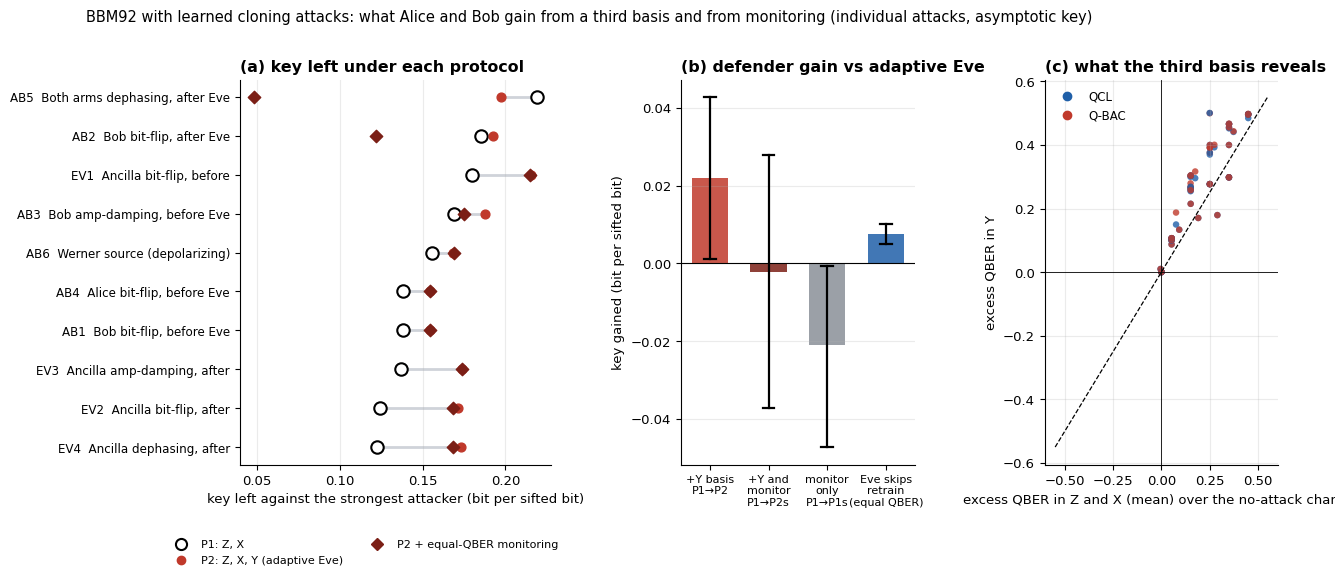


Saved: cell6_main_table.csv/.tex, cell6_main_figure.png/.pdf, cell6_FULL_rows.csv, cell6_FULL_sig.csv


In [ ]:
# =====================================================================================================
# CELL 6  -  WHAT CAN ALICE AND BOB DO?  Extending the basis set (six-state BBM92) and monitoring every basis, against learned cloning attacks.   STANDALONE: runs on its own in Colab
#
# Defender protocols (Eve is INDIVIDUAL, same attack family and key-rate layer as Cell 5; every attacker is retrained for the protocol she faces = adaptive Eve):
#   P1   Z, X measured (BBM92 as in Cells 1-5)                         Eve pins the MEAN QBER to the target
#   P1s  Z, X, plus Alice and Bob check that the QBER is the same in both bases (monitoring)   -> equal-QBER penalty
#   P2   Z, X, Y measured (six-state BBM92, key from all three bases)  Eve pins the mean QBER over the three bases
#   P2s  P2 plus equal-QBER monitoring across the three bases
#   naive Eve = the P1-adaptive attack run against P2; she may retune ONLY her Y readout (a generous gift).  adaptive-at-naive-QBER = Eve retrained for P2 at the QBER the naive attack produced.
# Attackers : QCL and Q-BAC (36 / 42 parameters = 24 block + readout 6 per basis), PCCM with fixed readout.  "Strongest attacker" = lower key rate of QCL and Q-BAC in each cell.
# Signature diagnostics (no training): for the naive attacks, the excess QBER over the calibrated no-attack channel in Z, X and Y, the sample size needed to see it at 3 sigma, and the Bell (CHSH) value.
# Pre-registered decision rule (fixed BEFORE the run; unit = cell = (scenario, target); key rates in bit per sifted bit; defender gain = rate_defended - rate_P1):
#   V   validity : no attack below the collective lower bound 1-h(e_b)-h(e_b') (every basis, every protocol) ; the Y basis is aligned ; pinned QBER met in >= 90% of attacks
#   D1  six-state helps against an ADAPTIVE Eve   : mean gain (strongest attacker, P2 - P1) with 95% bootstrap CI above 0
#   D2  Eve must adapt                              : at EQUAL QBER, mean (rate_naive - rate_adaptive@naive-QBER) with CI above 0   (naive Eve is never compared with P1: she misses her QBER target in P2)
#   D3  monitoring adds protection                : mean (P2s - P2) CI above 0 ; and (P1s - P1) CI above 0
#   D4  optimiser sanity                          : constrained Eve is never stronger than unconstrained (P_s rate >= P rate - 0.001) in >= 95% of cells
#   D5  Q-BAC remains the stronger attacker under P2 : mean (rate_QCL - rate_QBAC) in P2 with CI above 0
#   D6  P1-trained attacks are asymmetric           : excess QBER in Y minus mean excess in Z,X, CI above 0 (the attack neglects the basis it was not trained on)
# Output    : ONE main table (cell6_main_table.csv/.tex) and ONE main figure (cell6_main_figure.png/.pdf); raw rows in cell6_<MODE>_rows.csv, signatures in cell6_<MODE>_sig.csv.  Resumable.  MODE = "DEV" is a smoke test.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W, GAIN_TOL, SEED = 0.2, 1000.0, 1e-3, 0
W_F, W_SYM = 1000.0, 1000.0    # stiff penalties: mean QBER pinned to the target / QBER equal across the monitored bases
CHECK_ALL_VARIANTS = False
if MODE == "DEV": TARGETS, R, R_WARM, GRID_N, MAXITER, SCEN_IDS = [0.65, 0.85], 3, 2, 41, 400, ["AB1", "AB3", "EV2"]
else:             TARGETS, R, R_WARM, GRID_N, MAXITER, SCEN_IDS = [0.55, 0.65, 0.75, 0.85, 0.95], 12, 4, 91, 500, None
ROWS_CSV, SIG_CSV = f"cell6_{MODE}_rows.csv", f"cell6_{MODE}_sig.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# =====================================================================================================  KEY-RATE LAYER  (shared by Cells 5 and 6)
# Individual attack, Eve measures each ancilla separately in a trained basis (per BBM92 basis, after the basis announcement) and keeps the raw 4-valued outcome e = (e1,e2).
# Joint distribution per basis P(a,b,e) is computed EXACTLY from the density matrix.  Secret-key rate (Csiszar-Korner / Maurer, one-way public communication, i.i.d.):
#       r_basis = I(A:B) - min( I(A:E), I(B:E) )         (direct or reverse reconciliation, whichever is better for Alice and Bob)
# Eve's raw outcome is used (not only her Bayes guess), so Eve is NOT understated.  Reported rates are clipped at 0 (a key rate cannot be negative).
SDG = jnp.diag(jnp.array([1, -1j], dtype=CD)); HYA = H2 @ SDG; HYB = XG @ H2 @ SDG          # Y basis; Bob's labels are flipped because Phi+ is ANTI-correlated in Y
BAS = {"Z": (I2, I2, I2), "X": (H2, H2, H2), "Y": (HYA, HYB, I2)}                              # (Alice, Bob, ancilla pre-rotation)
def xlog2(p):
    q = jnp.clip(p, 0.0, 1.0); ok = q > 1e-14; return jnp.where(ok, q * jnp.log2(jnp.where(ok, q, 1.0)), 0.0)
def Hs(p): return -jnp.sum(xlog2(p))
def joint(rho, bname, V1, V2):
    HA, HB, Hn = BAS[bname]; Wm = kr(HA, Hn @ V1, HB, Hn @ V2); d = jnp.clip(jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T)), 0.0)
    return d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)                          # P[a, b, e1e2]
def info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = Hs(Pab.sum(1)), Hs(Pab.sum(0)), Hs(P.sum((0, 1)))
    iab = Ha + Hb_ - Hs(Pab.ravel()); iae = Ha + He - Hs(Pae.ravel()); ibe = Hb_ + He - Hs(Pbe.ravel())
    q = P[0, 1].sum() + P[1, 0].sum(); guess = jnp.max(Pae, axis=0).sum()
    return jnp.stack([q, iab, iae, ibe, iab - jnp.minimum(iae, ibe), guess, Pab.sum(1)[1], Pab.sum(0)[1]])    # q, I_AB, I_AE, I_BE, rate, Bayes-guess, P(a=1), P(b=1)
SN = ["q", "iab", "iae", "ibe", "rate", "guess", "ma", "mb"]
def h2(e): e = np.clip(np.asarray(e, float), 1e-15, 1 - 1e-15); return -e * np.log2(e) - (1 - e) * np.log2(1 - e)

def make_rate_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        if name in ("PCCMV", "PCCM0"): UA, UB = block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]); r = x[2:]
        else: n = NP_[name]; UA, UB = block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]); r = x[2 * n:]
        V = [I2] * (2 * nb) if name == "PCCM0" else [vblock(r[3 * i:3 * i + 3]) for i in range(2 * nb)]
        return UA, UB, V
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])      # (nb, 8)
    def loss(name):
        def fn(x, f, p, base, wf, wsym):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb))
            L = jnp.mean(S[:, 4]) + wf * (fab - f) ** 2 + MARG_W * bias + wsym * jnp.sum((q - jnp.mean(q)) ** 2)
            return L, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC", "PCCMV", "PCCM0"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def unpack(aux, nb): a = np.asarray(aux); return a[:nb * 8].reshape(nb, 8), float(a[-1])
def rate_of(S): return float(np.mean(np.maximum(S[:, 4], 0.0)))                                    # clipped key rate, mean over bases
def sp_bound(S):
    """Collective-attack lower bound valid for ANY attack with these per-basis error rates: r_b >= 1 - h(e_b) - h(e_b') for every other basis b'.  Our individual attack can never go below it."""
    q = S[:, 0]; nb = len(q); return float(np.mean([max(0.0, 1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i)) for i in range(nb)])) if nb > 1 else np.nan
def sp_each(S):
    q = S[:, 0]; nb = len(q); return np.array([1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i) for i in range(nb)])
def row_of(S, bias, bases, tag):
    d = dict(tag)
    for i, b in enumerate(bases):
        for k, nm in enumerate(SN): d[f"{nm}_{b}"] = float(S[i, k])
    d.update(bias=bias, fab=float(1 - np.mean(S[:, 0])), rate=rate_of(S), sp=sp_bound(S), rate_raw=float(np.mean(S[:, 4])), guess_info=float(np.mean([1 - h2(1 - S[i, 5]) for i in range(len(bases))])),
             info_ae=float(np.mean(S[:, 2])), info_ab=float(np.mean(S[:, 1])))
    return d

# ----------------------------------------------------------------------------------------------- independent NumPy cross-check of the information layer + quantum (Holevo) evaluation
def np_rho_tensor(scen, UA, UB, p):
    _, _, _, pre, post, src = scen
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1 / np.sqrt(2); rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())          # axes (A,B,E1,E2 | primes)
    if src:
        mix = np.zeros((2,) * 8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1 - p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    return rho
def np_split(name, x, nb):
    if name in ("PCCMV", "PCCM0"): UA, UB, r = np_block(OPS["PCCM"], x[0:1]), np_block(OPS["PCCM"], x[1:2]), x[2:]
    else: n = NP_[name]; UA, UB, r = np_block(OPS[name], x[:n]), np_block(OPS[name], x[n:2 * n]), x[2 * n:]
    V = [np.eye(2, dtype=complex)] * (2 * nb) if name == "PCCM0" else [np_gate("RZ", r[3 * i + 2]) @ np_gate("RY", r[3 * i + 1]) @ np_gate("RX", r[3 * i]) for i in range(2 * nb)]
    return UA, UB, V
_Hn = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); _Sd = np.diag([1, -1j]); _Xn = np.array([[0, 1], [1, 0]], complex)
NBAS = {"Z": (np.eye(2, dtype=complex),) * 3, "X": (_Hn,) * 3, "Y": (_Hn @ _Sd, _Xn @ _Hn @ _Sd, np.eye(2, dtype=complex))}
def np_ent(p): p = np.asarray(p, float).ravel(); p = p[p > 1e-14]; return float(-(p * np.log2(p)).sum())
def np_info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = np_ent(Pab.sum(1)), np_ent(Pab.sum(0)), np_ent(P.sum((0, 1)))
    iab, iae, ibe = Ha + Hb_ - np_ent(Pab), Ha + He - np_ent(Pae), Hb_ + He - np_ent(Pbe)
    return np.array([P[0, 1].sum() + P[1, 0].sum(), iab, iae, ibe, iab - min(iae, ibe), Pae.max(axis=0).sum(), Pab.sum(1)[1], Pab.sum(0)[1]])
def np_stats(scen, name, x, p, bases):
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for i, b in enumerate(bases):
        HA, HB, Hn = NBAS[b]; rr = rho
        for q, M in enumerate((HA, HB, Hn @ V[2 * i], Hn @ V[2 * i + 1])): rr = ap1(rr, M, q)
        out.append(np_info(np.real(np.einsum('abcdabcd->abcd', rr)).reshape(2, 2, 4)))
    return np.array(out)
def vn_ent(r): w = np.linalg.eigvalsh((r + r.conj().T) / 2); return np_ent(w)
def np_holevo(scen, name, x, p, bases):
    """Quantum (collective-attack) bound: Eve keeps both ancillas in quantum memory.  chi(A:E), chi(B:E) from the exact reduced states; returns per basis (chi_AE, chi_BE)."""
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for b in bases:
        HA, HB, _ = NBAS[b]; res = []
        for qi, Hq in ((0, HA), (1, HB)):
            rr = ap1(rho, Hq, qi); states = []
            for a in (0, 1):
                sl = rr[a, :, :, :, a, :, :, :] if qi == 0 else rr[:, a, :, :, :, a, :, :]; states.append(np.einsum('bcdbfg->cdfg', sl).reshape(4, 4))
            tot = states[0] + states[1]; chi = vn_ent(tot) - sum(np.real(np.trace(s)) * vn_ent(s / max(np.real(np.trace(s)), 1e-300)) for s in states if np.real(np.trace(s)) > 1e-14); res.append(chi)
        out.append(res)
    return np.array(out)
def np_rhoAB(scen, name, x, p, nb=2):
    UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); return np.einsum('abcdefcd->abef', rho).reshape(4, 4)
PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1]).astype(complex)}
def corr_matrix(rAB): return np.array([[np.real(np.trace(rAB @ np.kron(PAULI[i], PAULI[j]))) for j in "XYZ"] for i in "XYZ"])
def chsh_max(T): u = np.sort(np.linalg.eigvalsh(T.T @ T))[::-1]; return float(2 * np.sqrt(u[0] + u[1]))

def preflight56():
    print("=" * 100); print("PREFLIGHT (key-rate layer)"); rng = np.random.default_rng(321); ok = True
    # (a) Y basis alignment: with no attack Alice and Bob agree in Z, X and Y
    rho = make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); e = max(float(info(joint(rho, b, I2, I2))[0]) for b in "ZXY")
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: QBER in Z, X, Y is 0 (max {e:.1e})"); ok &= e < 1e-12
    # (b) JAX information layer == independent NumPy (statistics, three bases, all models, several scenarios)
    worst = 0.
    for sc in SCEN[:3]:
        sim = make_sim(sc[3], sc[4], sc[5]); eng = make_rate_engines(sim, ("Z", "X", "Y"))
        for nm in ("QCL", "QBAC", "PCCMV"):
            n = NP_["PCCM" if nm == "PCCMV" else nm]; x = rng.uniform(-3, 3, 2 * n + 18)
            worst = max(worst, np.abs(np.asarray(eng["st_" + nm](jnp.asarray(x), STRENGTH)) - np_stats(sc, nm, x, STRENGTH, ("Z", "X", "Y"))).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX I(A:B), I(A:E), I(B:E), QBER, rate, marginals == independent NumPy, bases Z/X/Y (max dev {worst:.1e})"); ok &= worst < 1e-9
    # (c) Holevo bound >= classical information of the actual measurement (two independent computations)
    worst = 0.
    for sc in SCEN[:3]:
        for nm in ("QCL", "QBAC"):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); S = np_stats(sc, nm, x, STRENGTH, ("Z", "X")); Hv = np_holevo(sc, nm, x, STRENGTH, ("Z", "X"))
            worst = min(worst, float((Hv[:, 0] - S[:, 2]).min()), float((Hv[:, 1] - S[:, 3]).min()))
    print(f"  [{'OK' if worst > -1e-9 else 'FAIL'}] Holevo chi(A:E), chi(B:E) >= measured I(A:E), I(B:E)  (min slack {worst:.1e})"); ok &= worst > -1e-9
    # (d) Correlation-matrix QBER == joint-distribution QBER (Phi+ : XX=+1, YY=-1, ZZ=+1)
    sc = SCEN[0]; x = rng.uniform(-3, 3, 42); T = corr_matrix(np_rhoAB(sc, "QCL", x, STRENGTH, 3)); S = np_stats(sc, "QCL", x, STRENGTH, ("Z", "X", "Y"))
    e = max(abs((1 - T[2, 2]) / 2 - S[0, 0]), abs((1 - T[0, 0]) / 2 - S[1, 0]), abs((1 + T[1, 1]) / 2 - S[2, 0])); print(f"  [{'OK' if e < 1e-9 else 'FAIL'}] QBER from correlators == QBER from outcome statistics (dev {e:.1e})"); ok &= e < 1e-9
    # (e) gradients of the rate loss vs finite differences
    sc = SCEN[0]; eng = make_rate_engines(make_sim(sc[3], sc[4], sc[5]), ("Z", "X", "Y")); base = eng["base"](STRENGTH); err = 0.
    for nm in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[nm] + 18); args = (0.7, STRENGTH, base, 1000., 5.); (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; fd = (float(eng["ev_" + nm](jnp.asarray(x + d), *args)[0]) - float(eng["ev_" + nm](jnp.asarray(x - d), *args)[0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] rate-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (f) no-attack / noiseless rate is 1 (full key), and fully correlated Eve gives rate <= 0
    print(f"  [OK] information layer sanity: no attack -> I(A:B)={float(info(joint(rho, 'Z', I2, I2))[1]):.3f} bit, I(A:E)={float(info(joint(rho, 'Z', I2, I2))[2]):.3f}")
    assert ok, "PREFLIGHT (key-rate layer) FAILED - do not trust any result below"; print("  PREFLIGHT (key-rate layer) PASSED\n")

# ----------------------------------------------------------------------------------------------- main loop
preflight(); preflight56()
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
PROTO = {"P1": (("Z", "X"), 0.), "P1s": (("Z", "X"), W_SYM), "P2": (("Z", "X", "Y"), 0.), "P2s": (("Z", "X", "Y"), W_SYM)}
nt = len(SCEN) * len(TARGETS) * (4 * 2 * R + 2 * 4 + 2 * 4 + 2 * R_WARM)
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(TARGETS)} targets x (4 protocols x 2 models x {R} restarts + PCCM + naive Y-readout + {R_WARM} warm) = {nt} trainings (~{nt*0.7/60:.0f} min), strength {STRENGTH}", flush=True)
G = jnp.linspace(0, jnp.pi, GRID_N); t0 = time.time()
def starts(*key, n, dim): return rng_for(*key).uniform(-np.pi, np.pi, (n, dim))
def best_of(vg, x0s, args):
    best = None
    for x0 in x0s:
        o = run_min(vg, x0, args, MAXITER)
        if best is None or o.fun < best.fun: best = o
    return best
def tune_y(vg, x1, args, rr):                                                                   # naive Eve may retune ONLY her Y readout (last 6 parameters)
    best = None
    for _ in range(4):
        def fun(y):
            (l, _), g = vg(jnp.asarray(np.concatenate([x1, y])), *args); return float(l), np.asarray(g, float)[-6:]
        o = minimize(fun, rr.uniform(-np.pi, np.pi, 6), jac=True, method='L-BFGS-B', options=dict(maxiter=300, ftol=1e-13, gtol=1e-9))
        if best is None or o.fun < best.fun: best = o
    return np.concatenate([x1, best.x])
def benign_q(sc, p):                                                                               # calibrated no-attack channel: QBER per basis
    rho = np_rho_tensor(sc, np.eye(4, dtype=complex), np.eye(4, dtype=complex), p); out = {}
    for b in "ZXY":
        HA, HB, Hn = NBAS[b]; rr = rho
        for q, M in enumerate((HA, HB, Hn, Hn)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr)).reshape(2, 2, 4); out[b] = float(P[0, 1].sum() + P[1, 0].sum())
    return out
for sc in SCEN:
    sid, group, label, pre, post, src = sc
    if sid in done: print(f"  {sid} already done, skipped"); continue
    sim = make_sim(pre, post, src); eng_o = make_engines(sim); base_o = eng_o["base"](STRENGTH); RE = {2: make_rate_engines(sim, ("Z", "X")), 3: make_rate_engines(sim, ("Z", "X", "Y"))}; rows, sigs = [], []; bq = benign_q(sc, STRENGTH)
    rho_b = np_rho_tensor(sc, np.eye(4, dtype=complex), np.eye(4, dtype=complex), STRENGTH); S_benign = chsh_max(corr_matrix(np.einsum('abcdefcd->abef', rho_b).reshape(4, 4)))
    for f in TARGETS:
        def add(re, name, x, protocol, model, f_t, bases, extra=None):
            S = np.asarray(re["st_" + name](jnp.asarray(x), STRENGTH)); base = np.asarray(re["base"](STRENGTH)); nb = len(bases)
            bias = float(sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb)))
            d = row_of(S, bias, bases, dict(scen=sid, label=label, target=f, protocol=protocol, model=model, fab_target=f_t, spread=float(np.ptp(S[:, 0])))); d.update(extra or {}); rows.append(d); return d
        sol = {}
        for pr, (bases, wsym) in PROTO.items():                                                          # adaptive Eve for each protocol
            re = RE[len(bases)]; nb = len(bases); base = re["base"](STRENGTH); dim = 24 + 6 * nb
            for m in ("QCL", "QBAC"):
                st = starts("c6", sid, f, pr, m, n=R, dim=dim)                                       # paired restarts (the same start vectors for QCL and Q-BAC within a protocol)
                x0s = list(st) if wsym == 0 else [sol[(pr[:-1], m)]] + list(st[:-1])                 # the monitored attacker is warm-started from the unmonitored one
                o = best_of(re[m], x0s, (f, STRENGTH, base, W_F, wsym)); sol[(pr, m)] = o.x; add(re, m, o.x, pr, m, f, bases)
            if wsym == 0:                                                                            # PCCM with its fixed readout (classical reference)
                r0 = rng_for("c6q", sid, f, pr); xp = fit_pccm(eng_o, f, base_o, 0., 0., 1., 1., G)[0] if pr == "P1" else sol[("P1", "PCCM0")]
                o = best_of(re["PCCM0"], [xp] + [r0.uniform(0, np.pi, 2) for _ in range(3)], (f, STRENGTH, base, W_F, 0.)); sol[(pr, "PCCM0")] = o.x; add(re, "PCCM0", o.x, pr, "PCCM", f, bases)
        re3 = RE[3]; base3 = re3["base"](STRENGTH)
        for m in ("QCL", "QBAC"):                                                                        # naive Eve: P1-adaptive attack against P2
            x2 = tune_y(re3[m], sol[("P1", m)], (f, STRENGTH, base3, 0., 0.), rng_for("c6y", sid, f, m)); dn = add(re3, m, x2, "P2-naive", m, f, ("Z", "X", "Y"))
            fr = dn["fab"]; st = starts("c6w", sid, f, m, n=R_WARM - 1, dim=42)
            o = best_of(re3[m], [x2] + list(st), (fr, STRENGTH, base3, W_F, 0.)); add(re3, m, o.x, "P2@naive-QBER", m, fr, ("Z", "X", "Y"))        # adaptive Eve at the naive attack's QBER
            T_ = corr_matrix(np_rhoAB(sc, m, x2, STRENGTH, 3)); S1 = chsh_max(T_); rec = dict(scen=sid, target=f, model=m, chsh=S1, chsh_benign=S_benign)
            for b in "ZXY": rec[f"q_{b}"] = dn[f"q_{b}"]; rec[f"qb_{b}"] = bq[b]; rec[f"dq_{b}"] = dn[f"q_{b}"] - bq[b]
            for b in "ZXY":
                e_, dl = bq[b], rec[f"dq_{b}"]; e_ = min(max(e_, 0.01), 0.5); rec[f"N3_{b}"] = 9 * e_ * (1 - e_) / dl ** 2 if abs(dl) > 1e-9 else np.inf
            sigs.append(rec)
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False); pd.DataFrame(sigs).to_csv(SIG_CSV, mode="a", header=not os.path.exists(SIG_CSV), index=False)
    print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis
ids = [s[0] for s in SCEN]; lab_of = {s[0]: s[2] for s in SCEN}; D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin(ids)]; SG = pd.read_csv(SIG_CSV); SG = SG[SG.scen.isin(ids)]
rngb = np.random.default_rng(1); K = ["scen", "target"]
def boot(d, n=5000): d = np.asarray(d, float); return np.percentile(rngb.choice(d, (n, len(d))).mean(1), [2.5, 97.5])
W = D.pivot_table(index=K, columns=["protocol", "model"], values="rate")
def best(pr): return W[pr][["QCL", "QBAC"]].min(axis=1)                                                  # strongest attacker (lowest key) per cell
# ---- V
viol = 0; worst = 0.; nb_checked = 0
for _, r in D.iterrows():
    bs = [b for b in "ZXY" if not np.isnan(r.get(f"q_{b}", np.nan))]
    for b in bs:
        others = [h2(r[f"q_{c}"]) for c in bs if c != b]; lb = 1 - h2(r[f"q_{b}"]) - min(others); nb_checked += 1; worst = min(worst, r[f"rate_{b}"] - lb); viol += r[f"rate_{b}"] < lb - 1e-6
pin = D[D.protocol.isin(list(PROTO) + ["P2@naive-QBER"]) & (D.model != "PCCM")]; met = float((np.abs(pin.fab - pin.fab_target) <= 0.005).mean())
sym = D[D.protocol.isin(["P1s", "P2s"]) & (D.model != "PCCM")]; met_sym = float((sym.spread <= 0.01).mean())
V = viol == 0 and met >= 0.90
print("\n" + "=" * 140); print("VALIDITY (rule V)")
print(f"  (i)   per-basis key rates below the collective lower bound: {viol}/{nb_checked}   (closest approach {worst:+.2e} bit)")
print(f"  (ii)  pinned-QBER attacks within 0.005 of the target: {100*met:.0f}% of {len(pin)} ;  monitored attacks with QBER spread across bases <= 0.01: {100*met_sym:.0f}% of {len(sym)}      ==> V {'PASS' if V else 'FAIL'}")
# ---- table: strongest attacker, mean over targets, per scenario
rows = []
def addrow(name, ix):
    w = W[ix]; naive = W["P2-naive"][["QCL", "QBAC"]].min(axis=1); adapt = W["P2@naive-QBER"][["QCL", "QBAC"]].min(axis=1);
    rows.append({"Scenario": name, "P1": best("P1")[ix].mean(), "P1s": best("P1s")[ix].mean(), "P2": best("P2")[ix].mean(), "P2s": best("P2s")[ix].mean(), "gain P2-P1": (best("P2") - best("P1"))[ix].mean(),
                 "naive - adaptive (same QBER)": (naive - adapt)[ix].mean(), "PCCM P1": w["P1"]["PCCM"].mean(), "PCCM P2": w["P2"]["PCCM"].mean()})
for sid in ids: addrow(f"{sid}  {lab_of[sid]}", W.index.get_level_values(0) == sid)
addrow("ALL (mean over cells)", np.ones(len(W), bool)); T = pd.DataFrame(rows); T.to_csv("cell6_main_table.csv", index=False)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("\n" + "=" * 140); print("MAIN TABLE  Key left (bit per sifted bit) against the STRONGEST attacker (QCL or Q-BAC) under each defender protocol; higher = better for Alice and Bob; gain = rate_defended - rate_P1"); print(T.to_string(index=False))
tex = ["\\begin{tabular}{lrrrrrr}", "\\toprule", "Scenario & P1 & P1s & P2 & P2s & gain P2$-$P1 & naive$-$adaptive \\\\", "\\midrule"] + [" & ".join([r["Scenario"]] + [f"{r[c]:.3f}" for c in ["P1", "P1s", "P2", "P2s", "gain P2-P1", "naive - adaptive (same QBER)"]]) + " \\\\" for _, r in T.iterrows()] + ["\\bottomrule", "\\end{tabular}"]
open("cell6_main_table.tex", "w").write("\n".join(tex))
# ---- rules
b1, b2, b1s, b2s = best("P1"), best("P2"), best("P1s"), best("P2s"); nv = W["P2-naive"][["QCL", "QBAC"]].min(axis=1); ad = W["P2@naive-QBER"][["QCL", "QBAC"]].min(axis=1)
g1 = (b2 - b1).values; g2 = (nv - ad).values; g3a = (b2s - b2).values; g3b = (b1s - b1).values; c1, c2, c3a, c3b = boot(g1), boot(g2), boot(g3a), boot(g3b)
mono = float(((b2s >= b2 - 1e-3) & (b1s >= b1 - 1e-3)).mean()); d5 = (W["P2"]["QCL"] - W["P2"]["QBAC"]).values; c5 = boot(d5)
D1, D2, D3, D4, D5 = c1[0] > 0, c2[0] > 0, (c3a[0] > 0 and c3b[0] > 0), mono >= 0.95, c5[0] > 0
ok_ = lambda b: "PASS" if b else "FAIL"; n = len(W)
print("\n" + "=" * 140); print(f"PRE-REGISTERED DECISION RULE  ({n} cells)")
print(f"  D1  six-state vs ADAPTIVE Eve : gain {g1.mean():+.4f} bit, 95% CI [{c1[0]:+.4f}, {c1[1]:+.4f}]                                              {ok_(D1)}")
print(f"  D2  Eve must adapt            : at equal QBER the naive Eve leaves {g2.mean():+.4f} bit more key than the retrained Eve, 95% CI [{c2[0]:+.4f}, {c2[1]:+.4f}]        {ok_(D2)}")
print(f"  D3  monitoring helps          : P2s-P2 {g3a.mean():+.4f} [{c3a[0]:+.4f}, {c3a[1]:+.4f}] | P1s-P1 {g3b.mean():+.4f} [{c3b[0]:+.4f}, {c3b[1]:+.4f}]                      {ok_(D3)}")
print(f"  D4  optimiser sanity          : constrained Eve not stronger than unconstrained in {100*mono:.1f}% of cells (needs >= 95%)                          {ok_(D4)}")
print(f"  D5  Q-BAC vs QCL under P2     : mean(QCL - Q-BAC) {d5.mean():+.4f} [{c5[0]:+.4f}, {c5[1]:+.4f}]   (under P1: {(W['P1']['QCL'] - W['P1']['QBAC']).mean():+.4f})                {ok_(D5)}")
dsig = (SG.dq_Y - (SG.dq_Z + SG.dq_X) / 2).values; cs = boot(dsig); D6 = cs[0] > 0
print(f"  D6  the P1-trained attack is asymmetric: excess QBER in Y minus mean excess in Z, X = {dsig.mean():+.4f}, 95% CI [{cs[0]:+.4f}, {cs[1]:+.4f}]                       {ok_(D6)}")
print(f"  (naive Eve's mean QBER over the three bases is {float(1 - D[D.protocol == 'P2-naive'].fab.mean()):.3f} vs {float(1 - D[D.protocol == 'P2-naive'].fab_target.mean()):.3f} planned: she is not at her target in P2, so rates are compared at EQUAL QBER only, never naive vs P1)")
print("  ==> " + ("all rules pass" if (V and D1 and D2 and D3 and D4 and D5 and D6) else "NOT all rules pass: report only the rules that hold (see above)"))
# ---- signatures of the naive attacks
S3 = {b: SG[f"dq_{b}"] for b in "ZXY"}; zx = (SG.dq_Z + SG.dq_X) / 2
print("\n" + "=" * 140); print("SIGNATURES of the naive (P1-trained) attacks: excess QBER over the calibrated no-attack channel, and the Bell value")
print(SG.groupby("model")[["dq_Z", "dq_X", "dq_Y", "chsh", "chsh_benign"]].mean().to_string())
print(f"  share of attacks where the Y basis shows MORE excess QBER than the mean of Z and X: {100*float((SG.dq_Y.abs() > zx.abs()).mean()):.0f}%   |   median samples for 3-sigma detection (benign QBER floored at 1%): Z {SG.N3_Z.median():.0f}, X {SG.N3_X.median():.0f}, Y {SG.N3_Y.median():.0f}")
# ---- figure
import matplotlib as mpl
mpl.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
GREY, BLUE, RED, DRED = "#8a8f98", "#1f5fa8", "#c0392b", "#7b1f16"
fig = plt.figure(figsize=(13.4, 5.0)); gs = fig.add_gridspec(1, 3, width_ratios=[1.2, .9, .9], wspace=.5); a, b, c = (fig.add_subplot(gs[i]) for i in range(3))
Tt = T.iloc[:-1].sort_values("P1", ascending=False).reset_index(drop=True); yy = np.arange(len(Tt))[::-1]
for y, (_, r) in zip(yy, Tt.iterrows()):
    a.plot([r["P1"], r["P2"]], [y, y], color="#cfd3d9", lw=2, zorder=1); a.scatter(r["P1"], y, s=80, facecolor="white", edgecolor="k", lw=1.5, zorder=3); a.scatter(r["P2"], y, s=40, color=RED, zorder=4)
    a.scatter(r["P2s"], y, s=40, color=DRED, marker="D", zorder=4)
a.set_yticks(yy); a.set_yticklabels(Tt.Scenario, fontsize=8.6); a.set_xlabel("key left against the strongest attacker (bit per sifted bit)"); a.grid(axis="x", alpha=.25, zorder=0); a.set_title("(a) key left under each protocol", loc="left", fontweight="bold")
from matplotlib.lines import Line2D
a.legend(handles=[Line2D([], [], marker="o", mfc="white", mec="k", mew=1.5, ls="", ms=8, label="P1: Z, X"), Line2D([], [], marker="o", color=RED, ls="", ms=6, label="P2: Z, X, Y (adaptive Eve)"), Line2D([], [], marker="D", color=DRED, ls="", ms=6, label="P2 + equal-QBER monitoring")], frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.17), ncol=2)
names = ["+Y basis\nP1→P2", "+Y and\nmonitor\nP1→P2s", "monitor\nonly\nP1→P1s", "Eve skips\nretrain\n(equal QBER)"]; vals = [g1, (b2s - b1).values, g3b, g2]; cis = [c1, boot(vals[1]), c3b, c2]; cols = [RED, DRED, GREY, BLUE]
for i, (v, ci, col) in enumerate(zip(vals, cis, cols)): b.bar(i, v.mean(), .62, color=col, alpha=.85); b.plot([i, i], ci, color="k", lw=1.6); b.plot([i - .1, i + .1], [ci[0]] * 2, color="k", lw=1.6); b.plot([i - .1, i + .1], [ci[1]] * 2, color="k", lw=1.6)
b.axhline(0, color="k", lw=.8); b.set_xticks(range(4)); b.set_xticklabels(names, fontsize=8); b.set_ylabel("key gained (bit per sifted bit)"); b.grid(axis="y", alpha=.25); b.set_title("(b) defender gain vs adaptive Eve", loc="left", fontweight="bold")
c.scatter(zx, SG.dq_Y, s=22, c=[BLUE if m == "QCL" else RED for m in SG.model], alpha=.8, edgecolor="none"); lim = max(.02, float(np.nanmax(np.abs(np.r_[zx.values, SG.dq_Y.values]))) * 1.1); c.plot([-lim, lim], [-lim, lim], color="k", lw=.9, ls="--"); c.axhline(0, color="k", lw=.6); c.axvline(0, color="k", lw=.6)
c.set_xlabel("excess QBER in Z and X (mean) over the no-attack channel"); c.set_ylabel("excess QBER in Y"); c.set_title("(c) what the third basis reveals", loc="left", fontweight="bold"); c.grid(alpha=.25)
c.legend(handles=[Line2D([], [], marker="o", color=BLUE, ls="", ms=6, label="QCL"), Line2D([], [], marker="o", color=RED, ls="", ms=6, label="Q-BAC")], frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("BBM92 with learned cloning attacks: what Alice and Bob gain from a third basis and from monitoring (individual attacks, asymptotic key)", x=.01, ha="left", fontsize=10.5, y=1.02)
plt.savefig("cell6_main_figure.png", dpi=300, bbox_inches="tight"); plt.savefig("cell6_main_figure.pdf", bbox_inches="tight"); plt.show()
print("\nSaved: cell6_main_table.csv/.tex, cell6_main_figure.png/.pdf, " + ROWS_CSV + ", " + SIG_CSV)

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CRY block unitary (dev 2.2e-16)
  [OK] QCL_CRZ block unitary (dev 4.4e-16)
  [OK] QCL_CR01 block unitary (dev 4.4e-16)
  [OK] QCL_CR10 block unitary (dev 1.6e-16)
  [OK] QCL_CR block unitary (dev 4.4e-16)
  [OK] QBAC_noCRZ block unitary (dev 4.4e-16)
  [OK] QBAC_noCRY block unitary (dev 4.4e-16)
  [OK] QBAC_noCR01 block unitary (dev 2.5e-16)
  [OK] QBAC_noCR10 block unitary (dev 4.4e-16)
  [OK] QBAC_noCR block unitary (dev 2.2e-16)
  [OK] QBAC_x2 block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.5e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noi

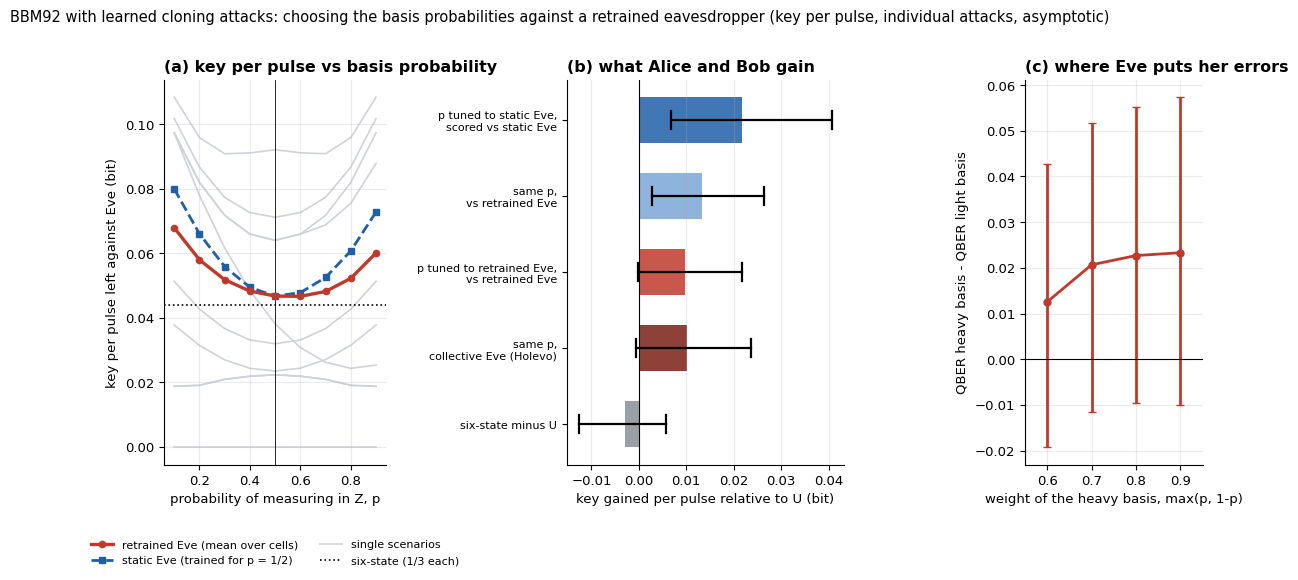


Saved: cell7_main_table.csv/.tex, cell7_main_figure.png/.pdf, cell7_FULL_rows.csv, cell7_FULL_feas.csv


In [ ]:
# =====================================================================================================
# CELL 7  -  WHAT CAN ALICE AND BOB DO, PER PULSE?   Choosing the basis probabilities against a RETRAINED learned attacker, and honest per-pulse accounting of six-state.   STANDALONE: runs on its own in Colab
#
# Why this cell.  Cell 6 reported key per SIFTED bit.  That hides the sifting cost: two equiprobable bases keep 1/2 of the pulses, six-state keeps 1/3.  Here every rate is key per PULSE (per entangled pair emitted).
# Defender strategies (Eve is INDIVIDUAL, same attack family, same key-rate layer, same pin as Cells 5 and 6; the pin is a property of the ATTACK: mean QBER over the measured bases = 1 - target, so Eve's budget does not depend on what Alice and Bob do):
#   U      Z and X, each chosen with probability 1/2 (BBM92 as in Cells 1-6).               per-pulse key  = 1/4 r_Z + 1/4 r_X
#   B(p)   Z with probability p, X with probability 1-p ("efficient BBM92"; both parties choose independently, a basis is usable when both chose it).   per-pulse key = p^2 r_Z + (1-p)^2 r_X
#   SIX    Z, X, Y each with probability 1/3 (six-state BBM92).                         per-pulse key  = (r_Z + r_X + r_Y)/9
# Eve BEST-RESPONDS: for every defender strategy she is retrained (QCL and Q-BAC, 36 / 42 parameters) to minimise the per-pulse key at the same pinned QBER.  r_b = I(A:B) - min(I(A:E), I(B:E)) from the exact joint distribution.
# Robustness of the evaluation (so a reviewer cannot blame the optimiser):
#   - LIBRARY ENVELOPE: every attack found for any defender strategy is a valid attack against every other one (the pin does not depend on the defender), so Eve's strength against strategy p is the MINIMUM over the whole library.
#   - REFINEMENT: each strategy is re-optimised once more from the best library member.  Only attacks that meet the pin (|Fab - target| <= 0.003 after continuation polishing) are admitted.
#   - CROSS-FIT: the defender's p-hat in a cell is chosen from the OTHER targets of the same scenario (never from the cell it is scored on), so there is no winner's-curse bias.
#   - STATIC EVE: an attack trained for U and never retrained, evaluated against B(p-hat); the gap to the retrained Eve is the value of adaptivity.
#   - COLLECTIVE: the same library evaluated with Holevo chi instead of measured information (Eve with quantum memory).
# Pre-registered decision rule (fixed BEFORE the run; unit = cell = (scenario, target); key in bit per pulse):
#   V   validity : (i) no attack below the collective lower bound 1-h(e_b)-h(e_b') in any basis ; (ii) Holevo-based rate <= measured-information rate for every attack ; (iii) >= 90% of attacks meet the pin and every (cell, model) has an admitted attack
#   H1  six-state per pulse vs U   : mean( rate_U - rate_SIX ), 95% bootstrap CI; 'does not pay' if the CI is above 0, 'pays' if below 0, else inconclusive   (rates against the retrained Eve of each strategy)
#   H2  biasing the bases helps against a RETRAINED Eve : mean( rate_B(p-hat) - rate_U ), CI above 0                (p-hat cross-fitted)
#   H3  adaptivity matters                  : mean( gain against the STATIC Eve - gain against the retrained Eve ) CI above 0
#   H4  Eve's best response overloads the heavy basis   : mean( q_heavy - q_light ) over p in {0.7, 0.8, 0.9} (and mirrored), CI above 0
#   H5  the gain survives a collective Eve  : mean( rate_B(p-hat) - rate_U ) evaluated with Holevo chi, CI above 0
#   (reported, not gated: Q-BAC vs QCL under biased bases ; share of strategies whose first optimisation was already converged)
# Output    : ONE main table (cell7_main_table.csv/.tex) and ONE main figure (cell7_main_figure.png/.pdf); raw library in cell7_<MODE>_rows.csv.  Resumable per scenario.  MODE = "DEV" is a smoke test.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W, GAIN_TOL, SEED = 0.2, 1000.0, 1e-3, 0
W_F, TOL = 1000.0, 0.003       # pin penalty of the first stage ; admission tolerance |Fab - target| after polishing
POL = [(1e4, 0.2, 300), (1e5, 0.0, 300)]       # continuation: (penalty, leak below zero rate, max iterations); the last stage optimises the CLIPPED per-pulse rate that is reported
CHECK_ALL_VARIANTS = False
if MODE == "DEV": TARGETS, R, R_RND, R_SIX, MAXITER, SCEN_IDS, PG = [0.65, 0.85], 3, 1, 3, 300, ["AB1", "AB5", "EV2"], [0.3, 0.5, 0.7]
else:             TARGETS, R, R_RND, R_SIX, MAXITER, SCEN_IDS, PG = [0.55, 0.65, 0.75, 0.85, 0.95], 6, 1, 8, 500, None, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
GRID_N = 41
ROWS_CSV = f"cell7_{MODE}_rows.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# =====================================================================================================  KEY-RATE LAYER  (shared by Cells 5 and 6)
# Individual attack, Eve measures each ancilla separately in a trained basis (per BBM92 basis, after the basis announcement) and keeps the raw 4-valued outcome e = (e1,e2).
# Joint distribution per basis P(a,b,e) is computed EXACTLY from the density matrix.  Secret-key rate (Csiszar-Korner / Maurer, one-way public communication, i.i.d.):
#       r_basis = I(A:B) - min( I(A:E), I(B:E) )         (direct or reverse reconciliation, whichever is better for Alice and Bob)
# Eve's raw outcome is used (not only her Bayes guess), so Eve is NOT understated.  Reported rates are clipped at 0 (a key rate cannot be negative).
SDG = jnp.diag(jnp.array([1, -1j], dtype=CD)); HYA = H2 @ SDG; HYB = XG @ H2 @ SDG          # Y basis; Bob's labels are flipped because Phi+ is ANTI-correlated in Y
BAS = {"Z": (I2, I2, I2), "X": (H2, H2, H2), "Y": (HYA, HYB, I2)}                              # (Alice, Bob, ancilla pre-rotation)
def xlog2(p):
    q = jnp.clip(p, 0.0, 1.0); ok = q > 1e-14; return jnp.where(ok, q * jnp.log2(jnp.where(ok, q, 1.0)), 0.0)
def Hs(p): return -jnp.sum(xlog2(p))
def joint(rho, bname, V1, V2):
    HA, HB, Hn = BAS[bname]; Wm = kr(HA, Hn @ V1, HB, Hn @ V2); d = jnp.clip(jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T)), 0.0)
    return d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)                          # P[a, b, e1e2]
def info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = Hs(Pab.sum(1)), Hs(Pab.sum(0)), Hs(P.sum((0, 1)))
    iab = Ha + Hb_ - Hs(Pab.ravel()); iae = Ha + He - Hs(Pae.ravel()); ibe = Hb_ + He - Hs(Pbe.ravel())
    q = P[0, 1].sum() + P[1, 0].sum(); guess = jnp.max(Pae, axis=0).sum()
    return jnp.stack([q, iab, iae, ibe, iab - jnp.minimum(iae, ibe), guess, Pab.sum(1)[1], Pab.sum(0)[1]])    # q, I_AB, I_AE, I_BE, rate, Bayes-guess, P(a=1), P(b=1)
SN = ["q", "iab", "iae", "ibe", "rate", "guess", "ma", "mb"]
def h2(e): e = np.clip(np.asarray(e, float), 1e-15, 1 - 1e-15); return -e * np.log2(e) - (1 - e) * np.log2(1 - e)

def make_rate_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        if name in ("PCCMV", "PCCM0"): UA, UB = block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]); r = x[2:]
        else: n = NP_[name]; UA, UB = block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]); r = x[2 * n:]
        V = [I2] * (2 * nb) if name == "PCCM0" else [vblock(r[3 * i:3 * i + 3]) for i in range(2 * nb)]
        return UA, UB, V
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])      # (nb, 8)
    def loss(name):
        def fn(x, f, p, base, wf, wsym):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb))
            L = jnp.mean(S[:, 4]) + wf * (fab - f) ** 2 + MARG_W * bias + wsym * jnp.sum((q - jnp.mean(q)) ** 2)
            return L, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC", "PCCMV", "PCCM0"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def unpack(aux, nb): a = np.asarray(aux); return a[:nb * 8].reshape(nb, 8), float(a[-1])
def rate_of(S): return float(np.mean(np.maximum(S[:, 4], 0.0)))                                    # clipped key rate, mean over bases
def sp_bound(S):
    """Collective-attack lower bound valid for ANY attack with these per-basis error rates: r_b >= 1 - h(e_b) - h(e_b') for every other basis b'.  Our individual attack can never go below it."""
    q = S[:, 0]; nb = len(q); return float(np.mean([max(0.0, 1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i)) for i in range(nb)])) if nb > 1 else np.nan
def sp_each(S):
    q = S[:, 0]; nb = len(q); return np.array([1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i) for i in range(nb)])
def row_of(S, bias, bases, tag):
    d = dict(tag)
    for i, b in enumerate(bases):
        for k, nm in enumerate(SN): d[f"{nm}_{b}"] = float(S[i, k])
    d.update(bias=bias, fab=float(1 - np.mean(S[:, 0])), rate=rate_of(S), sp=sp_bound(S), rate_raw=float(np.mean(S[:, 4])), guess_info=float(np.mean([1 - h2(1 - S[i, 5]) for i in range(len(bases))])),
             info_ae=float(np.mean(S[:, 2])), info_ab=float(np.mean(S[:, 1])))
    return d

# ----------------------------------------------------------------------------------------------- independent NumPy cross-check of the information layer + quantum (Holevo) evaluation
def np_rho_tensor(scen, UA, UB, p):
    _, _, _, pre, post, src = scen
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1 / np.sqrt(2); rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())          # axes (A,B,E1,E2 | primes)
    if src:
        mix = np.zeros((2,) * 8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1 - p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    return rho
def np_split(name, x, nb):
    if name in ("PCCMV", "PCCM0"): UA, UB, r = np_block(OPS["PCCM"], x[0:1]), np_block(OPS["PCCM"], x[1:2]), x[2:]
    else: n = NP_[name]; UA, UB, r = np_block(OPS[name], x[:n]), np_block(OPS[name], x[n:2 * n]), x[2 * n:]
    V = [np.eye(2, dtype=complex)] * (2 * nb) if name == "PCCM0" else [np_gate("RZ", r[3 * i + 2]) @ np_gate("RY", r[3 * i + 1]) @ np_gate("RX", r[3 * i]) for i in range(2 * nb)]
    return UA, UB, V
_Hn = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); _Sd = np.diag([1, -1j]); _Xn = np.array([[0, 1], [1, 0]], complex)
NBAS = {"Z": (np.eye(2, dtype=complex),) * 3, "X": (_Hn,) * 3, "Y": (_Hn @ _Sd, _Xn @ _Hn @ _Sd, np.eye(2, dtype=complex))}
def np_ent(p): p = np.asarray(p, float).ravel(); p = p[p > 1e-14]; return float(-(p * np.log2(p)).sum())
def np_info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = np_ent(Pab.sum(1)), np_ent(Pab.sum(0)), np_ent(P.sum((0, 1)))
    iab, iae, ibe = Ha + Hb_ - np_ent(Pab), Ha + He - np_ent(Pae), Hb_ + He - np_ent(Pbe)
    return np.array([P[0, 1].sum() + P[1, 0].sum(), iab, iae, ibe, iab - min(iae, ibe), Pae.max(axis=0).sum(), Pab.sum(1)[1], Pab.sum(0)[1]])
def np_stats(scen, name, x, p, bases):
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for i, b in enumerate(bases):
        HA, HB, Hn = NBAS[b]; rr = rho
        for q, M in enumerate((HA, HB, Hn @ V[2 * i], Hn @ V[2 * i + 1])): rr = ap1(rr, M, q)
        out.append(np_info(np.real(np.einsum('abcdabcd->abcd', rr)).reshape(2, 2, 4)))
    return np.array(out)
def vn_ent(r): w = np.linalg.eigvalsh((r + r.conj().T) / 2); return np_ent(w)
def np_holevo(scen, name, x, p, bases):
    """Quantum (collective-attack) bound: Eve keeps both ancillas in quantum memory.  chi(A:E), chi(B:E) from the exact reduced states; returns per basis (chi_AE, chi_BE)."""
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for b in bases:
        HA, HB, _ = NBAS[b]; res = []
        for qi, Hq in ((0, HA), (1, HB)):
            rr = ap1(rho, Hq, qi); states = []
            for a in (0, 1):
                sl = rr[a, :, :, :, a, :, :, :] if qi == 0 else rr[:, a, :, :, :, a, :, :]; states.append(np.einsum('bcdbfg->cdfg', sl).reshape(4, 4))
            tot = states[0] + states[1]; chi = vn_ent(tot) - sum(np.real(np.trace(s)) * vn_ent(s / max(np.real(np.trace(s)), 1e-300)) for s in states if np.real(np.trace(s)) > 1e-14); res.append(chi)
        out.append(res)
    return np.array(out)
def np_rhoAB(scen, name, x, p, nb=2):
    UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); return np.einsum('abcdefcd->abef', rho).reshape(4, 4)
PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1]).astype(complex)}
def corr_matrix(rAB): return np.array([[np.real(np.trace(rAB @ np.kron(PAULI[i], PAULI[j]))) for j in "XYZ"] for i in "XYZ"])
def chsh_max(T): u = np.sort(np.linalg.eigvalsh(T.T @ T))[::-1]; return float(2 * np.sqrt(u[0] + u[1]))

def preflight56():
    print("=" * 100); print("PREFLIGHT (key-rate layer)"); rng = np.random.default_rng(321); ok = True
    # (a) Y basis alignment: with no attack Alice and Bob agree in Z, X and Y
    rho = make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); e = max(float(info(joint(rho, b, I2, I2))[0]) for b in "ZXY")
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: QBER in Z, X, Y is 0 (max {e:.1e})"); ok &= e < 1e-12
    # (b) JAX information layer == independent NumPy (statistics, three bases, all models, several scenarios)
    worst = 0.
    for sc in SCEN[:3]:
        sim = make_sim(sc[3], sc[4], sc[5]); eng = make_rate_engines(sim, ("Z", "X", "Y"))
        for nm in ("QCL", "QBAC", "PCCMV"):
            n = NP_["PCCM" if nm == "PCCMV" else nm]; x = rng.uniform(-3, 3, 2 * n + 18)
            worst = max(worst, np.abs(np.asarray(eng["st_" + nm](jnp.asarray(x), STRENGTH)) - np_stats(sc, nm, x, STRENGTH, ("Z", "X", "Y"))).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX I(A:B), I(A:E), I(B:E), QBER, rate, marginals == independent NumPy, bases Z/X/Y (max dev {worst:.1e})"); ok &= worst < 1e-9
    # (c) Holevo bound >= classical information of the actual measurement (two independent computations)
    worst = 0.
    for sc in SCEN[:3]:
        for nm in ("QCL", "QBAC"):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); S = np_stats(sc, nm, x, STRENGTH, ("Z", "X")); Hv = np_holevo(sc, nm, x, STRENGTH, ("Z", "X"))
            worst = min(worst, float((Hv[:, 0] - S[:, 2]).min()), float((Hv[:, 1] - S[:, 3]).min()))
    print(f"  [{'OK' if worst > -1e-9 else 'FAIL'}] Holevo chi(A:E), chi(B:E) >= measured I(A:E), I(B:E)  (min slack {worst:.1e})"); ok &= worst > -1e-9
    # (d) Correlation-matrix QBER == joint-distribution QBER (Phi+ : XX=+1, YY=-1, ZZ=+1)
    sc = SCEN[0]; x = rng.uniform(-3, 3, 42); T = corr_matrix(np_rhoAB(sc, "QCL", x, STRENGTH, 3)); S = np_stats(sc, "QCL", x, STRENGTH, ("Z", "X", "Y"))
    e = max(abs((1 - T[2, 2]) / 2 - S[0, 0]), abs((1 - T[0, 0]) / 2 - S[1, 0]), abs((1 + T[1, 1]) / 2 - S[2, 0])); print(f"  [{'OK' if e < 1e-9 else 'FAIL'}] QBER from correlators == QBER from outcome statistics (dev {e:.1e})"); ok &= e < 1e-9
    # (e) gradients of the rate loss vs finite differences
    sc = SCEN[0]; eng = make_rate_engines(make_sim(sc[3], sc[4], sc[5]), ("Z", "X", "Y")); base = eng["base"](STRENGTH); err = 0.
    for nm in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[nm] + 18); args = (0.7, STRENGTH, base, 1000., 5.); (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; fd = (float(eng["ev_" + nm](jnp.asarray(x + d), *args)[0]) - float(eng["ev_" + nm](jnp.asarray(x - d), *args)[0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] rate-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (f) no-attack / noiseless rate is 1 (full key), and fully correlated Eve gives rate <= 0
    print(f"  [OK] information layer sanity: no attack -> I(A:B)={float(info(joint(rho, 'Z', I2, I2))[1]):.3f} bit, I(A:E)={float(info(joint(rho, 'Z', I2, I2))[2]):.3f}")
    assert ok, "PREFLIGHT (key-rate layer) FAILED - do not trust any result below"; print("  PREFLIGHT (key-rate layer) PASSED\n")

# ----------------------------------------------------------------------------------------------- weighted per-pulse engine
import json
def make_w_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        n = NP_[name]; return block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]), [vblock(x[2 * n:][3 * i:3 * i + 3]) for i in range(2 * nb)]
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])
    def loss(name):
        def fn(x, f, p, base, wf, wts, leak):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb)); r = S[:, 4]; reff = jnp.where(r > 0, r, leak * r)
            return jnp.sum(wts * reff) + wf * (fab - f) ** 2 + MARG_W * bias, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def wts2(pz): return jnp.array([pz ** 2, (1 - pz) ** 2])
WTS6 = jnp.array([1 / 9] * 3)
def rpp(S, w): return float(np.sum(np.asarray(w) * np.maximum(S[:, 4], 0.0)))                       # clipped per-pulse key rate

def preflight7():
    print("=" * 100); print("PREFLIGHT (Cell 7: per-pulse engine)"); rng = np.random.default_rng(777); ok = True
    sc = SCEN[0]; sim = make_sim(sc[3], sc[4], sc[5]); E = make_w_engines(sim, ("Z", "X")); L = make_rate_engines(sim, ("Z", "X")); base = E["base"](STRENGTH)
    # (a) the weighted engine reproduces the validated Cell 5/6 engine and its NumPy cross-check
    dev = 0.
    for m in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[m] + 12); dev = max(dev, float(np.abs(np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)) - np.asarray(L["st_" + m](jnp.asarray(x), STRENGTH))).max()), float(np.abs(np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)) - np_stats(sc, m, x, STRENGTH, ("Z", "X"))).max()))
    print(f"  [{'OK' if dev < 1e-9 else 'FAIL'}] weighted engine statistics == Cell 5/6 engine == independent NumPy (max dev {dev:.1e})"); ok &= dev < 1e-9
    # (b) with weights (1/2, 1/2) and no pin the loss is the Cell 5/6 loss (mean rate), and with weights p^2, (1-p)^2 it is the weighted sum of the per-basis rates
    err = 0.
    for m in ("QCL", "QBAC"):
        x = jnp.asarray(rng.uniform(-3, 3, 2 * NP_[m] + 12)); a = float(E["ev_" + m](x, 0.7, STRENGTH, base, 0., jnp.array([.5, .5]), 1.0)[0]); b = float(L["ev_" + m](x, 0.7, STRENGTH, base, 0., 0.)[0]); err = max(err, abs(a - b))
        S = np.asarray(E["st_" + m](x, STRENGTH)); aux = np.asarray(E["ev_" + m](x, 0.7, STRENGTH, base, 0., wts2(0.7), 1.0)[1]); bias = float(aux[-1])
        err = max(err, abs(float(E["ev_" + m](x, 0.7, STRENGTH, base, 0., wts2(0.7), 1.0)[0]) - (0.49 * S[0, 4] + 0.09 * S[1, 4] + MARG_W * bias)))
    print(f"  [{'OK' if err < 1e-10 else 'FAIL'}] loss with weights (1/2,1/2) == Cell 5/6 loss ; with (p^2,(1-p)^2) == weighted sum of per-basis rates (dev {err:.1e})"); ok &= err < 1e-10
    # (c) gradients vs finite differences (weighted, leaky)
    err = 0.
    for m in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[m] + 12); args = (0.7, STRENGTH, base, 1000., wts2(0.8), 0.2); (_, _), g = E[m](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; err = max(err, abs((float(E["ev_" + m](jnp.asarray(x + d), *args)[0]) - float(E["ev_" + m](jnp.asarray(x - d), *args)[0])) / 2e-6 - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] weighted-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (d) accounting: with no attack the per-pulse key is p^2 + (1-p)^2 (sifting efficiency) and 1/3 for six-state
    rho = sim([], [], False) if False else make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); S2 = np.stack([np.asarray(info(joint(rho, b, I2, I2))) for b in "ZX"]); S3 = np.stack([np.asarray(info(joint(rho, b, I2, I2))) for b in "ZXY"])
    e = max(abs(rpp(S2, wts2(p)) - (p ** 2 + (1 - p) ** 2)) for p in (0.3, 0.5, 0.9)); e = max(e, abs(rpp(S3, WTS6) - 1 / 3))
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: per-pulse key = p^2+(1-p)^2 for B(p) (1/2 for U) and 1/3 for six-state (dev {e:.1e})"); ok &= e < 1e-12
    assert ok, "PREFLIGHT (Cell 7) FAILED - do not trust any result below"; print("  PREFLIGHT (Cell 7) PASSED\n")

# ----------------------------------------------------------------------------------------------- main loop
preflight(); preflight56(); preflight7()
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
assert 0.5 in PG; NM = ("QCL", "QBAC")
nt = len(SCEN) * len(TARGETS) * 2 * (R + 1 + (len(PG) - 1) * (2 + R_RND + 1) + 2 * len(PG) + 3 + R_SIX + 3)
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(TARGETS)} targets x 2 models x ({len(PG)} basis probabilities + six-state, with refinement) ~ {nt} optimisation runs (~{nt*0.6/60:.0f} min), strength {STRENGTH}", flush=True)
t0 = time.time(); FEAS = []; FEAS_CSV = f"cell7_{MODE}_feas.csv"
def polish(E, m, x, f, base, w):
    for wf, leak, it in POL: x = run_min(E[m], x, (f, STRENGTH, base, wf, w, leak), it).x
    return x
def solve(E, m, x0s, f, base, w):
    best = None
    for x0 in x0s:
        o = run_min(E[m], x0, (f, STRENGTH, base, W_F, w, 1.0), MAXITER)
        if best is None or o.fun < best.fun: best = o
    return polish(E, m, best.x, f, base, w)
for sc in SCEN:
    sid, group, label, pre, post, src = sc
    if sid in done: print(f"  {sid} already done, skipped"); continue
    sim = make_sim(pre, post, src); E2, E3 = make_w_engines(sim, ("Z", "X")), make_w_engines(sim, ("Z", "X", "Y")); b2, b3 = np.asarray(E2["base"](STRENGTH)), np.asarray(E3["base"](STRENGTH)); rows = []
    rho0 = sim(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), STRENGTH); q0 = {b: float(info(joint(rho0, b, I2, I2))[0]) for b in "ZXY"}          # no-attack QBER: the highest fidelity any attack can leave
    F0_2, F0_3 = 1 - (q0["Z"] + q0["X"]) / 2, 1 - (q0["Z"] + q0["X"] + q0["Y"]) / 3; FEAS.append(dict(scen=sid, f0_2=F0_2, f0_3=F0_3))
    def record(E, bases, m, x, f, kind, pz):
        S = np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)); base = np.asarray(E["base"](STRENGTH)); nb = len(bases)
        bias = float(sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb)))
        d = row_of(S, bias, bases, dict(scen=sid, label=label, target=f, model=m, okind=kind, pz_train=pz, fab_target=f)); Hv = np_holevo(sc, m, np.asarray(x), STRENGTH, bases)
        for i, b in enumerate(bases): d[f"chiAE_{b}"], d[f"chiBE_{b}"] = Hv[i]
        d["x"] = json.dumps([round(float(v), 12) for v in x]); rows.append(d); return S
    for f in TARGETS:
        ok2, ok3 = f <= F0_2 + 1e-9, f <= F0_3 + 1e-9                                                  # a target above the no-attack fidelity cannot be reached by any attack: the cell does not exist for that defender
        if not (ok2 or ok3): continue
        for m in NM:
            lib = []                                                                                    # (x, S) of every admitted-or-not attack, for the envelope inside the refinement
            def add_lib(x, kind, pz, E=E2, bases=("Z", "X")): S = record(E, bases, m, x, f, kind, pz); lib.append((np.asarray(x), S)); return S
            def best_in_lib(w):
                v = [rpp(S, w) if abs(1 - S[:, 0].mean() - f) <= TOL else np.inf for _, S in lib]; k = int(np.argmin(v)); return lib[k][0], v[k]
            sol = {}
            if ok2: sol[0.5] = solve(E2, m, list(rng_for("c7", sid, f, 0.5).uniform(-np.pi, np.pi, (R, 36))), f, b2, wts2(0.5)); add_lib(sol[0.5], "train", 0.5)
            ups = sorted(p for p in PG if p > 0.5); downs = sorted((p for p in PG if p < 0.5), reverse=True)
            for chain in (ups, downs) if ok2 else ():
                prev = sol[0.5]
                for pz in chain:
                    x0s = [prev, sol[0.5]] + list(rng_for("c7", sid, f, pz).uniform(-np.pi, np.pi, (R_RND, 36))); sol[pz] = solve(E2, m, x0s, f, b2, wts2(pz)); prev = sol[pz]; add_lib(sol[pz], "train", pz)
            for pz in (PG if ok2 else ()):                                                               # refinement from the best library member at this strategy
                x0, _ = best_in_lib(wts2(pz)); add_lib(solve(E2, m, [x0], f, b2, wts2(pz)), "refine", pz)
            if ok3:
                rr = rng_for("c7six", sid, f); x0s = list(rr.uniform(-np.pi, np.pi, (R_SIX, 42)))
                if lib: x2, _ = best_in_lib(wts2(0.5)); x0s += [np.concatenate([x2, rr.uniform(-np.pi, np.pi, 6)]) for _ in range(3)]
                record(E3, ("Z", "X", "Y"), m, solve(E3, m, x0s, f, b3, WTS6), f, "six", np.nan)
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False); pd.DataFrame(FEAS[-1:]).to_csv(FEAS_CSV, mode="a", header=not os.path.exists(FEAS_CSV), index=False)
    print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis
ids = [s[0] for s in SCEN]; lab_of = {s[0]: s[2] for s in SCEN}; D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin(ids)].copy(); FE = pd.read_csv(FEAS_CSV).drop_duplicates("scen").set_index("scen")
D["gap"] = (D.fab - D.fab_target).abs(); D["adm"] = D.gap <= TOL; D2, D3 = D[D.okind != "six"], D[D.okind == "six"]
rngb = np.random.default_rng(1)
def boot(d, n=5000): d = np.asarray(d, float); d = d[~np.isnan(d)]; return np.percentile(rngb.choice(d, (n, len(d))).mean(1), [2.5, 97.5]) if len(d) else np.array([np.nan, np.nan])
PGa = np.array(sorted(PG)); j05 = int(np.argmin(np.abs(PGa - 0.5)))
def rp(df, pz): return pz ** 2 * np.maximum(df.rate_Z, 0) + (1 - pz) ** 2 * np.maximum(df.rate_X, 0)                                                      # per-pulse key, measured information
def cp(df, pz): return pz ** 2 * np.maximum(df.iab_Z - np.minimum(df.chiAE_Z, df.chiBE_Z), 0) + (1 - pz) ** 2 * np.maximum(df.iab_X - np.minimum(df.chiAE_X, df.chiBE_X), 0)   # per-pulse key, Holevo chi (collective)
cells = [(s, f) for s in ids for f in TARGETS if f <= FE.loc[s, "f0_2"] + 1e-9]; nC = len(cells); skipped = [(s, f) for s in ids for f in TARGETS if f > FE.loc[s, "f0_2"] + 1e-9]
# ---- V
viol, worst, nchk, vcoll = 0, 0., 0, 0
for _, r in D.iterrows():
    bs = [b for b in "ZXY" if not np.isnan(r.get(f"q_{b}", np.nan))]
    for b in bs:
        lb = 1 - h2(r[f"q_{b}"]) - min(h2(r[f"q_{c}"]) for c in bs if c != b); nchk += 1; worst = min(worst, r[f"rate_{b}"] - lb); viol += r[f"rate_{b}"] < lb - 1e-6
        vcoll += (r[f"iab_{b}"] - min(r[f"chiAE_{b}"], r[f"chiBE_{b}"])) > r[f"rate_{b}"] + 1e-9
ctab = D2.groupby(["scen", "target", "model"]).adm.max(); n_noadm = int((~ctab).sum()); share = float(D.adm.mean()); V = viol == 0 and vcoll == 0 and share >= 0.90 and n_noadm == 0
print("\n" + "=" * 140); print("VALIDITY (rule V)")
print(f"  (i)   per-basis key below the collective lower bound: {viol}/{nchk}   (closest approach {worst:+.2e} bit)  |  (ii) Holevo-based rate above measured-information rate: {vcoll}/{nchk}")
print(f"  (iii) attacks meeting the pin (|Fab - target| <= {TOL}): {100*share:.1f}% of {len(D)} ; (cell, model) without an admitted attack: {n_noadm}      ==> V {'PASS' if V else 'FAIL'}")
print(f"  feasibility: a target above the no-attack fidelity cannot be reached by any attack; {len(skipped)} of {len(ids)*len(TARGETS)} (scenario, target) pairs are infeasible for two bases and are excluded: " + (", ".join(f"{s}@{f}" for s, f in skipped) if skipped else "none"))
# ---- per-cell arrays
RET, STAT, COLL, OWN, QZ, QX = (np.full((nC, len(PGa)), np.nan) for _ in range(6)); RM = {m: np.full((nC, len(PGa)), np.nan) for m in NM}; SIX = np.full(nC, np.nan)
for ci, (s, f) in enumerate(cells):
    d = D2[(D2.scen == s) & np.isclose(D2.target, f) & D2.adm]
    if d.empty: continue
    for j, pz in enumerate(PGa):
        v = rp(d, pz); k = v.idxmin(); RET[ci, j], QZ[ci, j], QX[ci, j], COLL[ci, j] = v[k], d.q_Z[k], d.q_X[k], cp(d, pz).min()
        own = d[(d.okind == "train") & np.isclose(d.pz_train, pz)]; OWN[ci, j] = rp(own, pz).min() if len(own) else np.nan
        for m in NM:
            dm = d[d.model == m]; RM[m][ci, j] = rp(dm, pz).min() if len(dm) else np.nan
    st = []
    for m in NM:
        dm = d[(d.model == m) & (d.okind == "train") & np.isclose(d.pz_train, 0.5)]
        if len(dm): k = rp(dm, 0.5).idxmin(); st.append(np.array([rp(dm.loc[[k]], pz).iloc[0] for pz in PGa]))
    if st: STAT[ci] = np.min(st, axis=0)
    d3 = D3[(D3.scen == s) & np.isclose(D3.target, f) & D3.adm]
    if len(d3): SIX[ci] = ((np.maximum(d3.rate_Z, 0) + np.maximum(d3.rate_X, 0) + np.maximum(d3.rate_Y, 0)) / 9).min()
# ---- cross-fitted strategy: p-hat of a cell is chosen from the OTHER targets of the same scenario
jhat = np.full(nC, -1)
for ci, (s, f) in enumerate(cells):
    oth = [cj for cj, (s2, f2) in enumerate(cells) if s2 == s and cj != ci and not np.isnan(RET[cj]).any()]
    if oth and not np.isnan(RET[ci]).any(): jhat[ci] = int(np.argmax(np.mean(RET[oth], axis=0) - 1e-9 * np.abs(PGa - 0.5)))
jhs = np.full(nC, -1)                                                                                    # a defender who ASSUMES a fixed (static) Eve picks p-hat from the static curve
for ci, (s, f) in enumerate(cells):
    oth = [cj for cj, (s2, f2) in enumerate(cells) if s2 == s and cj != ci and not np.isnan(STAT[cj]).any()]
    if oth and not np.isnan(STAT[ci]).any(): jhs[ci] = int(np.argmax(np.mean(STAT[oth], axis=0) - 1e-9 * np.abs(PGa - 0.5)))
val = (jhat >= 0) & (jhs >= 0); ii = np.where(val)[0]
G_ret = np.array([RET[c, jhat[c]] - RET[c, j05] for c in ii]); G_st = np.array([STAT[c, jhs[c]] - STAT[c, j05] for c in ii]); G_bf = np.array([RET[c, jhs[c]] - RET[c, j05] for c in ii]); G_co = np.array([COLL[c, jhat[c]] - COLL[c, j05] for c in ii])
U_ = RET[ii, j05]; B_ = np.array([RET[c, jhat[c]] for c in ii]); ph = np.array([PGa[jhat[c]] for c in ii]); cellsv = [cells[c] for c in ii]
sx = ~np.isnan(SIX[ii]); H1v = (U_ - SIX[ii])[sx]
def heavy(c):
    v = [(QZ[c, j] - QX[c, j]) if pz > 0.5 else (QX[c, j] - QZ[c, j]) for j, pz in enumerate(PGa) if abs(pz - 0.5) >= 0.2 - 1e-9]; return float(np.mean(v)) if v else np.nan
H4v = np.array([heavy(c) for c in ii])
# ---- main table (per scenario, mean over the cells that exist)
rows = []
def addrow(name, mask):
    ix = np.where(mask)[0]; sm = ~np.isnan(SIX[ii][ix]); rows.append({"Scenario": name, "cells": int(len(ix)), "U": U_[ix].mean(), "p-hat": ph[ix].mean(), "B(p-hat)": B_[ix].mean(), "gain": G_ret[ix].mean(), "gain, static Eve": G_st[ix].mean(), "same p vs retrained": G_bf[ix].mean(),
        "six-state": SIX[ii][ix][sm].mean() if sm.any() else np.nan, "six-state - U": (SIX[ii][ix][sm] - U_[ix][sm]).mean() if sm.any() else np.nan})
for sid in ids:
    mk = np.array([c[0] == sid for c in cellsv])
    if mk.any(): addrow(f"{sid}  {lab_of[sid]}", mk)
addrow("ALL (mean over cells)", np.ones(len(ii), bool)); T = pd.DataFrame(rows); T.to_csv("cell7_main_table.csv", index=False)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("\n" + "=" * 140); print("MAIN TABLE  Key per PULSE left against the retrained strongest attacker (QCL or Q-BAC); mean over the feasible targets.  U = Z,X equiprobable ; B(p-hat) = biased bases with p-hat cross-fitted ; static Eve = attack trained for U, not retrained ; six-state = Z,X,Y equiprobable"); print(T.to_string(index=False))
tex = ["\\begin{tabular}{lrrrrrrrr}", "\\toprule", "Scenario & cells & U & $\\hat p$ & B($\\hat p$) & gain & static-Eve gain & same $p$, retrained Eve & six-state \\\\", "\\midrule"] + [" & ".join([r["Scenario"], str(r["cells"])] + [f"{r[c]:.3f}" for c in ["U", "p-hat", "B(p-hat)", "gain", "gain, static Eve", "same p vs retrained", "six-state"]]) + " \\\\" for _, r in T.iterrows()] + ["\\bottomrule", "\\end{tabular}"]
open("cell7_main_table.tex", "w").write("\n".join(tex))
# ---- rules
c1, c2, c3a, c3b, c4, c5 = boot(H1v), boot(G_ret), boot(G_st), boot(G_bf), boot(H4v), boot(G_co); ok_ = lambda b: "PASS" if b else "FAIL"; H2, H3, H4, H5 = c2[0] > 0, (c3a[0] > 0 and c3b[1] < 0), c4[0] > 0, c5[0] > 0
h1 = "SIX-STATE PAYS PER PULSE" if c1[1] < 0 else ("SIX-STATE DOES NOT PAY PER PULSE" if c1[0] > 0 else "INCONCLUSIVE")
print("\n" + "=" * 140); print(f"PRE-REGISTERED DECISION RULE  ({len(ii)} cells with a cross-fitted strategy, of {nC} feasible cells; {int(np.sum(U_ > 1e-9))} of them leave a non-zero key against the retrained Eve at U)")
print(f"  H1  six-state vs U per pulse   : mean(rate_U - rate_SIX) = {H1v.mean():+.4f} bit/pulse, 95% CI [{c1[0]:+.4f}, {c1[1]:+.4f}]  over {len(H1v)} cells where both exist      ==> {h1}")
print(f"  H2  biasing the bases vs RETRAINED Eve : gain {G_ret.mean():+.4f} bit/pulse, CI [{c2[0]:+.4f}, {c2[1]:+.4f}]  (p-hat mean {ph.mean():.2f}; share of cells with p-hat != 1/2: {100*np.mean(np.abs(ph-.5)>1e-9):.0f}%)        {ok_(H2)}")
print(f"  H3  ignoring adaptivity backfires : a defender who optimises p against a STATIC Eve gains {G_st.mean():+.4f} [{c3a[0]:+.4f}, {c3a[1]:+.4f}] against her, but the SAME p against the retrained Eve gives {G_bf.mean():+.4f} [{c3b[0]:+.4f}, {c3b[1]:+.4f}]  (needs first CI above 0 and second CI below 0)        {ok_(H3)}")
print(f"  H4  Eve overloads the heavy basis : mean(q_heavy - q_light) = {np.nanmean(H4v):+.4f}, CI [{c4[0]:+.4f}, {c4[1]:+.4f}]        {ok_(H4)}")
print(f"  H5  collective Eve (Holevo)    : gain {G_co.mean():+.4f} bit/pulse, CI [{c5[0]:+.4f}, {c5[1]:+.4f}]        {ok_(H5)}")
dq = np.array([RM["QCL"][c, jhat[c]] - RM["QBAC"][c, jhat[c]] for c in ii]); dq5 = RM["QCL"][ii, j05] - RM["QBAC"][ii, j05]
print(f"  (reported) mean(QCL - Q-BAC) per pulse: at U {np.nanmean(dq5):+.4f} [{boot(dq5)[0]:+.4f}, {boot(dq5)[1]:+.4f}] ; at p-hat {np.nanmean(dq):+.4f} [{boot(dq)[0]:+.4f}, {boot(dq)[1]:+.4f}]  (> 0: Q-BAC leaves less key)")
conv = (OWN - RET)[~np.isnan(OWN)]; print(f"  (reported) share of (cell, strategy) pairs whose first optimisation was already within 0.002 of the library envelope: {100*float((conv <= 0.002).mean()):.0f}%   (the envelope and refinement repair the rest)")
print("  ==> " + ("all gated rules pass" if (V and H2 and H3 and H4 and H5) else "NOT all gated rules pass: report only the rules that hold (see above)"))
print("\n  mean per-pulse key against the retrained / static Eve, by Z-probability p:"); print(pd.DataFrame({"p": PGa, "retrained": np.nanmean(RET[ii], axis=0), "static (trained for U)": np.nanmean(STAT[ii], axis=0), "collective": np.nanmean(COLL[ii], axis=0)}).to_string(index=False))
# ---- figure
import matplotlib as mpl; from matplotlib.lines import Line2D
mpl.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
GREY, BLUE, RED, DRED = "#8a8f98", "#1f5fa8", "#c0392b", "#7b1f16"
fig = plt.figure(figsize=(13.4, 5.0)); gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.25, .8], wspace=.8); a, b, c = (fig.add_subplot(gs[i]) for i in range(3))
for sid in ids:
    mk = [k for k, cc in zip(ii, cellsv) if cc[0] == sid]
    if mk: a.plot(PGa, np.nanmean(RET[mk], axis=0), color="#cfd3d9", lw=1.2, zorder=1)
a.plot(PGa, np.nanmean(RET[ii], axis=0), color=RED, lw=2.4, marker="o", ms=4.5, zorder=4); a.plot(PGa, np.nanmean(STAT[ii], axis=0), color=BLUE, lw=2.0, ls="--", marker="s", ms=4, zorder=3)
if sx.any(): a.axhline(np.nanmean(SIX[ii][sx]), color="k", lw=1.2, ls=":", zorder=2)
a.axvline(.5, color="k", lw=.6); a.set_xlabel("probability of measuring in Z, p"); a.set_ylabel("key per pulse left against Eve (bit)"); a.grid(alpha=.25); a.set_title("(a) key per pulse vs basis probability", loc="left", fontweight="bold")
a.legend(handles=[Line2D([], [], color=RED, lw=2.4, marker="o", ms=4.5, label="retrained Eve (mean over cells)"), Line2D([], [], color=BLUE, lw=2, ls="--", marker="s", ms=4, label="static Eve (trained for p = 1/2)"), Line2D([], [], color="#cfd3d9", lw=1.2, label="single scenarios"), Line2D([], [], color="k", lw=1.2, ls=":", label="six-state (1/3 each)")], frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
names = ["p tuned to static Eve,\nscored vs static Eve", "same p,\nvs retrained Eve", "p tuned to retrained Eve,\nvs retrained Eve", "same p,\ncollective Eve (Holevo)", "six-state minus U"]; vals = [G_st, G_bf, G_ret, G_co, -H1v]; cis = [c3a, c3b, c2, c5, boot(-H1v)]; cols = [BLUE, "#7aa6d6", RED, DRED, GREY]
for i, (v, ci, col) in enumerate(zip(vals, cis, cols)): y = 4 - i; b.barh(y, v.mean(), .6, color=col, alpha=.85); b.plot(ci, [y, y], color="k", lw=1.6); b.plot([ci[0]] * 2, [y - .12, y + .12], color="k", lw=1.6); b.plot([ci[1]] * 2, [y - .12, y + .12], color="k", lw=1.6)
b.axvline(0, color="k", lw=.8); b.set_yticks(range(5)); b.set_yticklabels(names[::-1], fontsize=8); b.set_xlabel("key gained per pulse relative to U (bit)"); b.grid(axis="x", alpha=.25); b.set_title("(b) what Alice and Bob gain", loc="left", fontweight="bold")
hh = [.6, .7, .8, .9]; dm_, lo_, hi_ = [], [], []
for h in hh:
    v = []
    for cc in ii:
        for j, pz in enumerate(PGa):
            if abs(max(pz, 1 - pz) - h) < 1e-9: v.append((QZ[cc, j] - QX[cc, j]) if pz > .5 else (QX[cc, j] - QZ[cc, j]))
    v = np.array(v, float); ci = boot(v) if len(v) else [np.nan, np.nan]; dm_.append(np.nanmean(v) if len(v) else np.nan); lo_.append(ci[0]); hi_.append(ci[1])
c.errorbar(hh, dm_, yerr=[np.array(dm_) - np.array(lo_), np.array(hi_) - np.array(dm_)], color=RED, marker="o", ms=5, lw=2, capsize=3); c.axhline(0, color="k", lw=.8); c.set_xlim(.55, .95)
c.set_xlabel("weight of the heavy basis, max(p, 1-p)"); c.set_ylabel("QBER heavy basis - QBER light basis"); c.set_title("(c) where Eve puts her errors", loc="left", fontweight="bold"); c.grid(alpha=.25)
fig.suptitle("BBM92 with learned cloning attacks: choosing the basis probabilities against a retrained eavesdropper (key per pulse, individual attacks, asymptotic)", x=.01, ha="left", fontsize=10.5, y=1.02)
plt.savefig("cell7_main_figure.png", dpi=300, bbox_inches="tight"); plt.savefig("cell7_main_figure.pdf", bbox_inches="tight"); plt.show()
print("\nSaved: cell7_main_table.csv/.tex, cell7_main_figure.png/.pdf, " + ROWS_CSV + ", " + FEAS_CSV)

In [ ]:
# =====================================================================================================
# CELL 7b  -  EXPLORATORY re-analysis of the Cell 7 library (no training; reads cell7_<MODE>_rows.csv and cell7_<MODE>_feas.csv).  STANDALONE.
# Everything here is POST-HOC and must be labelled exploratory in the paper; the pre-registered rules stay as printed by Cell 7.
#   (A) fixed-strategy gains: for each p, mean( rate_B(p) - rate_U ) per pulse against the retrained Eve with 95% bootstrap CI (no cross-fitting, so no selection effect) - all feasible cells, and only cells where U leaves a non-zero key
#   (B) six-state vs U at EQUAL BUDGET: a target f means the same budget for Eve only when the no-attack fidelity is the same for two bases and for three bases (f0_2 == f0_3); otherwise the 3-basis Eve is more constrained at the same f
#   (C) where the gain comes from: by scenario family
# =====================================================================================================
MODE = "FULL"
import numpy as np, pandas as pd
TOL = 0.003; ROWS_CSV, FEAS_CSV = f"cell7_{MODE}_rows.csv", f"cell7_{MODE}_feas.csv"
D = pd.read_csv(ROWS_CSV); FE = pd.read_csv(FEAS_CSV).drop_duplicates("scen").set_index("scen"); ids = list(FE.index)
D = D[D.scen.isin(ids)].copy(); D["adm"] = (D.fab - D.fab_target).abs() <= TOL; D2, D3 = D[D.okind != "six"], D[D.okind == "six"]
PGa = np.array(sorted(D2.pz_train.dropna().unique())); j05 = int(np.argmin(np.abs(PGa - 0.5))); TARGETS = sorted(D.target.unique())
rngb = np.random.default_rng(1)
def boot(d, n=5000): d = np.asarray(d, float); d = d[~np.isnan(d)]; return np.percentile(rngb.choice(d, (n, len(d))).mean(1), [2.5, 97.5]) if len(d) else np.array([np.nan, np.nan])
def rp(df, pz): return pz ** 2 * np.maximum(df.rate_Z, 0) + (1 - pz) ** 2 * np.maximum(df.rate_X, 0)
cells = [(s, f) for s in ids for f in TARGETS if f <= FE.loc[s, "f0_2"] + 1e-9]; RET = np.full((len(cells), len(PGa)), np.nan); SIX = np.full(len(cells), np.nan)
for ci, (s, f) in enumerate(cells):
    d = D2[(D2.scen == s) & np.isclose(D2.target, f) & D2.adm]
    if d.empty: continue
    for j, pz in enumerate(PGa): RET[ci, j] = rp(d, pz).min()
    d3 = D3[(D3.scen == s) & np.isclose(D3.target, f) & D3.adm]
    if len(d3): SIX[ci] = ((np.maximum(d3.rate_Z, 0) + np.maximum(d3.rate_X, 0) + np.maximum(d3.rate_Y, 0)) / 9).min()
fam = np.array([("EV" if s.startswith("EV") else "AB") for s, _ in cells]); sid = np.array([s for s, _ in cells]); U = RET[:, j05]; pos = U > 1e-9; ok = ~np.isnan(U)
print("=" * 120); print(f"(A) FIXED-STRATEGY GAIN per pulse vs U against the retrained Eve (bit; mean over cells; 95% bootstrap CI).  {int(ok.sum())} feasible cells, {int((pos & ok).sum())} of them leave a non-zero key at U")
rows = []
for j, pz in enumerate(PGa):
    g = RET[:, j] - U; a, b = boot(g[ok]), boot(g[ok & pos]); rows.append({"p (Z)": pz, "all cells": g[ok].mean(), "CI all": f"[{a[0]:+.4f}, {a[1]:+.4f}]", "key-bearing cells": g[ok & pos].mean() if (ok & pos).any() else np.nan, "CI key-bearing": f"[{b[0]:+.4f}, {b[1]:+.4f}]", "relative gain (key-bearing)": g[ok & pos].mean() / U[ok & pos].mean() if (ok & pos).any() else np.nan})
pd.set_option("display.width", 220); pd.set_option("display.float_format", "{:.4f}".format); print(pd.DataFrame(rows).to_string(index=False))
print("\n" + "=" * 120); print("(B) SIX-STATE vs U per pulse, mean(rate_U - rate_SIX)  (> 0: six-state does not pay).  Equal budget = no-attack fidelity identical for two and three bases")
eq = np.array([abs(FE.loc[s, "f0_2"] - FE.loc[s, "f0_3"]) < 1e-9 for s, _ in cells]); h = U - SIX
for name, m in (("equal budget (fair)", eq & ~np.isnan(h)), ("unequal budget (six-state Eve is more constrained at the same f)", ~eq & ~np.isnan(h))):
    if m.any(): c = boot(h[m]); print(f"  {name:62s}: {h[m].mean():+.4f}  CI [{c[0]:+.4f}, {c[1]:+.4f}]   ({int(m.sum())} cells, scenarios {', '.join(sorted(set(sid[m])))})")
print("\n" + "=" * 120); print("(C) WHERE THE GAIN COMES FROM  (fixed strategies p = 0.1 and p = 0.9, mean gain per pulse vs U)")
for g_ in ("AB", "EV"):
    m = ok & (fam == g_); j1, j9 = 0, len(PGa) - 1
    if m.any(): print(f"  {g_} scenarios ({int(m.sum())} cells, {int((m & pos).sum())} key-bearing): p={PGa[j1]:.1f}: {np.nanmean(RET[m, j1] - U[m]):+.4f}   p={PGa[j9]:.1f}: {np.nanmean(RET[m, j9] - U[m]):+.4f}   U = {np.nanmean(U[m]):.4f}")


(A) FIXED-STRATEGY GAIN per pulse vs U against the retrained Eve (bit; mean over cells; 95% bootstrap CI).  43 feasible cells, 13 of them leave a non-zero key at U
 p (Z)  all cells             CI all  key-bearing cells     CI key-bearing  relative gain (key-bearing)
0.1000     0.0212 [+0.0068, +0.0383]             0.0700 [+0.0315, +0.1135]                       0.4525
0.2000     0.0112 [+0.0028, +0.0216]             0.0372 [+0.0129, +0.0653]                       0.2403
0.3000     0.0051 [+0.0009, +0.0109]             0.0167 [+0.0042, +0.0322]                       0.1080
0.4000     0.0016 [+0.0001, +0.0037]             0.0051 [+0.0006, +0.0119]                       0.0332
0.5000     0.0000 [+0.0000, +0.0000]             0.0000 [+0.0000, +0.0000]                       0.0000
0.6000    -0.0001 [-0.0019, +0.0012]            -0.0003 [-0.0060, +0.0038]                      -0.0017
0.7000     0.0014 [-0.0023, +0.0050]             0.0047 [-0.0076, +0.0155]                       0.0302
0.80

PREFLIGHT
  [OK] PCCM block unitary (dev 1.4e-16)
  [OK] QCL block unitary (dev 4.4e-16)
  [OK] QBAC block unitary (dev 3.3e-16)
  [OK] QCL1 block unitary (dev 4.4e-16)
  [OK] QCL3 block unitary (dev 4.4e-16)
  [OK] QCL_CRY block unitary (dev 2.2e-16)
  [OK] QCL_CRZ block unitary (dev 4.4e-16)
  [OK] QCL_CR01 block unitary (dev 4.4e-16)
  [OK] QCL_CR10 block unitary (dev 1.6e-16)
  [OK] QCL_CR block unitary (dev 4.4e-16)
  [OK] QBAC_noCRZ block unitary (dev 4.4e-16)
  [OK] QBAC_noCRY block unitary (dev 4.4e-16)
  [OK] QBAC_noCR01 block unitary (dev 2.5e-16)
  [OK] QBAC_noCR10 block unitary (dev 4.4e-16)
  [OK] QBAC_noCR block unitary (dev 2.2e-16)
  [OK] QBAC_x2 block unitary (dev 4.4e-16)
  [OK] Kraus completeness 'bf' (dev 1.1e-16)
  [OK] Kraus completeness 'dp' (dev 1.1e-16)
  [OK] Kraus completeness 'ad' (dev 1.1e-16)
  [OK] JAX engine == independent NumPy simulator on all scenarios (max dev 1.5e-13)
  [OK] Alice<->Bob swap: PCCM loss AB1 -0.825135612 vs AB4 -0.825135612
  [OK] noi

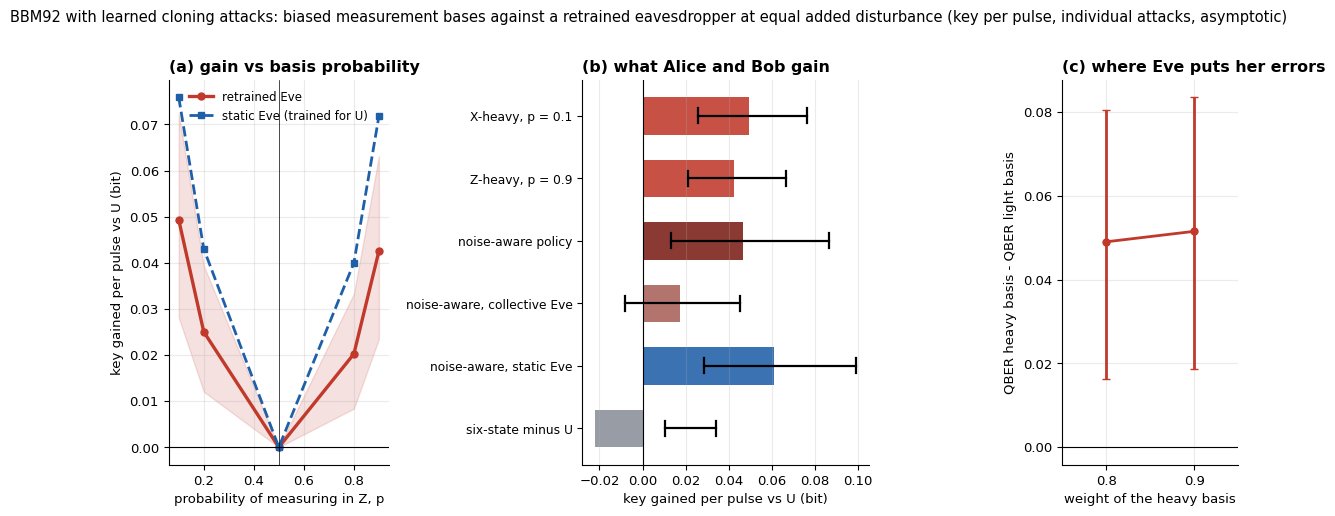


Saved: cell7c_main_table.csv/.tex, cell7c_main_figure.png/.pdf, cell7c_FULL_rows.csv, cell7c_FULL_feas.csv


In [ ]:
# =====================================================================================================
# CELL 7c  -  CONFIRMATORY TEST: do biased bases help Alice and Bob, per pulse, against a RETRAINED learned attacker?   STANDALONE: runs on its own in Colab
#
# Why this cell.  Cell 7 failed its cross-fitted rules, but its fixed-p analysis (Cell 7b, exploratory) showed a gain for X-heavy bases (p = 0.1: +0.021 bit/pulse, CI above 0) and a weaker one for Z-heavy bases (p = 0.9).  That was post hoc.
#               Here the two policies, a noise-aware policy and the six-state comparison are fixed in advance and tested on NEW cells, and Eve's budget is set RELATIVE to the benign channel (see below).
# Eve's budget : the ADDED disturbance dx = (no-attack fidelity) - (fidelity left by Eve), the same for two bases, three bases and every scenario.  Cell 7 used absolute targets; that gave Eve different budgets in different scenarios, left many
#               cells with no key at all, and handicapped the six-state Eve.  Every cell here exists (no infeasible targets) and compares all defenders at the same added disturbance.
# Defenders    : U = Z,X equiprobable | B(p) = Z with probability p | SIX = Z,X,Y equiprobable.  Key per PULSE: p^2 r_Z + (1-p)^2 r_X ; (r_Z + r_X + r_Y)/9.  Eve (QCL and Q-BAC, individual) is RETRAINED for each defender; library envelope + refinement exactly as in Cell 7.
# Pre-registered decision rule (fixed BEFORE the run; unit = cell = (scenario, dx); key in bit per pulse; bootstrap over cells):
#   V   validity : (i) no attack below the collective lower bound in any basis ; (ii) Holevo-based rate <= measured-information rate for every attack ; (iii) >= 90% of attacks meet the pin and every (cell, model) has an admitted attack
#   C1  X-heavy bases help      : policy p = 0.1 : mean( rate_B(0.1) - rate_U ) with a 98.75% bootstrap CI (Bonferroni over C1, C2) above 0
#   C2  Z-heavy bases help      : policy p = 0.9 : same test
#   C3  noise-aware policy      : in every scenario whose no-attack QBER differs between Z and X by >= 0.01, weight the basis with the LOWER no-attack QBER by 0.9 ; mean gain vs U with a 95% CI above 0
#   C4  six-state per pulse     : mean( rate_U - rate_SIX ), 95% CI : 'six-state does not pay' if above 0, 'pays' if below 0, otherwise inconclusive      (equal added disturbance, so no budget confound)
#   C5  Eve overloads the heavy basis : mean( q_heavy - q_light ) over p in {0.1, 0.2, 0.8, 0.9}, CI above 0
#   C6  the noise-aware gain survives a collective Eve (Holevo chi) : CI above 0
#   (reported, not gated: gains against a STATIC Eve trained for U ; Q-BAC versus QCL ; gain at every p)
# Output    : ONE main table (cell7c_main_table.csv/.tex) and ONE main figure (cell7c_main_figure.png/.pdf); raw library in cell7c_<MODE>_rows.csv.  Resumable per scenario.  MODE = "DEV" is a smoke test.
# =====================================================================================================
MODE = "FULL"                  # "DEV" = quick smoke test   |   "FULL" = paper run
STRENGTH, MARG_W, GAIN_TOL, SEED = 0.2, 1000.0, 1e-3, 7            # a NEW seed: the cells and the random starts differ from Cell 7
W_F, TOL = 1000.0, 0.003
POL = [(1e4, 0.2, 300), (1e5, 0.0, 300)]
CHECK_ALL_VARIANTS = False
if MODE == "DEV": DEXC, R, R_RND, R_SIX, MAXITER, SCEN_IDS, PG = [0.06, 0.12], 3, 1, 3, 300, ["AB1", "AB6", "EV2"], [0.1, 0.5, 0.9]
else:             DEXC, R, R_RND, R_SIX, MAXITER, SCEN_IDS, PG = [0.03, 0.06, 0.09, 0.12, 0.15], 6, 1, 8, 500, None, [0.1, 0.2, 0.5, 0.8, 0.9]
GRID_N = 41
ROWS_CSV = f"cell7c_{MODE}_rows.csv"
import os, time, zlib, itertools
import numpy as np, pandas as pd, jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
jax.config.update("jax_enable_x64", True)
CD = jnp.complex128
# ----------------------------------------------------------------------------------------------- scenarios
# (id, group, label, pre-noise [(slot,kind)], post-noise [(slot,kind)], Werner source?)   slots: A,B = flying qubits ; E = ancillas E1,E2
# kinds: bf bit-flip, ad amplitude damping, dp dephasing.   pre = before Eve's block, post = after it.
SCEN = [("AB1", "Alice-Bob", "Bob bit-flip, before Eve", [("B", "bf")], [], False),
        ("AB2", "Alice-Bob", "Bob bit-flip, after Eve", [], [("B", "bf")], False),
        ("AB3", "Alice-Bob", "Bob amp-damping, before Eve", [("B", "ad")], [], False),
        ("AB4", "Alice-Bob", "Alice bit-flip, before Eve", [("A", "bf")], [], False),
        ("AB5", "Alice-Bob", "Both arms dephasing, after Eve", [], [("A", "dp"), ("B", "dp")], False),
        ("AB6", "Alice-Bob", "Werner source (depolarizing)", [], [], True),
        ("EV1", "Eve", "Ancilla bit-flip, before", [("E", "bf")], [], False),
        ("EV2", "Eve", "Ancilla bit-flip, after", [], [("E", "bf")], False),
        ("EV3", "Eve", "Ancilla amp-damping, after", [], [("E", "ad")], False),
        ("EV4", "Eve", "Ancilla dephasing, after", [], [("E", "dp")], False)]
SCEN_ALL = list(SCEN)
if SCEN_IDS: SCEN = [s for s in SCEN if s[0] in SCEN_IDS]
WIRES = {"A": [0], "B": [2], "E": [1, 3]}                      # JAX state order: (A, E1, B, E2)

# ----------------------------------------------------------------------------------------------- gates / circuits (JAX)
I2 = jnp.eye(2, dtype=CD); XG = jnp.array([[0, 1], [1, 0]], dtype=CD); ZG = jnp.array([[1, 0], [0, -1]], dtype=CD)
H2 = jnp.array([[1, 1], [1, -1]], dtype=CD) / jnp.sqrt(2.0)
def RX(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -1j*s], [-1j*s, c]], dtype=CD)
def RY(t): c, s = jnp.cos(t/2), jnp.sin(t/2); return jnp.array([[c, -s], [s, c]], dtype=CD)
def RZ(t): return jnp.array([[jnp.exp(-1j*t/2), 0], [0, jnp.exp(1j*t/2)]], dtype=CD)
ONEQ = {"RX": RX, "RY": RY, "RZ": RZ}
def kr(*m):
    out = m[0]
    for a in m[1:]: out = jnp.kron(out, a)
    return out
def ctrl(U1, c, t):
    P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CD)), jnp.diag(jnp.array([0, 1], dtype=CD))
    return kr(P0, I2) + kr(P1, U1) if (c, t) == (0, 1) else kr(I2, P0) + kr(U1, P1)
PI = float(np.pi)
OPS = {  # local wire 0 = flying qubit, local wire 1 = Eve's ancilla.  ('p',i) = parameter i ; ('c',v) = constant
 "PCCM": [("RX", (0,), ('c', PI/2)), ("CRY", (0, 1), ('p', 0)), ("CRY", (1, 0), ('c', -PI)), ("RX", (0,), ('c', -PI/2)), ("RX", (1,), ('c', -PI/2))],
 "QCL": [(g, (q,), ('p', L*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
         for L in range(2) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]],
 "QBAC": [("RY", (0,), ('p', 0)), ("RZ", (0,), ('p', 1)), ("RY", (1,), ('p', 2)), ("RZ", (1,), ('p', 3)), ("CRY", (0, 1), ('p', 4)), ("CRZ", (0, 1), ('p', 5)),
          ("RY", (0,), ('p', 6)), ("CNOT", (0, 1), None), ("RZ", (1,), ('p', 7)), ("RX", (1,), ('p', 8)), ("CRY", (1, 0), ('p', 9)), ("CRZ", (1, 0), ('p', 10)),
          ("CNOT", (0, 1), None), ("RZ", (0,), ('p', 11))]}
NP_ = {"PCCM": 1, "QCL": 12, "QBAC": 12}
def _qcl(layers): return [(g, (q,), ('p', L_*6+q*3+k)) if g != "CNOT" else ("CNOT", (0, 1), None)
                          for L_ in range(layers) for g, q, k in [("RX", 0, 0), ("RY", 0, 1), ("RZ", 0, 2), ("RX", 1, 0), ("RY", 1, 1), ("RZ", 1, 2), ("CNOT", 0, 0)]]
def _build(seq):                                                                       # (gate, wires) sequence -> op list with consecutive parameter indices
    ops, k = [], 0
    for g, w in seq:
        if g == "CNOT": ops.append((g, w, None))
        else: ops.append((g, w, ('p', k))); k += 1
    return ops, k
_QB = [("RY", (0,)), ("RZ", (0,)), ("RY", (1,)), ("RZ", (1,)), ("CRY", (0, 1)), ("CRZ", (0, 1)), ("RY", (0,)), ("CNOT", (0, 1)), ("RZ", (1,)), ("RX", (1,)), ("CRY", (1, 0)), ("CRZ", (1, 0)), ("CNOT", (0, 1)), ("RZ", (0,))]
assert _build(_QB)[0] == OPS["QBAC"]                                                    # the builder reproduces the Q-BAC definition exactly
def _add(name, ops_n):
    OPS[name], NP_[name] = ops_n
_add("QCL1", (_qcl(1), 6)); _add("QCL3", (_qcl(3), 18))                                 # QCL depth ablations
for nm, extra in (("QCL_CRY", [("CRY", (0, 1)), ("CRY", (1, 0))]), ("QCL_CRZ", [("CRZ", (0, 1)), ("CRZ", (1, 0))]),            # QCL + controlled rotations added back (by type / by direction)
                  ("QCL_CR01", [("CRY", (0, 1)), ("CRZ", (0, 1))]), ("QCL_CR10", [("CRY", (1, 0)), ("CRZ", (1, 0))]),
                  ("QCL_CR", [("CRY", (0, 1)), ("CRZ", (0, 1)), ("CRY", (1, 0)), ("CRZ", (1, 0))])):
    ops_ = _qcl(2) + [(g, w, ('p', 12 + i)) for i, (g, w) in enumerate(extra)]; _add(nm, (ops_, 12 + len(extra)))
for nm, drop in (("QBAC_noCRZ", lambda g, w: g == "CRZ"), ("QBAC_noCRY", lambda g, w: g == "CRY"),                              # Q-BAC with controlled rotations removed (by type / by direction / all)
                 ("QBAC_noCR01", lambda g, w: g[:2] == "CR" and w == (0, 1)), ("QBAC_noCR10", lambda g, w: g[:2] == "CR" and w == (1, 0)),
                 ("QBAC_noCR", lambda g, w: g[:2] == "CR")):
    _add(nm, _build([(g, w) for g, w in _QB if not drop(g, w)]))
_add("QBAC_x2", _build(_QB + _QB))                                                       # depth control: Q-BAC block repeated twice
def block_unitary(ops, p):
    U = jnp.eye(4, dtype=CD)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ONEQ: G = kr(ONEQ[g](th), I2) if w[0] == 0 else kr(I2, ONEQ[g](th))
        elif g == "CNOT": G = ctrl(XG, 0, 1)
        elif g == "CRY": G = ctrl(RY(th), *w)
        else: G = ctrl(RZ(th), *w)
        U = G @ U
    return U
def vblock(p): return RZ(p[2]) @ RY(p[1]) @ RX(p[0])

# ----------------------------------------------------------------------------------------------- noisy BBM92 simulation (JAX, density matrix)
PHI = jnp.array([1, 0, 0, 1], dtype=CD) / jnp.sqrt(2.0)
PSI0 = jnp.kron(PHI, jnp.array([1, 0, 0, 0], dtype=CD)).reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(16)   # (A,E1,B,E2)
RHO_PURE = jnp.outer(PSI0, PSI0.conj()); P00 = jnp.diag(jnp.array([1, 0], dtype=CD)); RHO_MIX = kr(I2/2, P00, I2/2, P00)
def kraus(kind, p):
    p = jnp.asarray(p, dtype=jnp.float64)
    if kind == "bf": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * XG]
    if kind == "dp": return [jnp.sqrt(1-p).astype(CD) * I2, jnp.sqrt(p).astype(CD) * ZG]
    return [jnp.array([[1, 0], [0, jnp.sqrt(1-p)]], dtype=CD), jnp.array([[0, jnp.sqrt(p)], [0, 0]], dtype=CD)]
def chan(rho, kind, w, p):
    out = 0
    for K in kraus(kind, p):
        E = kr(*[K if i == w else I2 for i in range(4)]); out = out + E @ rho @ E.conj().T
    return out
def make_sim(pre, post, src):
    pre_l = [(w, k) for s, k in pre for w in WIRES[s]]; post_l = [(w, k) for s, k in post for w in WIRES[s]]
    def run(UA, UB, p):
        rho = (1-p) * RHO_PURE + p * RHO_MIX if src else RHO_PURE
        for w, k in pre_l: rho = chan(rho, k, w, p)
        U = kr(UA, UB); rho = U @ rho @ U.conj().T
        for w, k in post_l: rho = chan(rho, k, w, p)
        return rho
    return run
def basis_stats(rho, Hb, V1, V2):
    Wm = kr(Hb, Hb @ V1, Hb, Hb @ V2); d = jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T))
    P = d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)              # P[a, b, e1e2]
    return P[0, 1].sum() + P[1, 0].sum(), jnp.max(P.sum(1), axis=0).sum(), P[1].sum(), P[:, 1].sum()
def score_core(rho, V, f, base, lab, lae):
    (qz, sz, az, bz), (qx, sx, ax, bx) = basis_stats(rho, I2, V[0], V[1]), basis_stats(rho, H2, V[2], V[3])
    fab, fae = 1 - (qz + qx) / 2, (sz + sx) / 2
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax-base[2])**2 + (bx-base[3])**2         # Alice/Bob bit marginals vs the no-attack marginals
    L0 = 10 * (fab - f) ** 2 - fae
    return L0 + MARG_W * bias + lab * (qz - qx) ** 2 + lae * (sz - sx) ** 2, jnp.stack([1-qz, sz, 1-qx, sx, bias])   # aux: Fab_Z,Fae_Z,Fab_X,Fae_X,bias
def L0_of(aux, f): return 10 * ((aux[0] + aux[2]) / 2 - f) ** 2 - (aux[1] + aux[3]) / 2

def make_engines(sim):
    I4 = jnp.eye(4, dtype=CD); Iv = [I2] * 4
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for Hb in (I2, H2): _, _, a, b = basis_stats(rho, Hb, I2, I2); out += [a, b]
        return jnp.stack(out)
    def masked(UA, UB, mA, mB): return mA * UA + (1 - mA) * I4, mB * UB + (1 - mB) * I4
    def pccm(x, f, p, base, lab, lae, mA, mB):
        UA, UB = masked(block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]), mA, mB)
        return score_core(sim(UA, UB, p), Iv, f, base, lab, lae)
    def gen(name):
        ops, n = OPS[name], NP_[name]
        def fn(x, f, p, base, lab, lae, mA, mB):
            r = x[2*n:]; V = [vblock(r[3*i:3*i+3]) for i in range(4)]
            UA, UB = masked(block_unitary(ops, x[:n]), block_unitary(ops, x[n:2*n]), mA, mB)
            return score_core(sim(UA, UB, p), V, f, base, lab, lae)
        return fn
    ax9 = (None,) * 7
    eng = {"base": jax.jit(base_marg), "pccm_vg": jax.jit(jax.value_and_grad(pccm, has_aux=True)),
           "pccm_ev": jax.jit(pccm),
           "pccm_grid": jax.jit(jax.vmap(jax.vmap(lambda a, b, *r: pccm(jnp.array([a, b]), *r)[0], in_axes=(None, 0) + ax9), in_axes=(0, None) + ax9))}
    for m in OPS:
        if m == "PCCM": continue
        fn = gen(m); eng[m] = jax.jit(jax.value_and_grad(fn, has_aux=True)); eng[m + "_ev"] = jax.jit(fn)
        eng[m + "_h"] = jax.jit(jax.hessian(lambda x, *a, fn=fn: fn(x, *a)[0]))
    return eng

# ----------------------------------------------------------------------------------------------- PREFLIGHT: independent NumPy simulator + checks
def np_gate(g, th):
    c, s = np.cos(th/2), np.sin(th/2)
    return {"RX": np.array([[c, -1j*s], [-1j*s, c]]), "RY": np.array([[c, -s], [s, c]]), "RZ": np.diag([np.exp(-1j*th/2), np.exp(1j*th/2)])}[g]
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex); EYE2 = np.eye(2, dtype=complex); Z2 = np.zeros((2, 2), complex)
def np_block(ops, p):
    U = np.eye(4, dtype=complex)
    for g, w, a in ops:
        th = None if a is None else (p[a[1]] if a[0] == 'p' else a[1])
        if g in ("RX", "RY", "RZ"): R_ = np_gate(g, th); G = np.kron(R_, EYE2) if w[0] == 0 else np.kron(EYE2, R_)
        else:
            U1 = np.array([[0, 1], [1, 0]], complex) if g == "CNOT" else np_gate("R" + g[2], th)
            G = np.block([[EYE2, Z2], [Z2, U1]]); G = G if w == (0, 1) else SWAP @ G @ SWAP
        U = G @ U
    return U
def np_kraus(kind, p):
    if kind == "bf": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.array([[0, 1], [1, 0]], complex)]
    if kind == "dp": return [np.sqrt(1-p)*EYE2, np.sqrt(p)*np.diag([1, -1]).astype(complex)]
    return [np.array([[1, 0], [0, np.sqrt(1-p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
def ap1(rho, M, k):       # rho tensor axes: (A,B,E1,E2 | A',B',E1',E2') ; apply M on qubit k
    r = np.moveaxis(np.tensordot(M, rho, axes=([1], [k])), 0, k)
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([1], [k + 4])), 0, k + 4)
def ap2(rho, M4, k1, k2):
    M = M4.reshape(2, 2, 2, 2)
    r = np.moveaxis(np.tensordot(M, rho, axes=([2, 3], [k1, k2])), [0, 1], [k1, k2])
    return np.moveaxis(np.tensordot(M.conj(), r, axes=([2, 3], [k1 + 4, k2 + 4])), [0, 1], [k1 + 4, k2 + 4])
def np_aux(scen, name, x, p, f, base, lab=0., lae=0.):
    _, _, _, pre, post, src = scen; n = NP_[name]; ops = OPS[name]
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1/np.sqrt(2)           # (A,B,E1,E2)
    rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())
    if src:
        mix = np.zeros((2,)*8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1-p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    UA, UB = np_block(ops, x[:n]), np_block(ops, x[n:2*n]); rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    r = x[2*n:]; Vn = [np_gate("RZ", r[3*i+2]) @ np_gate("RY", r[3*i+1]) @ np_gate("RX", r[3*i]) for i in range(4)]
    H = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); out = []
    for Hb, V1, V2 in ((EYE2, Vn[0], Vn[1]), (H, Vn[2], Vn[3])):
        rr = rho
        for q, M in enumerate((Hb, Hb, Hb @ V1, Hb @ V2)): rr = ap1(rr, M, q)
        P = np.real(np.einsum('abcdabcd->abcd', rr))
        out.append((P[0, 1].sum() + P[1, 0].sum(), np.max(P.sum(axis=1).reshape(2, 4), axis=0).sum(), P[1].sum(), P[:, 1].sum()))
    (qz, sz, az, bz), (qx, sx, ax_, bx) = out
    bias = (az-base[0])**2 + (bz-base[1])**2 + (ax_-base[2])**2 + (bx-base[3])**2
    fab, fae = 1-(qz+qx)/2, (sz+sx)/2
    return 10*(fab-f)**2 - fae + MARG_W*bias + lab*(qz-qx)**2 + lae*(sz-sx)**2, np.array([1-qz, sz, 1-qx, sx, bias])

def preflight():
    print("=" * 100); print("PREFLIGHT"); rng = np.random.default_rng(123); ok = True
    for nm in OPS:                                                                   # (a) unitarity
        U = np.asarray(block_unitary(OPS[nm], jnp.asarray(rng.uniform(-3, 3, NP_[nm])))); e = np.abs(U.conj().T @ U - np.eye(4)).max()
        print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] {nm} block unitary (dev {e:.1e})"); ok &= e < 1e-12
    for k in ("bf", "dp", "ad"):                                                    # (b) trace preservation of noise channels
        e = max(np.abs(sum(K.conj().T @ K for K in np_kraus(k, pp)) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        e2 = max(np.abs(np.asarray(sum(K.conj().T @ K for K in kraus(k, pp))) - np.eye(2)).max() for pp in (0.1, 0.2, 0.3))
        print(f"  [{'OK' if max(e, e2) < 1e-12 else 'FAIL'}] Kraus completeness '{k}' (dev {max(e, e2):.1e})"); ok &= max(e, e2) < 1e-12
    worst = 0.                                                                       # (c) JAX engine vs independent NumPy simulator, all scenarios x both models
    for sc in SCEN:
        eng = make_engines(make_sim(sc[3], sc[4], sc[5]))
        for nm in ["QCL", "QBAC"] + ([m for m in OPS if m not in ("PCCM", "QCL", "QBAC")] if (sc is SCEN[0] and globals().get("CHECK_ALL_VARIANTS", True)) else []):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); f = 0.7; base = np.asarray(eng["base"](STRENGTH))
            (l, aux), _ = eng[nm](jnp.asarray(x), f, STRENGTH, jnp.asarray(base), 3.0, 2.0, 1., 1.)
            l2, aux2 = np_aux(sc, nm, x, STRENGTH, f, base, 3.0, 2.0)
            worst = max(worst, abs(float(l) - l2), np.abs(np.asarray(aux) - aux2).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX engine == independent NumPy simulator on all scenarios (max dev {worst:.1e})"); ok &= worst < 1e-9
    sc = [s for s in SCEN if s[0] in ("AB1", "AB4")]                                  # (d) Alice<->Bob swap symmetry of the PCCM (needs both scenarios)
    allsc = {s[0]: s for s in SCEN_ALL}; G = jnp.linspace(0, jnp.pi, 61); best = {}
    for sid in ("AB1", "AB4"):
        s = allsc[sid]; e = make_engines(make_sim(s[3], s[4], s[5])); b = e["base"](STRENGTH)
        best[sid] = float(np.min(np.array(e["pccm_grid"](G, G, 0.75, STRENGTH, b, 0., 0., 1., 1.))))
    print(f"  [{'OK' if abs(best['AB1']-best['AB4']) < 1e-9 else 'FAIL'}] Alice<->Bob swap: PCCM loss AB1 {best['AB1']:.9f} vs AB4 {best['AB4']:.9f}"); ok &= abs(best['AB1']-best['AB4']) < 1e-9
    s = allsc["AB1"]; e = make_engines(make_sim(s[3], s[4], s[5])); G = jnp.linspace(0, jnp.pi, 91)   # (e) noiseless textbook limit
    for f in (0.65, 0.75, 0.85):
        L = fit_pccm(e, f, e["base"](0.0), 0., 0., 1., 1., G, p=0.0)[1]; D = np.linspace(0.0, 0.5, 200001)
        th = (10 * (1 - D - f) ** 2 - (0.5 + np.sqrt(D * (1 - D)))).min()
        print(f"  [{'OK' if abs(L-th) < 2e-5 else 'FAIL'}] noiseless PCCM f={f}: grid {L:.6f} vs textbook (F_E = 1/2+sqrt(D(1-D))) {th:.6f}"); ok &= abs(L-th) < 2e-5
    eng = make_engines(make_sim(*[s for s in SCEN][0][3:]))                          # (f) gradient vs finite differences
    x = rng.uniform(-3, 3, 36); args = (0.7, STRENGTH, eng["base"](STRENGTH), 3., 2., 1., 1.); err = 0.
    for nm in ("QCL", "QBAC"):
        (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(36, 6, replace=False):
            d = np.zeros(36); d[i] = 1e-6
            fd = (float(eng[nm](jnp.asarray(x + d), *args)[0][0]) - float(eng[nm](jnp.asarray(x - d), *args)[0][0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-6 else 'FAIL'}] gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-6
    print("  circuits (local wire 0 = flying qubit, wire 1 = ancilla; same block on both arms; Eve readout: trained rotation on each ancilla per basis, Bayes decision):")
    for nm in OPS: print(f"    {nm:5s}: " + " ".join(f"{g}{'' if a is None else '(' + ('p%d' % a[1] if a[0]=='p' else '%.2f' % a[1]) + ')'}@{''.join(map(str, w))}" for g, w, a in OPS[nm]))
    print("  noise placement: " + " | ".join(f"{s[0]}: pre={s[3]} post={s[4]} src={s[5]}" for s in SCEN))
    assert ok, "PREFLIGHT FAILED - do not trust any result below"; print("  PREFLIGHT PASSED\n")

# ----------------------------------------------------------------------------------------------- training helpers
def rng_for(*key): return np.random.default_rng(zlib.crc32(repr((SEED,) + key).encode()) & 0x7fffffff)
def run_min(vg, x0, args, maxiter):
    def fun(x):
        (l, _), g = vg(jnp.asarray(x), *args); return float(l), np.asarray(g, float)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', options=dict(maxiter=maxiter, ftol=1e-13, gtol=1e-9, maxls=40))
def fit_pccm(eng, f, base, lab, lae, mA, mB, G, p=None):
    args = (f, STRENGTH if p is None else p, base, lab, lae, mA, mB); Lg = np.array(eng["pccm_grid"](G, G, *args)); i, j = np.unravel_index(Lg.argmin(), Lg.shape)
    o = minimize(lambda x: (lambda r: (float(r[0][0]), np.asarray(r[1], float)))(eng["pccm_vg"](jnp.asarray(x), *args)), [float(G[i]), float(G[j])],
                 jac=True, method='L-BFGS-B', bounds=[(0, np.pi)] * 2, options=dict(ftol=1e-15, gtol=1e-12))
    (l, aux), _ = eng["pccm_vg"](jnp.asarray(o.x), *args); return o.x, float(l), np.asarray(aux)
def usage(ev, x, f, base):
    """Each arm's block ALONE (the other switched off): d = Bob-fidelity cost it causes, e = fidelity it gives Eve (relative to doing nothing)."""
    def fid(mA, mB):
        a = np.asarray(ev(jnp.asarray(x), f, STRENGTH, base, 0., 0., mA, mB)[1]); return (a[0] + a[2]) / 2, (a[1] + a[3]) / 2
    (b0, e0), (bA, eA), (bB, eB) = fid(0., 0.), fid(1., 0.), fid(0., 1.)
    return dict(dA=b0 - bA, dB=b0 - bB, eA=eA - e0, eB=eB - e0)
NANU = dict(dA=np.nan, dB=np.nan, eA=np.nan, eB=np.nan)

# =====================================================================================================  KEY-RATE LAYER  (shared by Cells 5 and 6)
# Individual attack, Eve measures each ancilla separately in a trained basis (per BBM92 basis, after the basis announcement) and keeps the raw 4-valued outcome e = (e1,e2).
# Joint distribution per basis P(a,b,e) is computed EXACTLY from the density matrix.  Secret-key rate (Csiszar-Korner / Maurer, one-way public communication, i.i.d.):
#       r_basis = I(A:B) - min( I(A:E), I(B:E) )         (direct or reverse reconciliation, whichever is better for Alice and Bob)
# Eve's raw outcome is used (not only her Bayes guess), so Eve is NOT understated.  Reported rates are clipped at 0 (a key rate cannot be negative).
SDG = jnp.diag(jnp.array([1, -1j], dtype=CD)); HYA = H2 @ SDG; HYB = XG @ H2 @ SDG          # Y basis; Bob's labels are flipped because Phi+ is ANTI-correlated in Y
BAS = {"Z": (I2, I2, I2), "X": (H2, H2, H2), "Y": (HYA, HYB, I2)}                              # (Alice, Bob, ancilla pre-rotation)
def xlog2(p):
    q = jnp.clip(p, 0.0, 1.0); ok = q > 1e-14; return jnp.where(ok, q * jnp.log2(jnp.where(ok, q, 1.0)), 0.0)
def Hs(p): return -jnp.sum(xlog2(p))
def joint(rho, bname, V1, V2):
    HA, HB, Hn = BAS[bname]; Wm = kr(HA, Hn @ V1, HB, Hn @ V2); d = jnp.clip(jnp.real(jnp.diag(Wm @ rho @ Wm.conj().T)), 0.0)
    return d.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(2, 2, 4)                          # P[a, b, e1e2]
def info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = Hs(Pab.sum(1)), Hs(Pab.sum(0)), Hs(P.sum((0, 1)))
    iab = Ha + Hb_ - Hs(Pab.ravel()); iae = Ha + He - Hs(Pae.ravel()); ibe = Hb_ + He - Hs(Pbe.ravel())
    q = P[0, 1].sum() + P[1, 0].sum(); guess = jnp.max(Pae, axis=0).sum()
    return jnp.stack([q, iab, iae, ibe, iab - jnp.minimum(iae, ibe), guess, Pab.sum(1)[1], Pab.sum(0)[1]])    # q, I_AB, I_AE, I_BE, rate, Bayes-guess, P(a=1), P(b=1)
SN = ["q", "iab", "iae", "ibe", "rate", "guess", "ma", "mb"]
def h2(e): e = np.clip(np.asarray(e, float), 1e-15, 1 - 1e-15); return -e * np.log2(e) - (1 - e) * np.log2(1 - e)

def make_rate_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        if name in ("PCCMV", "PCCM0"): UA, UB = block_unitary(OPS["PCCM"], x[0:1]), block_unitary(OPS["PCCM"], x[1:2]); r = x[2:]
        else: n = NP_[name]; UA, UB = block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]); r = x[2 * n:]
        V = [I2] * (2 * nb) if name == "PCCM0" else [vblock(r[3 * i:3 * i + 3]) for i in range(2 * nb)]
        return UA, UB, V
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])      # (nb, 8)
    def loss(name):
        def fn(x, f, p, base, wf, wsym):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb))
            L = jnp.mean(S[:, 4]) + wf * (fab - f) ** 2 + MARG_W * bias + wsym * jnp.sum((q - jnp.mean(q)) ** 2)
            return L, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC", "PCCMV", "PCCM0"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def unpack(aux, nb): a = np.asarray(aux); return a[:nb * 8].reshape(nb, 8), float(a[-1])
def rate_of(S): return float(np.mean(np.maximum(S[:, 4], 0.0)))                                    # clipped key rate, mean over bases
def sp_bound(S):
    """Collective-attack lower bound valid for ANY attack with these per-basis error rates: r_b >= 1 - h(e_b) - h(e_b') for every other basis b'.  Our individual attack can never go below it."""
    q = S[:, 0]; nb = len(q); return float(np.mean([max(0.0, 1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i)) for i in range(nb)])) if nb > 1 else np.nan
def sp_each(S):
    q = S[:, 0]; nb = len(q); return np.array([1 - h2(q[i]) - min(h2(q[j]) for j in range(nb) if j != i) for i in range(nb)])
def row_of(S, bias, bases, tag):
    d = dict(tag)
    for i, b in enumerate(bases):
        for k, nm in enumerate(SN): d[f"{nm}_{b}"] = float(S[i, k])
    d.update(bias=bias, fab=float(1 - np.mean(S[:, 0])), rate=rate_of(S), sp=sp_bound(S), rate_raw=float(np.mean(S[:, 4])), guess_info=float(np.mean([1 - h2(1 - S[i, 5]) for i in range(len(bases))])),
             info_ae=float(np.mean(S[:, 2])), info_ab=float(np.mean(S[:, 1])))
    return d

# ----------------------------------------------------------------------------------------------- independent NumPy cross-check of the information layer + quantum (Holevo) evaluation
def np_rho_tensor(scen, UA, UB, p):
    _, _, _, pre, post, src = scen
    T = np.zeros((2, 2, 2, 2), complex); T[0, 0, 0, 0] = T[1, 1, 0, 0] = 1 / np.sqrt(2); rho = np.einsum('abcd,efgh->abcdefgh', T, T.conj())          # axes (A,B,E1,E2 | primes)
    if src:
        mix = np.zeros((2,) * 8, complex)
        for a_ in range(2):
            for b_ in range(2): mix[a_, b_, 0, 0, a_, b_, 0, 0] = 0.25
        rho = (1 - p) * rho + p * mix
    ax = {"A": [0], "B": [1], "E": [2, 3]}
    for s, k in pre:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    rho = ap2(ap2(rho, UA, 0, 2), UB, 1, 3)
    for s, k in post:
        for q in ax[s]: rho = sum(ap1(rho, K, q) for K in np_kraus(k, p))
    return rho
def np_split(name, x, nb):
    if name in ("PCCMV", "PCCM0"): UA, UB, r = np_block(OPS["PCCM"], x[0:1]), np_block(OPS["PCCM"], x[1:2]), x[2:]
    else: n = NP_[name]; UA, UB, r = np_block(OPS[name], x[:n]), np_block(OPS[name], x[n:2 * n]), x[2 * n:]
    V = [np.eye(2, dtype=complex)] * (2 * nb) if name == "PCCM0" else [np_gate("RZ", r[3 * i + 2]) @ np_gate("RY", r[3 * i + 1]) @ np_gate("RX", r[3 * i]) for i in range(2 * nb)]
    return UA, UB, V
_Hn = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2); _Sd = np.diag([1, -1j]); _Xn = np.array([[0, 1], [1, 0]], complex)
NBAS = {"Z": (np.eye(2, dtype=complex),) * 3, "X": (_Hn,) * 3, "Y": (_Hn @ _Sd, _Xn @ _Hn @ _Sd, np.eye(2, dtype=complex))}
def np_ent(p): p = np.asarray(p, float).ravel(); p = p[p > 1e-14]; return float(-(p * np.log2(p)).sum())
def np_info(P):
    Pab, Pae, Pbe = P.sum(2), P.sum(1), P.sum(0); Ha, Hb_, He = np_ent(Pab.sum(1)), np_ent(Pab.sum(0)), np_ent(P.sum((0, 1)))
    iab, iae, ibe = Ha + Hb_ - np_ent(Pab), Ha + He - np_ent(Pae), Hb_ + He - np_ent(Pbe)
    return np.array([P[0, 1].sum() + P[1, 0].sum(), iab, iae, ibe, iab - min(iae, ibe), Pae.max(axis=0).sum(), Pab.sum(1)[1], Pab.sum(0)[1]])
def np_stats(scen, name, x, p, bases):
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for i, b in enumerate(bases):
        HA, HB, Hn = NBAS[b]; rr = rho
        for q, M in enumerate((HA, HB, Hn @ V[2 * i], Hn @ V[2 * i + 1])): rr = ap1(rr, M, q)
        out.append(np_info(np.real(np.einsum('abcdabcd->abcd', rr)).reshape(2, 2, 4)))
    return np.array(out)
def vn_ent(r): w = np.linalg.eigvalsh((r + r.conj().T) / 2); return np_ent(w)
def np_holevo(scen, name, x, p, bases):
    """Quantum (collective-attack) bound: Eve keeps both ancillas in quantum memory.  chi(A:E), chi(B:E) from the exact reduced states; returns per basis (chi_AE, chi_BE)."""
    nb = len(bases); UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); out = []
    for b in bases:
        HA, HB, _ = NBAS[b]; res = []
        for qi, Hq in ((0, HA), (1, HB)):
            rr = ap1(rho, Hq, qi); states = []
            for a in (0, 1):
                sl = rr[a, :, :, :, a, :, :, :] if qi == 0 else rr[:, a, :, :, :, a, :, :]; states.append(np.einsum('bcdbfg->cdfg', sl).reshape(4, 4))
            tot = states[0] + states[1]; chi = vn_ent(tot) - sum(np.real(np.trace(s)) * vn_ent(s / max(np.real(np.trace(s)), 1e-300)) for s in states if np.real(np.trace(s)) > 1e-14); res.append(chi)
        out.append(res)
    return np.array(out)
def np_rhoAB(scen, name, x, p, nb=2):
    UA, UB, V = np_split(name, x, nb); rho = np_rho_tensor(scen, UA, UB, p); return np.einsum('abcdefcd->abef', rho).reshape(4, 4)
PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1]).astype(complex)}
def corr_matrix(rAB): return np.array([[np.real(np.trace(rAB @ np.kron(PAULI[i], PAULI[j]))) for j in "XYZ"] for i in "XYZ"])
def chsh_max(T): u = np.sort(np.linalg.eigvalsh(T.T @ T))[::-1]; return float(2 * np.sqrt(u[0] + u[1]))

def preflight56():
    print("=" * 100); print("PREFLIGHT (key-rate layer)"); rng = np.random.default_rng(321); ok = True
    # (a) Y basis alignment: with no attack Alice and Bob agree in Z, X and Y
    rho = make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); e = max(float(info(joint(rho, b, I2, I2))[0]) for b in "ZXY")
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: QBER in Z, X, Y is 0 (max {e:.1e})"); ok &= e < 1e-12
    # (b) JAX information layer == independent NumPy (statistics, three bases, all models, several scenarios)
    worst = 0.
    for sc in SCEN[:3]:
        sim = make_sim(sc[3], sc[4], sc[5]); eng = make_rate_engines(sim, ("Z", "X", "Y"))
        for nm in ("QCL", "QBAC", "PCCMV"):
            n = NP_["PCCM" if nm == "PCCMV" else nm]; x = rng.uniform(-3, 3, 2 * n + 18)
            worst = max(worst, np.abs(np.asarray(eng["st_" + nm](jnp.asarray(x), STRENGTH)) - np_stats(sc, nm, x, STRENGTH, ("Z", "X", "Y"))).max())
    print(f"  [{'OK' if worst < 1e-9 else 'FAIL'}] JAX I(A:B), I(A:E), I(B:E), QBER, rate, marginals == independent NumPy, bases Z/X/Y (max dev {worst:.1e})"); ok &= worst < 1e-9
    # (c) Holevo bound >= classical information of the actual measurement (two independent computations)
    worst = 0.
    for sc in SCEN[:3]:
        for nm in ("QCL", "QBAC"):
            x = rng.uniform(-3, 3, 2 * NP_[nm] + 12); S = np_stats(sc, nm, x, STRENGTH, ("Z", "X")); Hv = np_holevo(sc, nm, x, STRENGTH, ("Z", "X"))
            worst = min(worst, float((Hv[:, 0] - S[:, 2]).min()), float((Hv[:, 1] - S[:, 3]).min()))
    print(f"  [{'OK' if worst > -1e-9 else 'FAIL'}] Holevo chi(A:E), chi(B:E) >= measured I(A:E), I(B:E)  (min slack {worst:.1e})"); ok &= worst > -1e-9
    # (d) Correlation-matrix QBER == joint-distribution QBER (Phi+ : XX=+1, YY=-1, ZZ=+1)
    sc = SCEN[0]; x = rng.uniform(-3, 3, 42); T = corr_matrix(np_rhoAB(sc, "QCL", x, STRENGTH, 3)); S = np_stats(sc, "QCL", x, STRENGTH, ("Z", "X", "Y"))
    e = max(abs((1 - T[2, 2]) / 2 - S[0, 0]), abs((1 - T[0, 0]) / 2 - S[1, 0]), abs((1 + T[1, 1]) / 2 - S[2, 0])); print(f"  [{'OK' if e < 1e-9 else 'FAIL'}] QBER from correlators == QBER from outcome statistics (dev {e:.1e})"); ok &= e < 1e-9
    # (e) gradients of the rate loss vs finite differences
    sc = SCEN[0]; eng = make_rate_engines(make_sim(sc[3], sc[4], sc[5]), ("Z", "X", "Y")); base = eng["base"](STRENGTH); err = 0.
    for nm in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[nm] + 18); args = (0.7, STRENGTH, base, 1000., 5.); (_, _), g = eng[nm](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; fd = (float(eng["ev_" + nm](jnp.asarray(x + d), *args)[0]) - float(eng["ev_" + nm](jnp.asarray(x - d), *args)[0])) / 2e-6; err = max(err, abs(fd - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] rate-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (f) no-attack / noiseless rate is 1 (full key), and fully correlated Eve gives rate <= 0
    print(f"  [OK] information layer sanity: no attack -> I(A:B)={float(info(joint(rho, 'Z', I2, I2))[1]):.3f} bit, I(A:E)={float(info(joint(rho, 'Z', I2, I2))[2]):.3f}")
    assert ok, "PREFLIGHT (key-rate layer) FAILED - do not trust any result below"; print("  PREFLIGHT (key-rate layer) PASSED\n")

# ----------------------------------------------------------------------------------------------- weighted per-pulse engine
import json
def make_w_engines(sim, bases):
    nb = len(bases); I4 = jnp.eye(4, dtype=CD)
    def base_marg(p):
        rho = sim(I4, I4, p); out = []
        for b in bases:
            P = joint(rho, b, I2, I2); out += [P.sum((1, 2))[1], P.sum((0, 2))[1]]
        return jnp.stack(out)
    def split(name, x):
        n = NP_[name]; return block_unitary(OPS[name], x[:n]), block_unitary(OPS[name], x[n:2 * n]), [vblock(x[2 * n:][3 * i:3 * i + 3]) for i in range(2 * nb)]
    def stats(name, x, p):
        UA, UB, V = split(name, x); rho = sim(UA, UB, p); return jnp.stack([info(joint(rho, b, V[2 * i], V[2 * i + 1])) for i, b in enumerate(bases)])
    def loss(name):
        def fn(x, f, p, base, wf, wts, leak):
            S = stats(name, x, p); q = S[:, 0]; fab = 1 - jnp.mean(q)
            bias = sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb)); r = S[:, 4]; reff = jnp.where(r > 0, r, leak * r)
            return jnp.sum(wts * reff) + wf * (fab - f) ** 2 + MARG_W * bias, jnp.concatenate([S.ravel(), jnp.array([bias])])
        return fn
    eng = {"base": jax.jit(base_marg), "nb": nb, "bases": tuple(bases)}
    for m in ("QCL", "QBAC"):
        eng[m] = jax.jit(jax.value_and_grad(loss(m), has_aux=True)); eng["ev_" + m] = jax.jit(loss(m)); eng["st_" + m] = jax.jit(lambda x, p, m=m: stats(m, x, p))
    return eng
def wts2(pz): return jnp.array([pz ** 2, (1 - pz) ** 2])
WTS6 = jnp.array([1 / 9] * 3)
def rpp(S, w): return float(np.sum(np.asarray(w) * np.maximum(S[:, 4], 0.0)))                       # clipped per-pulse key rate

def preflight7():
    print("=" * 100); print("PREFLIGHT (Cell 7: per-pulse engine)"); rng = np.random.default_rng(777); ok = True
    sc = SCEN[0]; sim = make_sim(sc[3], sc[4], sc[5]); E = make_w_engines(sim, ("Z", "X")); L = make_rate_engines(sim, ("Z", "X")); base = E["base"](STRENGTH)
    # (a) the weighted engine reproduces the validated Cell 5/6 engine and its NumPy cross-check
    dev = 0.
    for m in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[m] + 12); dev = max(dev, float(np.abs(np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)) - np.asarray(L["st_" + m](jnp.asarray(x), STRENGTH))).max()), float(np.abs(np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)) - np_stats(sc, m, x, STRENGTH, ("Z", "X"))).max()))
    print(f"  [{'OK' if dev < 1e-9 else 'FAIL'}] weighted engine statistics == Cell 5/6 engine == independent NumPy (max dev {dev:.1e})"); ok &= dev < 1e-9
    # (b) with weights (1/2, 1/2) and no pin the loss is the Cell 5/6 loss (mean rate), and with weights p^2, (1-p)^2 it is the weighted sum of the per-basis rates
    err = 0.
    for m in ("QCL", "QBAC"):
        x = jnp.asarray(rng.uniform(-3, 3, 2 * NP_[m] + 12)); a = float(E["ev_" + m](x, 0.7, STRENGTH, base, 0., jnp.array([.5, .5]), 1.0)[0]); b = float(L["ev_" + m](x, 0.7, STRENGTH, base, 0., 0.)[0]); err = max(err, abs(a - b))
        S = np.asarray(E["st_" + m](x, STRENGTH)); aux = np.asarray(E["ev_" + m](x, 0.7, STRENGTH, base, 0., wts2(0.7), 1.0)[1]); bias = float(aux[-1])
        err = max(err, abs(float(E["ev_" + m](x, 0.7, STRENGTH, base, 0., wts2(0.7), 1.0)[0]) - (0.49 * S[0, 4] + 0.09 * S[1, 4] + MARG_W * bias)))
    print(f"  [{'OK' if err < 1e-10 else 'FAIL'}] loss with weights (1/2,1/2) == Cell 5/6 loss ; with (p^2,(1-p)^2) == weighted sum of per-basis rates (dev {err:.1e})"); ok &= err < 1e-10
    # (c) gradients vs finite differences (weighted, leaky)
    err = 0.
    for m in ("QCL", "QBAC"):
        x = rng.uniform(-3, 3, 2 * NP_[m] + 12); args = (0.7, STRENGTH, base, 1000., wts2(0.8), 0.2); (_, _), g = E[m](jnp.asarray(x), *args); g = np.asarray(g)
        for i in rng.choice(x.size, 6, replace=False):
            d = np.zeros(x.size); d[i] = 1e-6; err = max(err, abs((float(E["ev_" + m](jnp.asarray(x + d), *args)[0]) - float(E["ev_" + m](jnp.asarray(x - d), *args)[0])) / 2e-6 - g[i]))
    print(f"  [{'OK' if err < 1e-5 else 'FAIL'}] weighted-loss gradients vs finite differences (max abs err {err:.1e})"); ok &= err < 1e-5
    # (d) accounting: with no attack the per-pulse key is p^2 + (1-p)^2 (sifting efficiency) and 1/3 for six-state
    rho = sim([], [], False) if False else make_sim([], [], False)(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), 0.0); S2 = np.stack([np.asarray(info(joint(rho, b, I2, I2))) for b in "ZX"]); S3 = np.stack([np.asarray(info(joint(rho, b, I2, I2))) for b in "ZXY"])
    e = max(abs(rpp(S2, wts2(p)) - (p ** 2 + (1 - p) ** 2)) for p in (0.3, 0.5, 0.9)); e = max(e, abs(rpp(S3, WTS6) - 1 / 3))
    print(f"  [{'OK' if e < 1e-12 else 'FAIL'}] no attack: per-pulse key = p^2+(1-p)^2 for B(p) (1/2 for U) and 1/3 for six-state (dev {e:.1e})"); ok &= e < 1e-12
    assert ok, "PREFLIGHT (Cell 7) FAILED - do not trust any result below"; print("  PREFLIGHT (Cell 7) PASSED\n")

# ----------------------------------------------------------------------------------------------- main loop
preflight(); preflight56(); preflight7()
done = set(pd.read_csv(ROWS_CSV).scen.unique()) if os.path.exists(ROWS_CSV) else set()
assert 0.5 in PG; NM = ("QCL", "QBAC")
nt = len(SCEN) * len(DEXC) * 2 * (R + 1 + (len(PG) - 1) * (2 + R_RND + 1) + 2 * len(PG) + 3 + R_SIX + 3)
print(f"MODE={MODE}: {len(SCEN)} scenarios x {len(DEXC)} excess-disturbance levels x 2 models x ({len(PG)} basis probabilities + six-state, with refinement) ~ {nt} optimisation runs (~{nt*0.6/60:.0f} min), strength {STRENGTH}", flush=True)
t0 = time.time(); FEAS = []; FEAS_CSV = f"cell7c_{MODE}_feas.csv"
def polish(E, m, x, f, base, w):
    for wf, leak, it in POL: x = run_min(E[m], x, (f, STRENGTH, base, wf, w, leak), it).x
    return x
def solve(E, m, x0s, f, base, w):
    best = None
    for x0 in x0s:
        o = run_min(E[m], x0, (f, STRENGTH, base, W_F, w, 1.0), MAXITER)
        if best is None or o.fun < best.fun: best = o
    return polish(E, m, best.x, f, base, w)
for sc in SCEN:
    sid, group, label, pre, post, src = sc
    if sid in done: print(f"  {sid} already done, skipped"); continue
    sim = make_sim(pre, post, src); E2, E3 = make_w_engines(sim, ("Z", "X")), make_w_engines(sim, ("Z", "X", "Y")); b2, b3 = np.asarray(E2["base"](STRENGTH)), np.asarray(E3["base"](STRENGTH)); rows = []
    rho0 = sim(jnp.eye(4, dtype=CD), jnp.eye(4, dtype=CD), STRENGTH); q0 = {b: float(info(joint(rho0, b, I2, I2))[0]) for b in "ZXY"}          # no-attack QBER: the highest fidelity any attack can leave
    F0_2, F0_3 = 1 - (q0["Z"] + q0["X"]) / 2, 1 - (q0["Z"] + q0["X"] + q0["Y"]) / 3; FEAS.append(dict(scen=sid, f0_2=F0_2, f0_3=F0_3, q0_Z=q0['Z'], q0_X=q0['X'], q0_Y=q0['Y']))
    def record(E, bases, m, x, ft, kind, pz):
        S = np.asarray(E["st_" + m](jnp.asarray(x), STRENGTH)); base = np.asarray(E["base"](STRENGTH)); nb = len(bases)
        bias = float(sum((S[i, 6] - base[2 * i]) ** 2 + (S[i, 7] - base[2 * i + 1]) ** 2 for i in range(nb)))
        d = row_of(S, bias, bases, dict(scen=sid, label=label, target=dx, model=m, okind=kind, pz_train=pz, fab_target=ft)); Hv = np_holevo(sc, m, np.asarray(x), STRENGTH, bases)
        for i, b in enumerate(bases): d[f"chiAE_{b}"], d[f"chiBE_{b}"] = Hv[i]
        d["x"] = json.dumps([round(float(v), 12) for v in x]); rows.append(d); return S
    for dx in DEXC:                                                                                      # Eve's budget = ADDED disturbance dx over the no-attack channel (the same for two and three bases)
        f, f3 = F0_2 - dx, F0_3 - dx; ok2, ok3 = f >= 0.5, f3 >= 0.5
        if not (ok2 or ok3): continue
        for m in NM:
            lib = []                                                                                    # (x, S) of every admitted-or-not attack, for the envelope inside the refinement
            def add_lib(x, kind, pz, E=E2, bases=("Z", "X")): S = record(E, bases, m, x, f, kind, pz); lib.append((np.asarray(x), S)); return S
            def best_in_lib(w):
                v = [rpp(S, w) if abs(1 - S[:, 0].mean() - f) <= TOL else np.inf for _, S in lib]; k = int(np.argmin(v)); return lib[k][0], v[k]
            sol = {}
            if ok2: sol[0.5] = solve(E2, m, list(rng_for("c7", sid, dx, 0.5).uniform(-np.pi, np.pi, (R, 36))), f, b2, wts2(0.5)); add_lib(sol[0.5], "train", 0.5)
            ups = sorted(p for p in PG if p > 0.5); downs = sorted((p for p in PG if p < 0.5), reverse=True)
            for chain in (ups, downs) if ok2 else ():
                prev = sol[0.5]
                for pz in chain:
                    x0s = [prev, sol[0.5]] + list(rng_for("c7", sid, dx, pz).uniform(-np.pi, np.pi, (R_RND, 36))); sol[pz] = solve(E2, m, x0s, f, b2, wts2(pz)); prev = sol[pz]; add_lib(sol[pz], "train", pz)
            for pz in (PG if ok2 else ()):                                                               # refinement from the best library member at this strategy
                x0, _ = best_in_lib(wts2(pz)); add_lib(solve(E2, m, [x0], f, b2, wts2(pz)), "refine", pz)
            if ok3:
                rr = rng_for("c7six", sid, dx); x0s = list(rr.uniform(-np.pi, np.pi, (R_SIX, 42)))
                if lib: x2, _ = best_in_lib(wts2(0.5)); x0s += [np.concatenate([x2, rr.uniform(-np.pi, np.pi, 6)]) for _ in range(3)]
                record(E3, ("Z", "X", "Y"), m, solve(E3, m, x0s, f3, b3, WTS6), f3, "six", np.nan)
    pd.DataFrame(rows).to_csv(ROWS_CSV, mode="a", header=not os.path.exists(ROWS_CSV), index=False); pd.DataFrame(FEAS[-1:]).to_csv(FEAS_CSV, mode="a", header=not os.path.exists(FEAS_CSV), index=False)
    print(f"  {sid} {label:34s} done [{time.time()-t0:.0f}s]", flush=True)

# ----------------------------------------------------------------------------------------------- analysis
ids = [s[0] for s in SCEN]; lab_of = {s[0]: s[2] for s in SCEN}; D = pd.read_csv(ROWS_CSV); D = D[D.scen.isin(ids)].copy(); FE = pd.read_csv(FEAS_CSV).drop_duplicates("scen").set_index("scen")
D["adm"] = (D.fab - D.fab_target).abs() <= TOL; D2, D3 = D[D.okind != "six"], D[D.okind == "six"]
rngb = np.random.default_rng(1)
def boot(d, lo=2.5, hi=97.5, n=5000): d = np.asarray(d, float); d = d[~np.isnan(d)]; return np.percentile(rngb.choice(d, (n, len(d))).mean(1), [lo, hi]) if len(d) else np.array([np.nan, np.nan])
PGa = np.array(sorted(PG)); jp = lambda p: int(np.argmin(np.abs(PGa - p))); j05 = jp(0.5)
def rp(df, pz): return pz ** 2 * np.maximum(df.rate_Z, 0) + (1 - pz) ** 2 * np.maximum(df.rate_X, 0)
def cp(df, pz): return pz ** 2 * np.maximum(df.iab_Z - np.minimum(df.chiAE_Z, df.chiBE_Z), 0) + (1 - pz) ** 2 * np.maximum(df.iab_X - np.minimum(df.chiAE_X, df.chiBE_X), 0)
cells = [(s, dx) for s in ids for dx in DEXC if FE.loc[s, "f0_2"] - dx >= 0.5]; nC = len(cells)
# ---- V
viol, worst, nchk, vcoll = 0, 0., 0, 0
for _, r in D.iterrows():
    bs = [b for b in "ZXY" if not np.isnan(r.get(f"q_{b}", np.nan))]
    for b in bs:
        lb = 1 - h2(r[f"q_{b}"]) - min(h2(r[f"q_{c}"]) for c in bs if c != b); nchk += 1; worst = min(worst, r[f"rate_{b}"] - lb); viol += r[f"rate_{b}"] < lb - 1e-6
        vcoll += (r[f"iab_{b}"] - min(r[f"chiAE_{b}"], r[f"chiBE_{b}"])) > r[f"rate_{b}"] + 1e-9
ctab = D2.groupby(["scen", "target", "model"]).adm.max(); n_noadm = int((~ctab).sum()); share = float(D.adm.mean()); V = viol == 0 and vcoll == 0 and share >= 0.90 and n_noadm == 0
print("\n" + "=" * 140); print("VALIDITY (rule V)")
print(f"  (i)   per-basis key below the collective lower bound: {viol}/{nchk}   (closest approach {worst:+.2e} bit)  |  (ii) Holevo-based rate above measured-information rate: {vcoll}/{nchk}")
print(f"  (iii) attacks meeting the pin (|Fab - target| <= {TOL}): {100*share:.1f}% of {len(D)} ; (cell, model) without an admitted attack: {n_noadm}      ==> V {'PASS' if V else 'FAIL'}")
# ---- per-cell arrays
RET, STAT, COLL, QZ, QX = (np.full((nC, len(PGa)), np.nan) for _ in range(5)); RM = {m: np.full((nC, len(PGa)), np.nan) for m in NM}; SIX = np.full(nC, np.nan)
for ci, (s, dx) in enumerate(cells):
    d = D2[(D2.scen == s) & np.isclose(D2.target, dx) & D2.adm]
    if d.empty: continue
    for j, pz in enumerate(PGa):
        v = rp(d, pz); k = v.idxmin(); RET[ci, j], QZ[ci, j], QX[ci, j], COLL[ci, j] = v[k], d.q_Z[k], d.q_X[k], cp(d, pz).min()
        for m in NM:
            dm = d[d.model == m]; RM[m][ci, j] = rp(dm, pz).min() if len(dm) else np.nan
    st = []
    for m in NM:
        dm = d[(d.model == m) & (d.okind == "train") & np.isclose(d.pz_train, 0.5)]
        if len(dm): k = rp(dm, 0.5).idxmin(); st.append(np.array([rp(dm.loc[[k]], pz).iloc[0] for pz in PGa]))
    if st: STAT[ci] = np.min(st, axis=0)
    d3 = D3[(D3.scen == s) & np.isclose(D3.target, dx) & D3.adm]
    if len(d3): SIX[ci] = ((np.maximum(d3.rate_Z, 0) + np.maximum(d3.rate_X, 0) + np.maximum(d3.rate_Y, 0)) / 9).min()
U = RET[:, j05]; ok = ~np.isnan(U); sid = np.array([s for s, _ in cells]); pos = ok & (U > 1e-9)
# ---- noise-aware policy: weight the basis with the lower no-attack QBER
pol = {}
for s in ids:
    qz, qx = FE.loc[s, "q0_Z"], FE.loc[s, "q0_X"]; pol[s] = 0.9 if qz < qx - 0.01 else (0.1 if qx < qz - 0.01 else None)
print("\n  noise-aware policy (heavy basis = the one with the lower no-attack QBER):  " + " | ".join(f"{s}: q0_Z={FE.loc[s,'q0_Z']:.3f} q0_X={FE.loc[s,'q0_X']:.3f} -> " + ("none (symmetric)" if pol[s] is None else ("Z-heavy" if pol[s] > .5 else "X-heavy")) for s in ids))
na = np.array([pol[s] is not None for s in sid]) & ok
GNA = np.array([RET[c, jp(pol[sid[c]])] - U[c] if na[c] else np.nan for c in range(nC)]); GNA_S = np.array([STAT[c, jp(pol[sid[c]])] - STAT[c, j05] if na[c] else np.nan for c in range(nC)]); GNA_C = np.array([COLL[c, jp(pol[sid[c]])] - COLL[c, j05] if na[c] else np.nan for c in range(nC)])
G1, G9 = RET[:, jp(0.1)] - U, RET[:, jp(0.9)] - U; G1S, G9S = STAT[:, jp(0.1)] - STAT[:, j05], STAT[:, jp(0.9)] - STAT[:, j05]; H = U - SIX
def heavy(c):
    v = [(QZ[c, j] - QX[c, j]) if pz > 0.5 else (QX[c, j] - QZ[c, j]) for j, pz in enumerate(PGa) if abs(pz - 0.5) >= 0.3 - 1e-9]; return float(np.mean(v)) if v else np.nan
H5 = np.array([heavy(c) for c in range(nC)])
# ---- main table
rows = []
def addrow(name, m):
    ix = np.where(m)[0]; rows.append({"Scenario": name, "cells": int(len(ix)), "U": np.nanmean(U[ix]), "gain p=0.1": np.nanmean(G1[ix]), "gain p=0.9": np.nanmean(G9[ix]), "noise-aware": ("--" if pol.get(sid[ix[0]], None) is None and name != "ALL (mean over cells)" else ("Z-heavy" if pol.get(sid[ix[0]], 0) and pol[sid[ix[0]]] > .5 else "X-heavy")) if name != "ALL (mean over cells)" else "", "gain noise-aware": np.nanmean(GNA[ix]) if np.any(~np.isnan(GNA[ix])) else np.nan, "six-state - U": -np.nanmean(H[ix])})
for s in ids: addrow(f"{s}  {lab_of[s]}", (sid == s) & ok)
addrow("ALL (mean over cells)", ok); T = pd.DataFrame(rows); T.to_csv("cell7c_main_table.csv", index=False)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("\n" + "=" * 140); print("MAIN TABLE  Key per PULSE (bit) against the retrained strongest attacker, mean over the added-disturbance levels.  gain = rate_defended - rate_U ; U = Z,X equiprobable"); print(T.to_string(index=False))
tex = ["\\begin{tabular}{lrrrrlrr}", "\\toprule", "Scenario & cells & U & gain $p{=}0.1$ & gain $p{=}0.9$ & noise-aware & gain & six-state $-$ U \\\\", "\\midrule"] + [" & ".join([r["Scenario"], str(r["cells"]), f"{r['U']:.3f}", f"{r['gain p=0.1']:+.3f}", f"{r['gain p=0.9']:+.3f}", str(r["noise-aware"]), "--" if np.isnan(r["gain noise-aware"]) else f"{r['gain noise-aware']:+.3f}", f"{r['six-state - U']:+.3f}"]) + " \\\\" for _, r in T.iterrows()] + ["\\bottomrule", "\\end{tabular}"]
open("cell7c_main_table.tex", "w").write("\n".join(tex))
# ---- rules
c1, c2, c3, c4, c5, c6 = boot(G1[ok], 1.25, 98.75), boot(G9[ok], 1.25, 98.75), boot(GNA[na]), boot(H[ok & ~np.isnan(H)]), boot(H5[ok]), boot(GNA_C[na]); ok_ = lambda b: "PASS" if b else "FAIL"
C1, C2, C3, C5, C6 = c1[0] > 0, c2[0] > 0, c3[0] > 0, c5[0] > 0, c6[0] > 0; hv = H[ok & ~np.isnan(H)]; c4s = "SIX-STATE DOES NOT PAY PER PULSE" if c4[0] > 0 else ("SIX-STATE PAYS PER PULSE" if c4[1] < 0 else "INCONCLUSIVE")
print("\n" + "=" * 140); print(f"PRE-REGISTERED DECISION RULE  ({int(ok.sum())} cells = {len(ids)} scenarios x {len(DEXC)} levels of added disturbance; {int(pos.sum())} leave a non-zero key against the retrained Eve at U)")
print(f"  C1  X-heavy (p=0.1) vs U       : gain {np.nanmean(G1[ok]):+.4f} bit/pulse, 98.75% CI [{c1[0]:+.4f}, {c1[1]:+.4f}]   (against a static Eve: {np.nanmean(G1S[ok]):+.4f})        {ok_(C1)}")
print(f"  C2  Z-heavy (p=0.9) vs U       : gain {np.nanmean(G9[ok]):+.4f} bit/pulse, 98.75% CI [{c2[0]:+.4f}, {c2[1]:+.4f}]   (against a static Eve: {np.nanmean(G9S[ok]):+.4f})        {ok_(C2)}")
print(f"  C3  noise-aware policy         : gain {np.nanmean(GNA[na]):+.4f} bit/pulse, 95% CI [{c3[0]:+.4f}, {c3[1]:+.4f}]  over {int(na.sum())} cells of {len([s for s in ids if pol[s] is not None])} scenarios   (static Eve: {np.nanmean(GNA_S[na]):+.4f})        {ok_(C3)}")
print(f"  C4  six-state vs U per pulse   : mean(rate_U - rate_SIX) = {hv.mean():+.4f}, 95% CI [{c4[0]:+.4f}, {c4[1]:+.4f}]      ==> {c4s}")
print(f"  C5  Eve overloads the heavy basis : mean(q_heavy - q_light) = {np.nanmean(H5[ok]):+.4f}, CI [{c5[0]:+.4f}, {c5[1]:+.4f}]        {ok_(C5)}")
print(f"  C6  noise-aware gain, collective Eve : {np.nanmean(GNA_C[na]):+.4f}, CI [{c6[0]:+.4f}, {c6[1]:+.4f}]        {ok_(C6)}")
dq = RM["QCL"][ok, j05] - RM["QBAC"][ok, j05]; print(f"  (reported) mean(QCL - Q-BAC) per pulse at U: {np.nanmean(dq):+.4f} [{boot(dq)[0]:+.4f}, {boot(dq)[1]:+.4f}]  (> 0: Q-BAC leaves less key)")
print("  ==> " + ("all gated rules pass" if (V and C1 and C2 and C3 and C5 and C6) else "NOT all gated rules pass: report only the rules that hold (see above)"))
print("\n  mean gain per pulse vs U at every p (retrained Eve, 95% CI | static Eve):")
GA = [RET[:, j] - U for j in range(len(PGa))]; print(pd.DataFrame({"p": PGa, "gain": [np.nanmean(g[ok]) for g in GA], "CI": [f"[{boot(g[ok])[0]:+.4f}, {boot(g[ok])[1]:+.4f}]" for g in GA], "static Eve": [np.nanmean(STAT[ok, j] - STAT[ok, j05]) for j in range(len(PGa))]}).to_string(index=False))
# ---- figure
import matplotlib as mpl; from matplotlib.lines import Line2D
mpl.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
GREY, BLUE, RED, DRED = "#8a8f98", "#1f5fa8", "#c0392b", "#7b1f16"
fig = plt.figure(figsize=(13.8, 5.0)); gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.3, .8], wspace=.85); a, b, c = (fig.add_subplot(gs[i]) for i in range(3))
gm = np.array([np.nanmean(g[ok]) for g in GA]); gci = np.array([boot(g[ok]) for g in GA]); a.fill_between(PGa, gci[:, 0], gci[:, 1], color=RED, alpha=.15); a.plot(PGa, gm, color=RED, lw=2.4, marker="o", ms=5, label="retrained Eve")
a.plot(PGa, [np.nanmean(STAT[ok, j] - STAT[ok, j05]) for j in range(len(PGa))], color=BLUE, lw=2, ls="--", marker="s", ms=4, label="static Eve (trained for U)"); a.axhline(0, color="k", lw=.8); a.axvline(.5, color="k", lw=.5)
a.set_xlabel("probability of measuring in Z, p"); a.set_ylabel("key gained per pulse vs U (bit)"); a.grid(alpha=.25); a.set_title("(a) gain vs basis probability", loc="left", fontweight="bold"); a.legend(frameon=False, fontsize=8.5, loc="upper center")
names = ["X-heavy, p = 0.1", "Z-heavy, p = 0.9", "noise-aware policy", "noise-aware, collective Eve", "noise-aware, static Eve", "six-state minus U"]; vals = [G1[ok], G9[ok], GNA[na], GNA_C[na], GNA_S[na], -hv]; cis = [c1, c2, c3, c6, boot(GNA_S[na]), c4]; cols = [RED, RED, DRED, "#a9615a", BLUE, GREY]
for i, (v, ci, col) in enumerate(zip(vals, cis, cols)): y = 5 - i; b.barh(y, np.nanmean(v), .6, color=col, alpha=.88); b.plot(ci, [y, y], color="k", lw=1.6); b.plot([ci[0]] * 2, [y - .12, y + .12], color="k", lw=1.6); b.plot([ci[1]] * 2, [y - .12, y + .12], color="k", lw=1.6)
b.axvline(0, color="k", lw=.8); b.set_yticks(range(6)); b.set_yticklabels(names[::-1], fontsize=8.8); b.set_xlabel("key gained per pulse vs U (bit)"); b.grid(axis="x", alpha=.25); b.set_title("(b) what Alice and Bob gain", loc="left", fontweight="bold")
hh = [.8, .9]; dm_, lo_, hi_ = [], [], []
for h_ in hh:
    v = []
    for cc in np.where(ok)[0]:
        for j, pz in enumerate(PGa):
            if abs(max(pz, 1 - pz) - h_) < 1e-9: v.append((QZ[cc, j] - QX[cc, j]) if pz > .5 else (QX[cc, j] - QZ[cc, j]))
    v = np.array(v, float); ci = boot(v) if len(v) else [np.nan, np.nan]; dm_.append(np.nanmean(v) if len(v) else np.nan); lo_.append(ci[0]); hi_.append(ci[1])
c.errorbar(hh, dm_, yerr=[np.array(dm_) - np.array(lo_), np.array(hi_) - np.array(dm_)], color=RED, marker="o", ms=5, lw=2, capsize=3); c.axhline(0, color="k", lw=.8); c.set_xlim(.75, .95); c.set_xticks(hh)
c.set_xlabel("weight of the heavy basis"); c.set_ylabel("QBER heavy basis - QBER light basis"); c.set_title("(c) where Eve puts her errors", loc="left", fontweight="bold"); c.grid(alpha=.25)
fig.suptitle("BBM92 with learned cloning attacks: biased measurement bases against a retrained eavesdropper at equal added disturbance (key per pulse, individual attacks, asymptotic)", x=.01, ha="left", fontsize=10.5, y=1.02)
plt.savefig("cell7c_main_figure.png", dpi=300, bbox_inches="tight"); plt.savefig("cell7c_main_figure.pdf", bbox_inches="tight"); plt.show()
print("\nSaved: cell7c_main_table.csv/.tex, cell7c_main_figure.png/.pdf, " + ROWS_CSV + ", " + FEAS_CSV)